# 04 — Portfolio strategies and backtest (100 experiments)

In this notebook we compare the strategies of part 2 of the project brief:

| | Strategy | Idea |
|---|---|---|
| a) | **Equally weighted (EW)** | the same weight in every stock (main benchmark) |
| b) | **Markowitz mean-variance** | maximise return − (λ/2)·variance, with risk aversion λ = 3 |
| c) | **Global minimum variance (GMV)** | the portfolio with the lowest possible volatility |
| d) | **Max Sharpe** | the portfolio with the highest expected Sharpe ratio |
| e) | **Inverse volatility** and **Risk parity (ERC)** | weights inversely proportional to volatility / equal risk contributions |
| f) | **Most diversified** and **Max decorrelation** | maximise the diversification ratio / minimise the average correlation |

There are 8 strategies. We also test a 9th portfolio, the **Group pick (23 stocks)**: the group's own selection of 23 S&P 500 stocks
(notebook `01`), **each equally weighted** and rebalanced exactly like the other strategies (see section 3).
**SPY** (the investable S&P 500 ETF) is used as the market benchmark. So **10 portfolios** appear in every table and chart of the main backtest,
and section 9.5 compares all of them **against each other** (head-to-head).

### Conventions (the same for every strategy)

| Item | Choice |
|---|---|
| Universe | 23 S&P 500 stocks chosen in notebook `01` |
| Data | adjusted close prices (Yahoo Finance), daily, 2010-01-04 to 2026-09-18 |
| Returns | **simple** returns for the portfolios (log returns were only used for the stylised facts) |
| Experiments | **100**, random seed **2026** |
| Each experiment | one **contiguous 3-year period** (756 trading days) + **12 stocks** drawn from the 23 (the Group pick always holds **all** the eligible stocks: 23, or 22 before TSLA has data) |
| Split | years 1–2 = estimation; **year 3 = out-of-sample evaluation** (252 days) |
| Estimation window | rolling, **1 year** (252 days), using only data from before the rebalancing date |
| Rebalancing | **semi-annual** (126 trading days); between dates the weights **drift** with prices |
| Constraints | long-only (weights ≥ 0), fully invested (sum = 1), no leverage |
| Risk-free rate | **3-year** Treasury yield (FRED, series `DGS3`); daily rate = annual rate / 252 |
| Transaction costs | **10 bps** on the traded value (Σ\|Δw\|); robustness checks with 0, 25 and 50 bps |
| Benchmarks | EW (main), the Group pick and SPY buy & hold |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

plt.style.use('default')   # matplotlib's default style (DejaVu Sans font) -> the same charts on every computer
plt.rcParams['figure.figsize'] = (10, 4)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 250)

os.makedirs('../figures', exist_ok=True)
os.makedirs('../results', exist_ok=True)

## 1. Backtest parameters

All the parameters are here at the top, so that it is easy to change them and run everything again.

In [2]:
SEED = 2026                 # random seed -> guarantees that the 100 experiments are always the same
N_EXPERIMENTS = 100         # number of 3-year datasets
N_ASSETS = 12               # number of stocks drawn in each experiment (out of 23)

DAYS_PER_YEAR = 252                     # trading days in one year
DATASET_DAYS = 3 * DAYS_PER_YEAR        # 756 days = 3 years
EVAL_START = 2 * DAYS_PER_YEAR          # day 504: the first 2 years are used for estimation
ESTIMATION_WINDOW = DAYS_PER_YEAR       # rolling 1-year window to estimate means and covariances
REBALANCE_INTERVAL = 126                # semi-annual (126 trading days = 6 months)

COST = 0.0010               # 10 bps (0.10%) per unit traded
RISK_AVERSION = 3           # Markowitz lambda

## 2. Data: prices, simple returns and risk-free rate

- We use **simple returns** $R_t = P_t / P_{t-1} - 1$ because the return of a portfolio is the weighted average of the simple returns of the assets
  (with log returns this is not true).
- Adjusted prices already include dividends and *splits*. All the stocks are in USD and listed on US exchanges, so there is no currency conversion
  and the calendar is the same (we used the SPY calendar in notebook `01`).
- **SPY vs ^GSPC:** ^GSPC is the S&P 500 index — it is not investable and its price does not include dividends. SPY is an ETF that can be bought
  (it has management fees of ~0.09%/year) and its adjusted price includes dividends. That is why the market benchmark in the backtest is **SPY**.

In [3]:
prices = pd.read_csv('data/clean_prices.csv', index_col=0, parse_dates=True)

# The 23 stocks = every column except SPY and the ^GSPC index
stocks = [column for column in prices.columns if column not in ['SPY', '^GSPC']]
print('Number of stocks in the universe:', len(stocks))
print(stocks)

# Daily simple returns (the first row is NaN because there is no previous price -> we drop it)
returns = prices.pct_change().iloc[1:]

print('\nPeriod:', returns.index.min().date(), 'to', returns.index.max().date(), '|', len(returns), 'trading days')
print('Missing values per stock (only TSLA, which went public in June 2010):')
print(returns[stocks].isna().sum()[returns[stocks].isna().sum() > 0])

Number of stocks in the universe: 23
['NVDA', 'AAPL', 'MSFT', 'AVGO', 'AMD', 'MU', 'BRK-B', 'JPM', 'V', 'LLY', 'JNJ', 'AMZN', 'TSLA', 'T', 'GOOGL', 'GE', 'CAT', 'WMT', 'COST', 'XOM', 'NEE', 'WELL', 'LIN']

Period: 2010-01-05 to 2026-09-18 | 4202 trading days
Missing values per stock (only TSLA, which went public in June 2010):
TSLA    122
dtype: int64


### Universe summary (full period)

Before comparing strategies, we look at the characteristics of each stock: annualised return and volatility, maximum drawdown
and average correlation with the other stocks. Low correlations = more room to diversify.

In [4]:
# GICS sector of each stock (the same as in notebook 01)
sector = {
    'NVDA': 'Information Technology', 'AAPL': 'Information Technology', 'MSFT': 'Information Technology',
    'AVGO': 'Information Technology', 'AMD': 'Information Technology', 'MU': 'Information Technology',
    'BRK-B': 'Financials', 'JPM': 'Financials', 'V': 'Financials',
    'LLY': 'Health Care', 'JNJ': 'Health Care',
    'AMZN': 'Consumer Discretionary', 'TSLA': 'Consumer Discretionary',
    'T': 'Communication Services', 'GOOGL': 'Communication Services',
    'GE': 'Industrials', 'CAT': 'Industrials',
    'WMT': 'Consumer Staples', 'COST': 'Consumer Staples',
    'XOM': 'Energy', 'NEE': 'Utilities', 'WELL': 'Real Estate', 'LIN': 'Materials',
}

correlations = returns[stocks].corr()      # each pair uses the days on which both stocks have data

rows = []
for stock in stocks + ['SPY']:
    r = returns[stock].dropna()
    wealth = (1 + r).cumprod()
    rows.append({
        'Ticker': stock,
        'Sector': sector.get(stock, 'ETF (benchmark)'),
        'First date': r.index.min().date(),
        'Ann. return (CAGR)': wealth.iloc[-1] ** (252 / len(r)) - 1,
        'Ann. volatility': r.std() * np.sqrt(252),
        'Max drawdown': (wealth / wealth.cummax() - 1).min(),
        'Avg. correlation with the other stocks': (correlations.loc[stock].sum() - 1) / (len(stocks) - 1) if stock in stocks else np.nan,
    })

universe_summary = pd.DataFrame(rows).set_index('Ticker')
display(universe_summary.round(3))

,Sector,First date,Ann. return (CAGR),Ann. volatility,Max drawdown,Avg. correlation with the other stocks
Ticker,,,,,,
NVDA,Information Technology,2010-01-05,0.456,0.454,-0.663,0.355
AAPL,Information Technology,2010-01-05,0.268,0.281,-0.438,0.381
MSFT,Information Technology,2010-01-05,0.202,0.261,-0.371,0.404
AVGO,Information Technology,2010-01-05,0.399,0.383,-0.483,0.348
AMD,Information Technology,2010-01-05,0.275,0.569,-0.841,0.297
MU,Information Technology,2010-01-05,0.315,0.507,-0.738,0.329
BRK-B,Financials,2010-01-05,0.130,0.192,-0.296,0.445
JPM,Financials,2010-01-05,0.163,0.274,-0.436,0.411
V,Financials,2010-01-05,0.193,0.248,-0.364,0.403


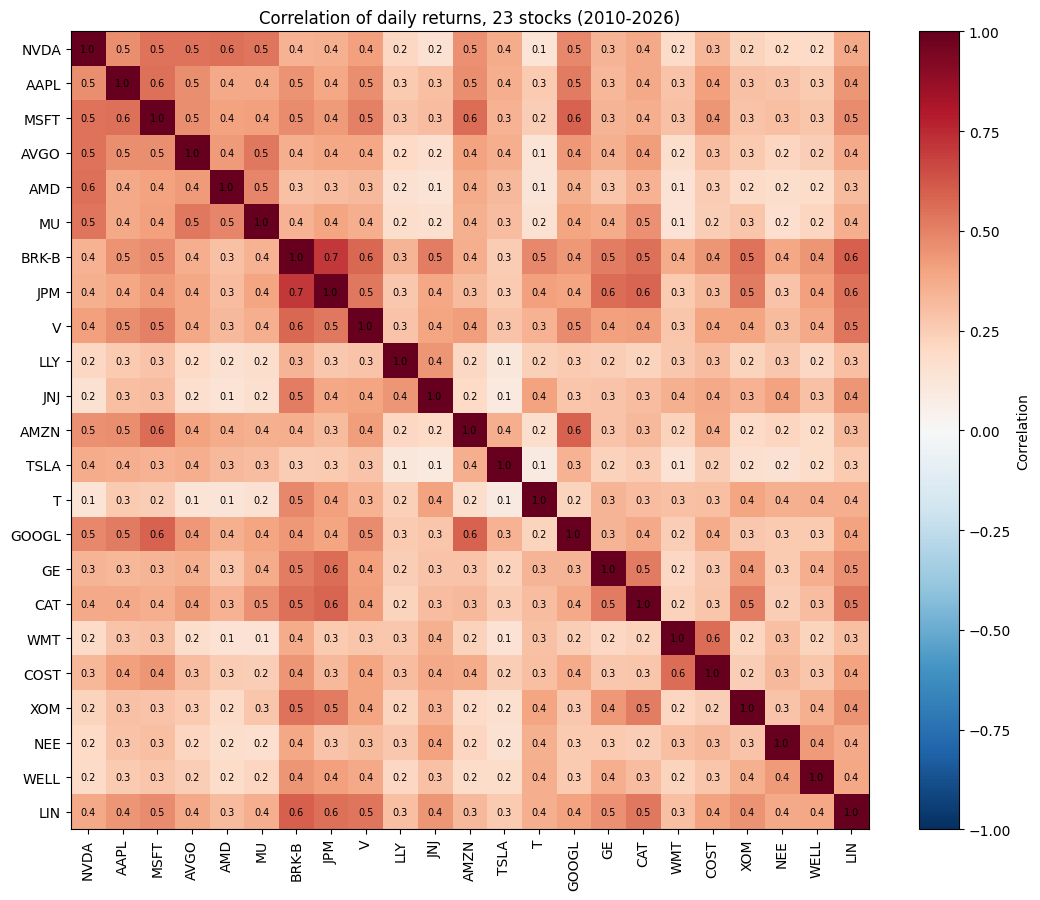

Average correlation between pairs of stocks: 0.34


In [5]:
# Heatmap of the correlations of daily returns
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlations.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(stocks)))
ax.set_xticklabels(stocks, rotation=90)
ax.set_yticks(range(len(stocks)))
ax.set_yticklabels(stocks)
for i in range(len(stocks)):
    for j in range(len(stocks)):
        ax.text(j, i, f'{correlations.values[i, j]:.1f}', ha='center', va='center', fontsize=7)
plt.colorbar(image, label='Correlation')
ax.set_title('Correlation of daily returns, 23 stocks (2010-2026)')
plt.tight_layout()
plt.savefig('../figures/04_universe_correlations.png', dpi=150)
plt.show()

print(f'Average correlation between pairs of stocks: {(correlations.values.sum() - len(stocks)) / (len(stocks) * (len(stocks) - 1)):.2f}')

### Risk-free rate: 3-year Treasury yield (FRED `DGS3`)

The code tries to read the file `data/risk_free_DGS3.csv`. If it does not exist yet, it downloads the series from FRED and saves it
(extraction date = the date on which this code is run; it is recorded in the file `data/risk_free_DGS3_info.txt`;
if the download fails and you download the CSV by hand, write down the download date).

- The series is in % per year (e.g. 4.25 = 4.25%) → we divide by 100.
- On days when the stock market is open but the bond market is closed (e.g. *Columbus Day*), we use the last known value.
- Daily rate = annual rate / 252.

Reading the risk-free rate from the local file: data/risk_free_DGS3.csv
Period of the rate: 1962-01-02 to 2026-10-06
Average rate over the period: 1.85% | minimum: 0.10% | maximum: 5.03%


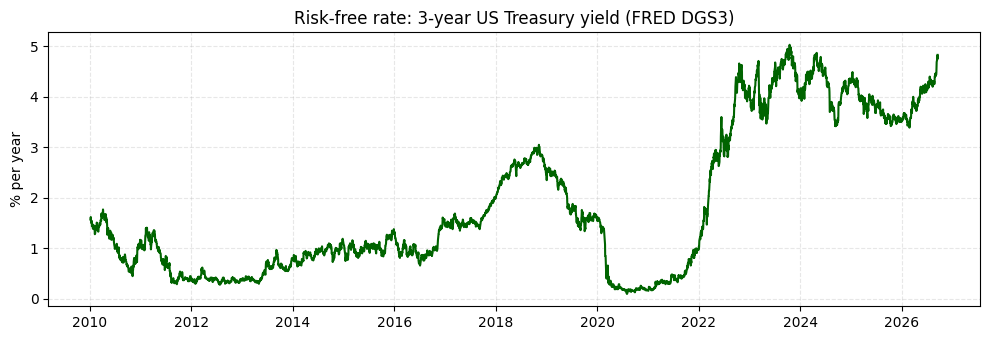

In [6]:
RF_FILE = 'data/risk_free_DGS3.csv'
FRED_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS3'

if os.path.exists(RF_FILE):
    print('Reading the risk-free rate from the local file:', RF_FILE)
    rate = pd.read_csv(RF_FILE, index_col=0, parse_dates=True, na_values='.')   # FRED uses '.' on days with no value
else:
    print('Downloading the DGS3 series from FRED...')
    try:
        rate = pd.read_csv(FRED_URL, index_col=0, parse_dates=True, na_values='.')
    except Exception as error:
        # This happens, for example, on networks with a proxy/firewall (university, company)
        print('Could not download from FRED:', error)
        print('SOLUTION: open this link in your browser (it downloads a CSV):', FRED_URL)
        print('and save the file as:', os.path.abspath(RF_FILE))
        print('Then run this cell again.')
        print("Write down today's date: it is the extraction date of the risk-free rate (the report must state the source and the date).")
        raise
    rate.to_csv(RF_FILE)
    with open('data/risk_free_DGS3_info.txt', 'w') as f:
        f.write(f'Source: {FRED_URL}\nExtracted on: {pd.Timestamp.today().date()}\n')

# Keep only the column with the values, convert from % to decimal and drop days with no value
rate = rate.iloc[:, 0] / 100
rate = rate.dropna()

# Align with the stock trading days (method='ffill' = use the last known value)
rf_annual = rate.reindex(returns.index, method='ffill')
rf_daily = rf_annual / DAYS_PER_YEAR

# Check: the rate must exist on EVERY day (otherwise the Sharpe ratio and Max Sharpe would be wrong)
if rf_annual.isna().sum() > 0:
    raise ValueError('The risk-free rate does not cover the whole stock period (it starts on ' + str(rate.index.min().date()) +
                     '). Delete ' + RF_FILE + ' and download the COMPLETE series from FRED.')

# Check: the real DGS3 series moves over time (about 0.1% in 2020-2021 and above 4% in 2023).
# A constant series means the file is not the real data (e.g. a test file).
if rf_annual.min() == rf_annual.max():
    raise ValueError('The risk-free rate is constant, so ' + RF_FILE + ' is not the real DGS3 series. '
                     'Delete it and run this cell again to download it from FRED.')

print('Period of the rate:', rate.index.min().date(), 'to', rate.index.max().date())
print(f'Average rate over the period: {rf_annual.mean():.2%} | minimum: {rf_annual.min():.2%} | maximum: {rf_annual.max():.2%}')

plt.figure(figsize=(10, 3.5))
plt.plot(rf_annual.index, rf_annual * 100, color='darkgreen')
plt.title('Risk-free rate: 3-year US Treasury yield (FRED DGS3)')
plt.ylabel('% per year')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/04_risk_free_rate.png', dpi=150)
plt.show()

## 3. The 8 strategies (and the Group pick)

Notation: $w$ = vector of weights, $\mu$ = annualised expected returns, $\Sigma$ = annualised covariance matrix,
$\sigma_i$ = volatility of asset *i*, $C$ = correlation matrix, $r_f$ = risk-free rate.
**Common constraints:** $w_i \ge 0$ and $\sum_i w_i = 1$.

| Strategy | Objective | Uses $\mu$? | Uses $\Sigma$? |
|---|---|---|---|
| EW | $w_i = 1/N$ | no | no |
| Markowitz (λ = 3) | $\max_w \; w^\top\mu - \frac{\lambda}{2}\, w^\top\Sigma w$ | yes | yes |
| GMV | $\min_w \; w^\top\Sigma w$ | no | yes |
| Max Sharpe | $\max_w \; (w^\top\mu - r_f)\,/\,\sqrt{w^\top\Sigma w}$ | yes | yes |
| Inverse vol | $w_i \propto 1/\sigma_i$ | no | only the diagonal |
| Risk parity (ERC) | equal risk contributions: $w_i(\Sigma w)_i / w^\top\Sigma w = 1/N$ | no | yes |
| Most diversified | $\max_w \; DR = w^\top\sigma \,/\, \sqrt{w^\top\Sigma w}$ | no | yes |
| Max decorrelation | $\min_w \; w^\top C\, w$ | no | only the correlations |

**Why is Markowitz different from GMV and Max Sharpe?** With λ = 3 the investor accepts some risk in exchange for return:
as λ → ∞ Markowitz gets closer to GMV; with a small λ it moves towards the asset with the highest expected return.
Max Sharpe is the point of the frontier that is tangent to the risk-free rate, which in general does not coincide with λ = 3 (see the chart in section 4).

**Inverse vol vs ERC:** both give more weight to the less volatile assets, but inverse vol **ignores correlations**.
They are only the same if all the correlations are equal. With different correlations, ERC gives less weight to the assets that are highly correlated with the others.

The optimisers use `scipy.optimize.minimize` with the **SLSQP** method (it accepts bounds and equality constraints).
If SLSQP reports a failure, the optimisation is repeated once with a looser tolerance (`ftol = 1e-8`); if it fails again,
equal weights are used at that rebalancing and the failure is recorded (`04_optimisation_failures.csv`, section 13).

In [7]:
def estimate_parameters(sample):
    # ANNUALISED mean (vector) and covariance (matrix) from daily returns
    mu = sample.mean().values * DAYS_PER_YEAR
    sigma = sample.cov().values * DAYS_PER_YEAR
    return mu, sigma


failure_log = []   # here we store the optimisations that fail (the brief asks us not to hide them)
retry_log = []     # optimisations that failed at the first attempt but worked at the second one


def optimise(objective_function, n_assets, name, initial_weights=None, min_weight=0.0):
    # Minimises 'objective_function' subject to: min_weight <= w_i <= 1 and sum of weights = 1
    if initial_weights is None:
        initial_weights = np.ones(n_assets) / n_assets          # start from equally weighted

    bounds = [(min_weight, 1)] * n_assets
    sum_constraint = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}

    # ftol = precision requested from the optimiser. With values that are too small (e.g. 1e-12) SLSQP sometimes
    # is already at the optimum but reports a failure; 1e-10 is precise and almost always converges.
    result = minimize(objective_function, initial_weights, method='SLSQP',
                      bounds=bounds, constraints=[sum_constraint],
                      options={'maxiter': 1000, 'ftol': 1e-10})

    if not result.success:
        retry_log.append({'Strategy': name, 'Message': result.message})   # first attempt failed
        # Second attempt with a slightly looser precision (1e-8). Sometimes SLSQP stops right next to the optimum
        # and reports a failure; whether that happens can depend on the computer / library version, so this retry
        # makes the results more stable across computers.
        result = minimize(objective_function, initial_weights, method='SLSQP',
                          bounds=bounds, constraints=[sum_constraint],
                          options={'maxiter': 1000, 'ftol': 1e-8})

    if not result.success:
        # Plan B: if it still fails, we use equally weighted and record the failure
        failure_log.append({'Strategy': name, 'Message': result.message})
        return np.ones(n_assets) / n_assets

    weights = np.clip(result.x, 0, None)   # remove tiny numerical negatives (e.g. -1e-15)
    return weights / weights.sum()

Each strategy is a function that receives the **estimation sample** (daily returns of the rolling window) and the **annual risk-free rate**
and returns a vector of weights. Note: in Python, `@` is the matrix product (e.g. `w @ sigma @ w` = $w^\top\Sigma w$ = portfolio variance).

In [8]:
# a) Equally weighted
def weights_equal_weight(sample, rf):
    n = sample.shape[1]
    return np.ones(n) / n


# b) Markowitz mean-variance with risk aversion lambda
def weights_markowitz(sample, rf, aversion=RISK_AVERSION):
    mu, sigma = estimate_parameters(sample)

    def objective(w):
        utility = w @ mu - aversion / 2 * (w @ sigma @ w)
        return -utility                     # minimising the negative = maximising the utility

    return optimise(objective, len(mu), 'Markowitz')


# c) Global minimum variance
def weights_min_variance(sample, rf):
    mu, sigma = estimate_parameters(sample)

    def objective(w):
        return w @ sigma @ w                # portfolio variance

    return optimise(objective, len(mu), 'GMV')


# d) Max Sharpe (tangency portfolio)
def weights_max_sharpe(sample, rf):
    mu, sigma = estimate_parameters(sample)

    def objective(w):
        sharpe = (w @ mu - rf) / np.sqrt(w @ sigma @ w)
        return -sharpe

    return optimise(objective, len(mu), 'Max Sharpe')

In [9]:
# e1) Inverse volatility (no optimiser needed)
def weights_inverse_vol(sample, rf):
    vol = sample.std().values
    return (1 / vol) / np.sum(1 / vol)


def risk_contributions(w, sigma):
    # Share of the total portfolio risk that comes from each asset (sum = 1)
    variance = w @ sigma @ w
    return w * (sigma @ w) / variance


# e2) Risk parity / Equal Risk Contribution
def weights_risk_parity(sample, rf):
    mu, sigma = estimate_parameters(sample)
    n = len(mu)

    def objective(w):
        # sum of the squared differences between each asset's contribution and 1/N
        return np.sum((risk_contributions(w, sigma) - 1 / n) ** 2)

    # We start from the inverse vol weights (already close to the solution) and force every weight to be > 0,
    # because in ERC every asset must contribute to the risk.
    start_weights = weights_inverse_vol(sample, rf)
    return optimise(objective, n, 'Risk parity (ERC)', initial_weights=start_weights, min_weight=1e-6)

In [10]:
def diversification_ratio(w, sigma):
    # DR = weighted average of the volatilities / portfolio volatility  (>= 1; higher = more diversified)
    vol = np.sqrt(np.diag(sigma))
    return (w @ vol) / np.sqrt(w @ sigma @ w)


# f1) Most diversified portfolio
def weights_most_diversified(sample, rf):
    mu, sigma = estimate_parameters(sample)

    def objective(w):
        return -diversification_ratio(w, sigma)

    return optimise(objective, len(mu), 'Most diversified')


# f2) Maximum decorrelation: it is the "minimum variance" but using the CORRELATION matrix
#     (as if every asset had the same volatility)
def weights_max_decorrelation(sample, rf):
    correlation = sample.corr().values

    def objective(w):
        return w @ correlation @ w

    return optimise(objective, correlation.shape[0], 'Max decorrelation')

### The Group pick (23 stocks): the group's own portfolio

Besides the 8 strategies of the brief, we test the portfolio that **the group itself chose**: the **23 S&P 500 stocks selected in notebook `01`**
(by GICS sector), **each with the same weight** — 1/23 ≈ 4.35% (1/22 ≈ 4.55% in the experiments whose 3-year window starts on or before
2010-06-29, when TSLA has no data yet). It is **rebalanced exactly like every other strategy**: semi-annual, the same warm-up rebalancing,
weights that drift between rebalancings, the same 10 bps cost on turnover, the same out-of-sample evaluation year and the same metrics.

**Why is it a different portfolio from strategy a) EW?** Both use equal weights (in the code they even use the same function, `weights_equal_weight`),
but they hold different stocks:

| | a) EW | Group pick (23 stocks) |
|---|---|---|
| Stocks held in each experiment | the **12 stocks drawn at random** for that experiment | **always the group's full 23-stock pick** (all the stocks with data in the period) |
| Weight of each stock | 1/12 ≈ 8.3% | 1/23 ≈ 4.35% (1/22 before TSLA has data) |
| What it tests | an **allocation rule** (1/N) applied to a given set of stocks | the group's **stock selection** |

So EW and the 7 optimised strategies answer *"how should we weight a given set of stocks?"*, while the Group pick answers
*"how good is our own pick of 23 stocks, held in equal weights?"*. The Group pick is one more portfolio in every comparison, next to the
8 strategies and SPY (10 portfolios in total).

In [11]:
# Dictionary with all the strategies: name -> function
strategies = {
    'EW': weights_equal_weight,
    'Markowitz (λ=3)': weights_markowitz,
    'GMV': weights_min_variance,
    'Max Sharpe': weights_max_sharpe,
    'Inverse vol': weights_inverse_vol,
    'Risk parity (ERC)': weights_risk_parity,
    'Most diversified': weights_most_diversified,
    'Max decorrelation': weights_max_decorrelation,
}

# The group's own portfolio: equal weights in ALL the 23 stocks (it uses the same function as EW, only the stocks change)
GROUP = 'Group pick (23 stocks)'

# Order and colours used in every chart: 8 strategies + Group pick + SPY = 10 portfolios (tab10 has 10 different colours)
order = list(strategies.keys()) + [GROUP, 'SPY (buy & hold)']
colours = dict(zip(order, plt.cm.tab10.colors))

## 4. Illustration: weights of each strategy with the last year of data (23 stocks)

Before the backtest, we look at what each strategy does with **all 23 stocks** and the last year of data
(as if we were rebalancing today). This helps to understand the differences between them.

In [12]:
illustration_sample = returns[stocks].iloc[-ESTIMATION_WINDOW:]      # last year (252 days)
illustration_rf = rf_annual.iloc[-1]
print('Sample:', illustration_sample.index.min().date(), 'to', illustration_sample.index.max().date(),
      f'| risk-free rate = {illustration_rf:.2%}')

illustration_weights = pd.DataFrame(index=stocks)
for name, function in strategies.items():
    illustration_weights[name] = function(illustration_sample, illustration_rf)

display((100 * illustration_weights).round(1))

Sample: 2025-09-18 to 2026-09-18 | risk-free rate = 4.83%


,EW,Markowitz (λ=3),GMV,Max Sharpe,Inverse vol,Risk parity (ERC),Most diversified,Max decorrelation
NVDA,4.3,0.0,5.7,0.0,3.2,3.2,4.1,5.5
AAPL,4.3,0.0,1.3,10.9,4.8,3.8,1.1,1.0
MSFT,4.3,0.0,5.4,2.4,3.7,4.8,6.5,7.5
AVGO,4.3,0.0,2.7,0.0,2.6,2.6,3.6,5.9
AMD,4.3,12.1,0.0,4.3,1.7,1.5,1.4,3.6
MU,4.3,76.3,2.1,9.1,1.5,1.8,3.1,8.9
BRK-B,4.3,0.0,22.0,1.5,8.2,8.1,9.3,4.8
JPM,4.3,0.0,0.8,0.0,5.4,3.7,0.0,0.0
V,4.3,0.0,3.0,2.4,5.4,5.3,5.9,4.6
LLY,4.3,0.0,0.0,0.9,3.4,3.2,4.1,5.2


**Note on the Group pick.** In this illustration we use the full 23-stock universe, so the Group pick's weights (1/23 ≈ 4.35% in every stock)
are **exactly the EW weights** (the `EW` column above). The two portfolios only differ in the backtest: there, EW is applied to the
**12 randomly drawn stocks** of each experiment, while the Group pick always holds **all 23** (22 before TSLA has data).
So any difference between EW and the Group pick in the backtest comes from the **universe** (fixed 23 vs random 12), not from the weighting rule.

In [13]:
# Check: on the 23 stocks, the Group pick (1/23 in each stock) has exactly the same weights as EW
group_pick_weights = np.ones(len(stocks)) / len(stocks)
print(f'Group pick weight per stock: {group_pick_weights[0]:.2%}')
print('Same weights as EW on the 23 stocks?', np.allclose(group_pick_weights, illustration_weights['EW'].values))

Group pick weight per stock: 4.35%
Same weights as EW on the 23 stocks? True


In [14]:
# Ex-ante (in-sample) characteristics of each portfolio
mu_illus, sigma_illus = estimate_parameters(illustration_sample)

rows = []
for name in strategies.keys():
    w = illustration_weights[name].values
    exp_return = w @ mu_illus
    vol = np.sqrt(w @ sigma_illus @ w)
    rows.append({
        'Strategy': name,
        'Exp. return': exp_return,
        'Volatility': vol,
        'Sharpe (ex-ante)': (exp_return - illustration_rf) / vol,
        'Effective N (1/Σw²)': 1 / np.sum(w ** 2),
        'Max weight': w.max(),
        'N assets with w > 1%': int(np.sum(w > 0.01)),
        'Diversification ratio': diversification_ratio(w, sigma_illus),
    })

characteristics = pd.DataFrame(rows).set_index('Strategy')
display(characteristics.round(3))

,Exp. return,Volatility,Sharpe (ex-ante),Effective N (1/Σw²),Max weight,N assets with w > 1%,Diversification ratio
Strategy,,,,,,,
EW,0.349,0.128,2.348,23.000,0.043,23,2.559
Markowitz (λ=3),1.903,0.672,2.758,1.639,0.763,3,1.089
GMV,0.214,0.076,2.172,9.868,0.220,17,3.208
Max Sharpe,0.607,0.118,4.718,5.176,0.335,10,2.583
Inverse vol,0.243,0.093,2.082,20.252,0.082,23,2.957
Risk parity (ERC),0.247,0.084,2.351,18.437,0.105,23,3.270
Most diversified,0.262,0.082,2.602,13.726,0.153,19,3.455
Max decorrelation,0.418,0.126,2.941,14.915,0.140,19,2.755


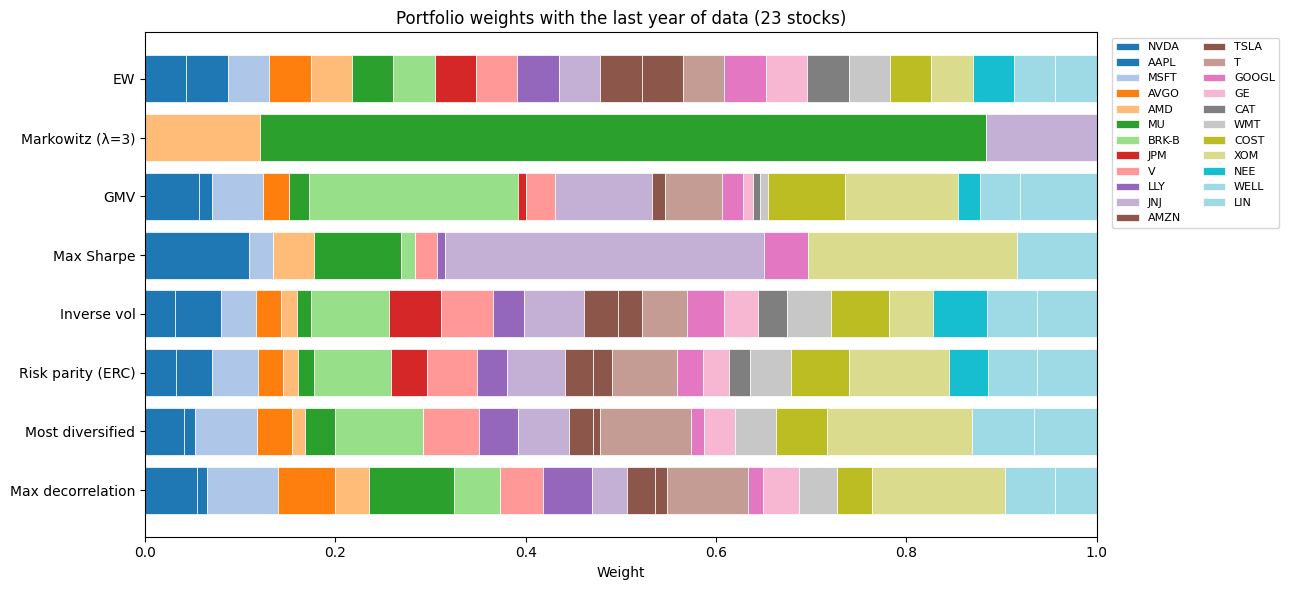

In [15]:
# Chart of the weights (one horizontal bar per strategy, stacked by stock)
fig, ax = plt.subplots(figsize=(13, 6))
left = np.zeros(len(strategies))
stock_colours = plt.cm.tab20(np.linspace(0, 1, len(stocks)))

for i, stock in enumerate(stocks):
    values = illustration_weights.loc[stock].values
    ax.barh(list(strategies.keys()), values, left=left, color=stock_colours[i], label=stock, edgecolor='white', linewidth=0.5)
    left = left + values

ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel('Weight')
ax.set_title('Portfolio weights with the last year of data (23 stocks)')
ax.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('../figures/04_weights_illustration.png', dpi=150)
plt.show()

### Inverse vol vs Risk parity (ERC): risk contributions

In inverse vol the **weights** are proportional to $1/\sigma_i$, but the **contributions to risk** are not equal,
because the assets that are more correlated with the rest of the portfolio contribute more. ERC corrects this.

,Weight IV,Risk contrib. IV,Weight ERC,Risk contrib. ERC,Avg. correlation with others
GOOGL,3.82,6.61,2.78,4.35,13.64
GE,3.63,6.60,2.77,4.35,13.62
CAT,3.01,6.52,2.15,4.35,13.38
JPM,5.44,6.52,3.69,4.35,13.40
TSLA,2.59,5.78,2.04,4.35,11.35
NEE,5.66,5.63,4.02,4.35,10.93
AAPL,4.81,5.41,3.77,4.35,10.34
AMZN,3.49,5.35,2.98,4.35,10.16
AMD,1.67,5.00,1.53,4.35,9.21
LLY,3.36,4.48,3.17,4.35,7.77


Standard deviation of the risk contributions -> IV: 0.0174 | ERC: 0.000001


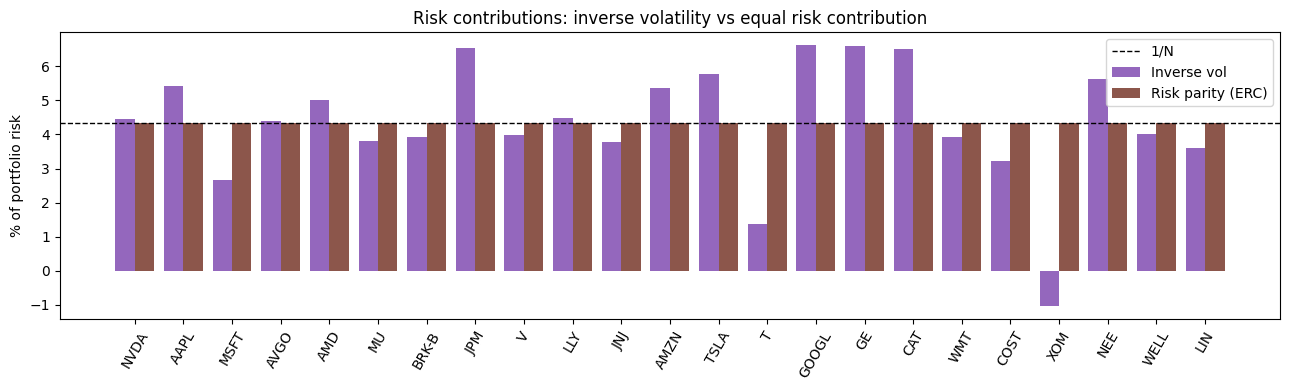

In [16]:
rc_iv = risk_contributions(illustration_weights['Inverse vol'].values, sigma_illus)
rc_erc = risk_contributions(illustration_weights['Risk parity (ERC)'].values, sigma_illus)

rc_table = pd.DataFrame({
    'Weight IV': illustration_weights['Inverse vol'],
    'Risk contrib. IV': rc_iv,
    'Weight ERC': illustration_weights['Risk parity (ERC)'],
    'Risk contrib. ERC': rc_erc,
    'Avg. correlation with others': (illustration_sample.corr().sum() - 1) / (len(stocks) - 1),
})
display((rc_table * 100).round(2).sort_values('Risk contrib. IV', ascending=False))
print(f'Standard deviation of the risk contributions -> IV: {rc_iv.std():.4f} | ERC: {rc_erc.std():.6f}')

x = np.arange(len(stocks))
plt.figure(figsize=(13, 4))
plt.bar(x - 0.2, rc_iv * 100, width=0.4, label='Inverse vol', color=colours['Inverse vol'])
plt.bar(x + 0.2, rc_erc * 100, width=0.4, label='Risk parity (ERC)', color=colours['Risk parity (ERC)'])
plt.axhline(100 / len(stocks), color='black', linestyle='--', linewidth=1, label='1/N')
plt.xticks(x, stocks, rotation=60)
plt.ylabel('% of portfolio risk')
plt.title('Risk contributions: inverse volatility vs equal risk contribution')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/04_risk_contributions_iv_vs_erc.png', dpi=150)
plt.show()

### Efficient frontier (in-sample)

We compute the long-only frontier: for each target return, the portfolio with the lowest variance. We mark the 8 strategies
and Markowitz with λ = 1, 3 and 5 to show that it is different from GMV and Max Sharpe.

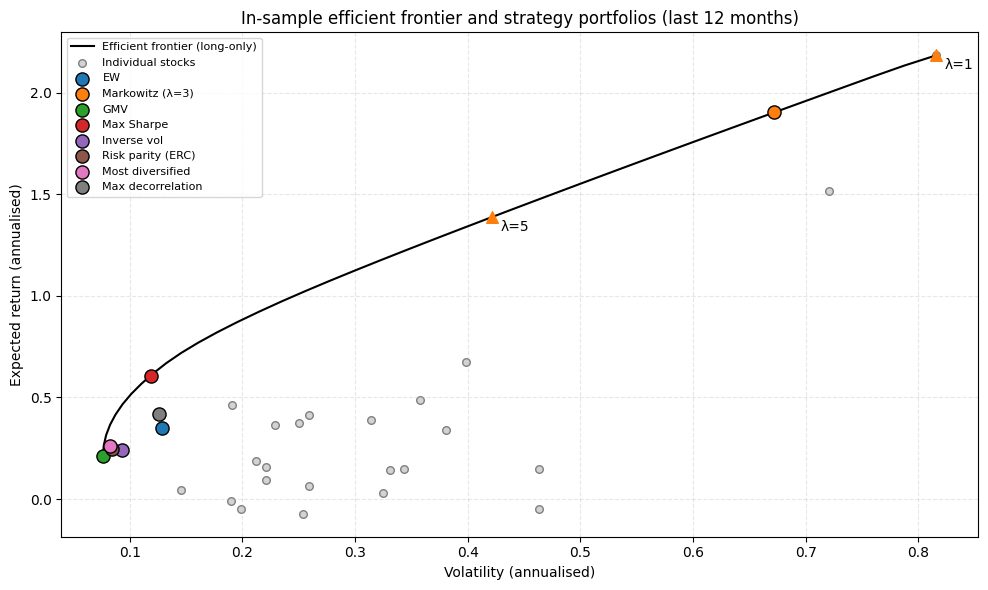

In [17]:
n = len(stocks)
gmv_return = illustration_weights['GMV'].values @ mu_illus
targets = np.linspace(gmv_return, mu_illus.max(), 40)

frontier_vol = []
for target in targets:
    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
                   {'type': 'eq', 'fun': lambda w: w @ mu_illus - target}]     # portfolio return = target
    res = minimize(lambda w: w @ sigma_illus @ w, np.ones(n) / n, method='SLSQP',
                   bounds=[(0, 1)] * n, constraints=constraints, options={'maxiter': 1000})
    frontier_vol.append(np.sqrt(res.fun))

plt.figure(figsize=(10, 6))
plt.plot(frontier_vol, targets, color='black', linewidth=1.5, label='Efficient frontier (long-only)')
plt.scatter(np.sqrt(np.diag(sigma_illus)), mu_illus, color='lightgrey', edgecolor='grey', s=30, label='Individual stocks')

for name in strategies.keys():
    w = illustration_weights[name].values
    plt.scatter(np.sqrt(w @ sigma_illus @ w), w @ mu_illus, color=colours[name], s=90, edgecolor='black', zorder=3, label=name)

for aversion in [1, 5]:
    w = weights_markowitz(illustration_sample, illustration_rf, aversion=aversion)
    plt.scatter(np.sqrt(w @ sigma_illus @ w), w @ mu_illus, color=colours['Markowitz (λ=3)'], marker='^', s=70, zorder=3)
    plt.annotate(f'λ={aversion}', (np.sqrt(w @ sigma_illus @ w), w @ mu_illus), textcoords='offset points', xytext=(6, -10))

plt.xlabel('Volatility (annualised)')
plt.ylabel('Expected return (annualised)')
plt.title('In-sample efficient frontier and strategy portfolios (last 12 months)')
plt.legend(fontsize=8, loc='best')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/04_efficient_frontier.png', dpi=150)
plt.show()

**Warning:** this illustration is **in-sample** — it uses 1-year historical means as if they were the future.
The strategies that depend on $\mu$ (Markowitz and Max Sharpe) concentrate on the stocks that rose the most in the last year.
That is exactly why we need the out-of-sample backtest: to see whether this apparent advantage holds in the following year.

## 5. Design of the 100 experiments

For each experiment we draw:
1. **One contiguous 3-year period** (756 trading days) within 2010–2026 — the chronological order is kept;
2. **12 stocks** among those with complete data in that period (*eligibility*: TSLA is only eligible in periods that start after 29/06/2010).

We use the **same** sample (period + stocks) for every strategy, and the seed is recorded → the result is reproducible.

**The Group pick** uses the **same 100 periods** (the same `start_index`), but it does not draw stocks: it always holds **all the eligible stocks**
of the period (23, or 22 when the 3-year window starts on or before 2010-06-29, because TSLA has no data yet). Its design table, `design_all`,
is built right after the main one **without any random call**, so the random draws of the 100 experiments are exactly the same as before.

In [18]:
# np.random.seed: with the same seed, NumPy guarantees the same sequence of numbers on any version/computer
np.random.seed(SEED)
dates = returns.index
n_days = len(dates)

rows = []
for e in range(1, N_EXPERIMENTS + 1):
    # 1) draw the first day of the 3-year period (the whole period must fit inside the data)
    start = int(np.random.randint(0, n_days - DATASET_DAYS + 1))
    end = start + DATASET_DAYS                        # exclusive

    # 2) eligible stocks = no missing values in the period
    block = returns[stocks].iloc[start:end]
    eligible = [stock for stock in stocks if block[stock].notna().all()]

    # 3) draw 12 stocks (without replacement)
    chosen = sorted(str(a) for a in np.random.choice(eligible, size=N_ASSETS, replace=False))

    rows.append({
        'Experiment': e,
        'start_index': start,
        'Estimation start': dates[start].date(),
        'Evaluation start': dates[start + EVAL_START].date(),
        'Evaluation end': dates[end - 1].date(),
        'N eligible': len(eligible),
        'Assets': chosen,
    })

design = pd.DataFrame(rows).set_index('Experiment')
display(design.head(10))
print('Experiments in which TSLA was not eligible:', (design['N eligible'] < len(stocks)).sum())

,start_index,Estimation start,Evaluation start,Evaluation end,N eligible,Assets
Experiment,,,,,,
1,2305,2019-03-05,2021-03-04,2022-03-02,23,"[AAPL, AMD, AVGO, CAT, COST, GE, GOOGL, JNJ, J..."
2,1011,2014-01-10,2016-01-12,2017-01-10,23,"[AAPL, AMD, AMZN, AVGO, COST, GOOGL, JNJ, JPM,..."
3,3288,2023-01-27,2025-01-31,2026-02-02,23,"[AAPL, AMD, GOOGL, JNJ, JPM, LIN, MSFT, NEE, V..."
4,2114,2018-05-30,2020-06-01,2021-05-28,23,"[AMD, BRK-B, COST, JNJ, JPM, LLY, MSFT, MU, T,..."
5,789,2013-02-25,2015-02-25,2016-02-24,23,"[AMD, AMZN, BRK-B, COST, GOOGL, JNJ, JPM, LLY,..."
6,1497,2015-12-15,2017-12-14,2018-12-14,23,"[CAT, COST, GE, JPM, LLY, MSFT, NEE, NVDA, T, ..."
7,605,2012-05-30,2014-06-03,2015-06-02,23,"[AMD, AMZN, AVGO, CAT, GOOGL, MSFT, MU, NEE, T..."
8,2841,2021-04-20,2023-04-20,2024-04-19,23,"[BRK-B, CAT, GE, JNJ, JPM, LLY, MSFT, MU, NEE,..."
9,2116,2018-06-01,2020-06-03,2021-06-02,23,"[AAPL, AVGO, CAT, GE, GOOGL, JNJ, JPM, MU, NVD..."


Experiments in which TSLA was not eligible: 6


In [19]:
# Design of the Group pick: the SAME experiments and periods (start_index), but ALL the eligible stocks of the period.
# There is no random call here, so the draws above (periods and 12 stocks) do not change.
rows = []
for e in design.index:
    start = design.loc[e, 'start_index']
    block = returns[stocks].iloc[start:start + DATASET_DAYS]
    eligible = [stock for stock in stocks if block[stock].notna().all()]
    rows.append({'Experiment': e, 'start_index': start, 'Assets': eligible})
design_all = pd.DataFrame(rows).set_index('Experiment')

n_held = design_all['Assets'].apply(len)
print('Number of stocks held by the Group pick -> number of experiments:', n_held.value_counts().sort_index().to_dict())
print('Experiments with 22 stocks (window starts on or before 2010-06-29, no TSLA):',
      [(e, str(design.loc[e, 'Estimation start'])) for e in design_all.index if n_held[e] < len(stocks)])

Number of stocks held by the Group pick -> number of experiments: {22: 6, 23: 94}
Experiments with 22 stocks (window starts on or before 2010-06-29, no TSLA): [(18, '2010-01-22'), (19, '2010-04-08'), (24, '2010-05-10'), (25, '2010-03-23'), (71, '2010-06-17'), (92, '2010-04-12')]


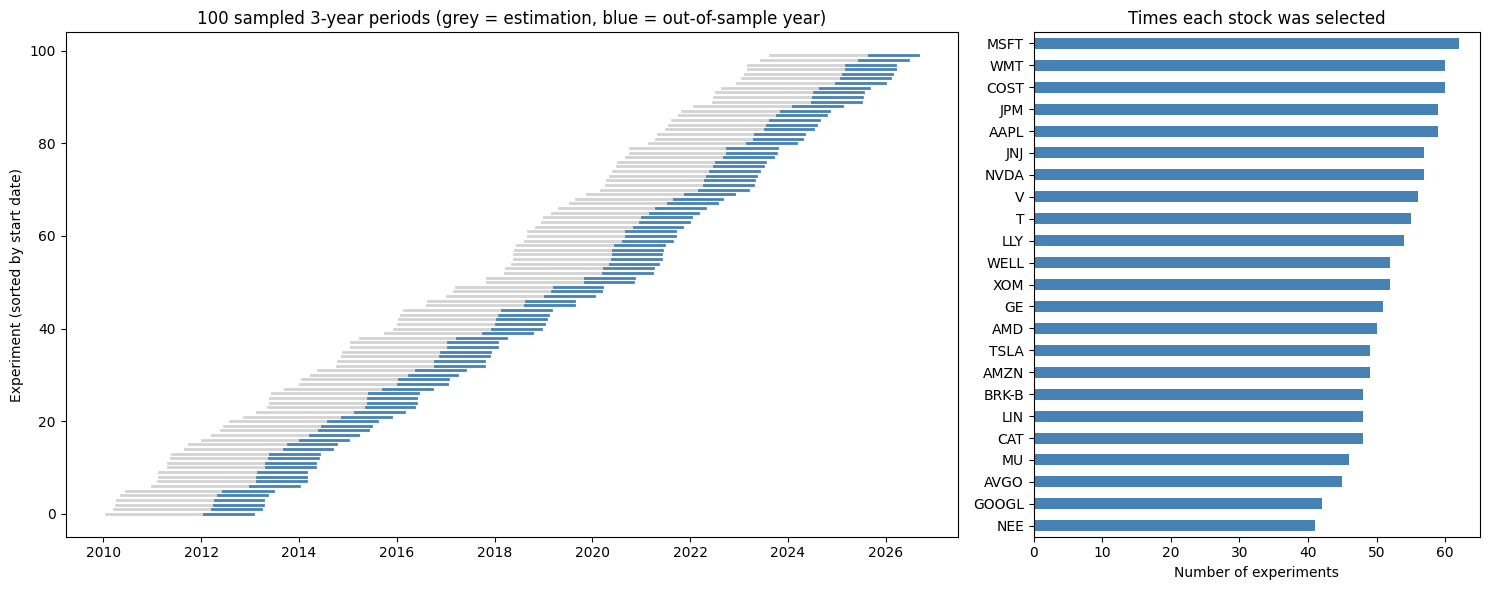

In [20]:
# Chart 1: sampled periods (grey = estimation, blue = evaluation)
sorted_design = design.sort_values('start_index')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [2, 1]})
for y, (e, row) in enumerate(sorted_design.iterrows()):
    axes[0].plot([row['Estimation start'], row['Evaluation start']], [y, y], color='lightgrey', linewidth=2)
    axes[0].plot([row['Evaluation start'], row['Evaluation end']], [y, y], color='steelblue', linewidth=2)
axes[0].set_title('100 sampled 3-year periods (grey = estimation, blue = out-of-sample year)')
axes[0].set_ylabel('Experiment (sorted by start date)')

# Chart 2: how many times each stock was drawn
selection_count = pd.Series(0, index=stocks)
for asset_list in design['Assets']:
    for stock in asset_list:
        selection_count[stock] += 1
selection_count.sort_values().plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Times each stock was selected')
axes[1].set_xlabel('Number of experiments')

plt.tight_layout()
plt.savefig('../figures/04_experiment_design.png', dpi=150)
plt.show()

**Important note:** the sampled periods **overlap** (there are only ~16 years of data, so there are at most ~14 different evaluation years).
The 100 experiments **are not 100 independent tests** — they are used to look at the **distribution** of the results and at whether the conclusions
depend on the period or on the stocks drawn, and not to run significance tests as if they were independent.

## 6. Simulating one strategy in one experiment

For each experiment and strategy:

1. **Rebalancing dates:** every 126 days. The first one is **one semester before** the start of the evaluation (warm-up):
   this way, on the 1st evaluation day the portfolio already exists and the turnover on that day is realistic (it is not a purchase made from cash).
   The warm-up returns are **not** included in the metrics.
2. At each rebalancing, the weights are computed **using only the previous 252 days** (no look-ahead).
   Trades are made at the close of the previous day, i.e. the new weights apply from day *t* onwards
   (*market-on-close* convention: we trade at the closing price of the day on which we know the last observation).
3. **Turnover** = $\sum_i |w_i^{target} - w_i^{before}|$ (purchases + sales, as a % of the portfolio).
4. Between rebalancings the weights **drift**: $w_{i,t+1} = w_{i,t}(1+R_{i,t}) / (1+R_{p,t})$.
5. **Net return** on the rebalancing day = gross return − cost × turnover.

In [21]:
def simulate(block_returns, rf_block, weight_function, interval=REBALANCE_INTERVAL, window=ESTIMATION_WINDOW):
    # block_returns: DataFrame with 756 days x 12 stocks (simple returns)
    # rf_block: Series with 756 days of ANNUAL risk-free rate
    # Returns a dictionary with the gross returns and the turnover of each day of the evaluation year,
    # and the target weights / diversification ratio of each rebalancing in the evaluation year.
    R = block_returns.values                 # numpy is faster inside a loop
    n_assets = R.shape[1]

    # Rebalancing days (the 1st is one interval before the start of the evaluation = warm-up)
    rebalance_days = list(range(EVAL_START - interval, DATASET_DAYS, interval))
    if rebalance_days[0] - window < 0:
        raise ValueError('The estimation window does not fit before the 1st rebalancing')

    weights = np.zeros(n_assets)            # we start in cash
    gross_returns = []
    daily_turnover = []
    target_weights = []
    div_ratios = []

    for t in range(rebalance_days[0], DATASET_DAYS):
        turnover = 0.0

        if t in rebalance_days:
            # 1) estimate using only PAST data (days t-window to t-1)
            sample = block_returns.iloc[t - window:t]
            known_rf = rf_block.iloc[t - 1]
            n_failures_before = len(failure_log)
            target = weight_function(sample, known_rf)
            for failure in failure_log[n_failures_before:]:          # if the optimisation failed, store the date
                failure['Rebalance date'] = block_returns.index[t].date()

            # 2) how much we need to trade to move from the current weights to the target
            turnover = np.sum(np.abs(target - weights))
            weights = target

            if t >= EVAL_START:
                target_weights.append(target)
                div_ratios.append(diversification_ratio(target, sample.cov().values))

        # 3) portfolio return on day t
        r_portfolio = np.sum(weights * R[t])

        # 4) the weights drift with prices until the next rebalancing
        weights = weights * (1 + R[t]) / (1 + r_portfolio)

        # 5) we only store the evaluation year
        if t >= EVAL_START:
            gross_returns.append(r_portfolio)
            daily_turnover.append(turnover)

    eval_dates = block_returns.index[EVAL_START:]
    return {
        'r_gross': pd.Series(gross_returns, index=eval_dates),
        'turnover': pd.Series(daily_turnover, index=eval_dates),
        'weights': target_weights,
        'div_ratio': div_ratios,
    }

## 7. Performance metrics (conventions)

Computed on the **daily** returns of the evaluation year (252 days):

| Metric | Formula / convention |
|---|---|
| Annualised return | $\left(\prod_t (1+R_t)\right)^{252/n} - 1$ (geometric) |
| Annualised volatility | $\text{standard deviation}(R_t)\times\sqrt{252}$ |
| Sharpe | $\overline{(R_t - r_{f,t})} \,/\, \text{sd}(R_t - r_{f,t}) \times \sqrt{252}$ |
| Sortino | $\overline{(R_t - r_{f,t})} \,/\, DD \times \sqrt{252}$, with $DD = \sqrt{\text{mean}(\min(R_t - r_{f,t}, 0)^2)}$ |
| Maximum drawdown (MDD) | largest fall from a previous peak of wealth (which starts at 1) |
| Calmar | annualised return / \|MDD\| |
| Sterling | annualised return / (\|MDD\| + 10%) — original version; with 1 evaluation year the "average annual MDD" is the MDD of that year |
| Annual turnover | sum of the turnover of the rebalancings in the evaluation year |
| Cost drag | gross annualised return − net annualised return |
| Effective N | $1/\sum_i w_i^2$ (average across rebalancings): N = equal weights (12 for the 8 strategies, 22–23 for the Group pick), 1 = everything in one stock |
| Max weight | largest target weight in the portfolio (average across rebalancings) |
| Diversification ratio (ex-ante) | $w^\top\sigma / \sqrt{w^\top\Sigma w}$ computed with the **estimation sample** (the 252 days before the rebalancing), averaged across rebalancings. It is an *ex-ante* (in-sample) measure, not an out-of-sample result — *Most diversified* has the highest value by construction |

The ratios use the **risk-free rate of each day** (Sharpe, Sortino). Calmar and Sterling use the annualised return (without subtracting the risk-free rate), as in the original definitions.

In [22]:
def compute_metrics(r, rf_d):
    # r: daily portfolio returns | rf_d: daily risk-free rate on the same dates
    excess = r - rf_d
    n = len(r)

    wealth = (1 + r).cumprod()
    ann_return = wealth.iloc[-1] ** (DAYS_PER_YEAR / n) - 1
    ann_vol = r.std() * np.sqrt(DAYS_PER_YEAR)

    sharpe = excess.mean() / excess.std() * np.sqrt(DAYS_PER_YEAR)

    downside_dev = np.sqrt(np.mean(np.minimum(excess, 0) ** 2))
    sortino = excess.mean() / downside_dev * np.sqrt(DAYS_PER_YEAR)

    # Drawdown: we include the initial value 1 so that a fall on the very 1st day is counted
    wealth_with_start = np.concatenate([[1.0], wealth.values])
    running_max = np.maximum.accumulate(wealth_with_start)
    drawdown = wealth_with_start / running_max - 1
    mdd = drawdown.min()                                    # negative number

    calmar = ann_return / abs(mdd) if mdd < 0 else np.nan
    sterling = ann_return / (abs(mdd) + 0.10)

    return {
        'Ann. return': ann_return,
        'Ann. volatility': ann_vol,
        'Sharpe': sharpe,
        'Sortino': sortino,
        'Max drawdown': mdd,
        'Calmar': calmar,
        'Sterling': sterling,
    }

In [23]:
def metrics_table(simulations, cost, design_table=None):
    # Turns the simulations into a table: one row per (experiment, strategy)
    # design_table: by default uses the main design of the experiments
    if design_table is None:
        design_table = design

    rows = []
    for (e, name), sim in simulations.items():
        rf_d = rf_daily.loc[sim['r_gross'].index]

        r_net = sim['r_gross'] - cost * sim['turnover']
        m_net = compute_metrics(r_net, rf_d)
        m_gross = compute_metrics(sim['r_gross'], rf_d)

        row = {'Experiment': e, 'Strategy': name}
        row.update(m_net)                                  # metrics net of costs
        row['Ann. return (gross)'] = m_gross['Ann. return']
        row['Sharpe (gross)'] = m_gross['Sharpe']
        row['Cost drag'] = m_gross['Ann. return'] - m_net['Ann. return']
        row['Turnover (annual)'] = sim['turnover'].sum()
        row['Effective N'] = np.mean([1 / np.sum(w ** 2) for w in sim['weights']])
        row['Max weight'] = np.mean([w.max() for w in sim['weights']])
        row['Diversification ratio (ex-ante)'] = np.mean(sim['div_ratio'])
        rows.append(row)

    # Market benchmark: SPY bought at the start of the evaluation year and held (no rebalancing costs)
    for e in design_table.index:
        start = design_table.loc[e, 'start_index']
        eval_dates = returns.index[start + EVAL_START: start + DATASET_DAYS]
        m_spy = compute_metrics(returns.loc[eval_dates, 'SPY'], rf_daily.loc[eval_dates])
        row = {'Experiment': e, 'Strategy': 'SPY (buy & hold)'}
        row.update(m_spy)
        row['Ann. return (gross)'] = m_spy['Ann. return']
        row['Sharpe (gross)'] = m_spy['Sharpe']
        row['Cost drag'] = 0.0
        row['Turnover (annual)'] = 0.0
        rows.append(row)

    return pd.DataFrame(rows)


def run_backtest(strategy_dict, interval=REBALANCE_INTERVAL, design_table=None, run_name='Main'):
    # Runs every strategy in every experiment. Returns a dictionary (experiment, strategy) -> simulation
    # run_name: identifies this run in the optimisation failure log
    if design_table is None:
        design_table = design

    simulations = {}
    for e in design_table.index:
        start = design_table.loc[e, 'start_index']
        assets_e = design_table.loc[e, 'Assets']
        block = returns[assets_e].iloc[start:start + DATASET_DAYS]
        rf_block = rf_annual.iloc[start:start + DATASET_DAYS]

        for name, function in strategy_dict.items():
            n_failures_before = len(failure_log)
            simulations[(e, name)] = simulate(block, rf_block, function, interval=interval)
            for failure in failure_log[n_failures_before:]:       # identify the failures of this simulation
                failure['Run'] = run_name
                failure['Experiment'] = e
                failure['Strategy'] = name                        # full name, e.g. 'Markowitz (λ=1)'
    return simulations


def show_failures(run_name):
    # Shows the optimisations that failed in one run (on those rebalancings we used equal weights)
    failures = [f for f in failure_log if f.get('Run') == run_name]
    print(f'Optimisations that failed ({run_name}): {len(failures)}')
    if len(failures) > 0:
        display(pd.DataFrame(failures))

## 8. Running the main backtest (semi-annual rebalancing, 10 bps)

1. The 8 strategies run on the 100 experiments of `design` (12 random stocks each).
2. The **Group pick** runs on the same 100 experiments with `design_all`: the same periods, the same rebalancing dates, warm-up, costs and
   evaluation year, but **all the eligible stocks** (23, or 22 before TSLA) in equal weights. It is a different portfolio from EW,
   which holds only the 12 drawn stocks (see section 3).
3. The Group pick simulations are merged into `simulations`, so every table and chart below has **10 portfolios**
   (8 strategies + Group pick + SPY).

In [24]:
import time
clock_start = time.time()

# 1) The 8 strategies on the 12 stocks drawn in each experiment
simulations = run_backtest(strategies, run_name='Main (semi-annual)')

# 2) The Group pick: the same equal-weight function, applied to ALL the eligible stocks of the same periods (design_all)
group_simulations = run_backtest({GROUP: weights_equal_weight}, design_table=design_all, run_name='Main (semi-annual)')

# 3) Merge: 'simulations' now has 9 portfolios x 100 experiments (SPY is added by metrics_table)
simulations.update(group_simulations)
results = metrics_table(simulations, COST)

print(f'Backtest finished in {time.time() - clock_start:.0f} seconds')
print('Number of simulations:', len(simulations), '| rows in the table (including SPY):', len(results))
show_failures('Main (semi-annual)')

Backtest finished in 23 seconds
Number of simulations: 900 | rows in the table (including SPY): 1000
Optimisations that failed (Main (semi-annual)): 0


In [25]:
display(results.head(10).round(4))

,Experiment,Strategy,Ann. return,Ann. volatility,Sharpe,Sortino,Max drawdown,Calmar,Sterling,Ann. return (gross),Sharpe (gross),Cost drag,Turnover (annual),Effective N,Max weight,Diversification ratio (ex-ante)
0,1,EW,0.1819,0.1537,1.1208,1.6546,-0.1178,1.5447,0.8354,0.1824,1.1232,0.0004,0.3444,12.0000,0.0833,1.5725
1,1,Markowitz (λ=3),0.0485,0.2012,0.3025,0.4255,-0.1637,0.2961,0.1838,0.0517,0.3181,0.0033,3.0622,2.9268,0.5199,1.3445
2,1,GMV,0.2853,0.1299,1.9466,3.0463,-0.0890,3.2062,1.5098,0.2865,1.9544,0.0012,0.9212,3.5169,0.4194,1.4100
3,1,Max Sharpe,0.1551,0.1676,0.9045,1.3407,-0.1242,1.2494,0.6921,0.1587,0.9237,0.0036,3.0561,4.1400,0.3633,1.5617
4,1,Inverse vol,0.1958,0.1402,1.2981,1.9409,-0.1049,1.8666,0.9557,0.1964,1.3016,0.0005,0.4528,11.0993,0.1306,1.5622
5,1,Risk parity (ERC),0.1926,0.1397,1.2825,1.9192,-0.1050,1.8343,0.9394,0.1931,1.2859,0.0005,0.4364,11.1153,0.1277,1.5945
6,1,Most diversified,0.1887,0.1589,1.1249,1.7193,-0.1241,1.5199,0.8418,0.1902,1.1335,0.0016,1.3090,5.9359,0.2831,1.6812
7,1,Max decorrelation,0.1697,0.1778,0.9330,1.4152,-0.1391,1.2200,0.7098,0.1711,0.9399,0.0014,1.1749,6.1404,0.2243,1.6589
8,2,EW,0.6302,0.1815,2.7297,4.1756,-0.0985,6.3989,3.1750,0.6308,2.7317,0.0006,0.3543,12.0000,0.0833,1.5786
9,2,Markowitz (λ=3),1.4932,0.4341,2.2910,4.4400,-0.2413,6.1894,4.3756,1.5029,2.3002,0.0097,3.8598,1.2527,0.8933,1.1283


## 9. Results across the 100 experiments

### 9.1 Median of each metric (net of costs, 10 bps)

One row per portfolio: the 8 strategies, the Group pick and SPY. Note that the Group pick's effective N is 22–23 (it holds every eligible stock),
while the 8 strategies hold at most 12 stocks.

In [26]:
summary_columns = ['Ann. return', 'Ann. volatility', 'Sharpe', 'Sortino', 'Max drawdown', 'Calmar', 'Sterling',
                   'Ann. return (gross)', 'Sharpe (gross)', 'Cost drag', 'Turnover (annual)',
                   'Effective N', 'Max weight', 'Diversification ratio (ex-ante)']

medians = results.groupby('Strategy')[summary_columns].median().loc[order]
display(medians.round(3))

,Ann. return,Ann. volatility,Sharpe,Sortino,Max drawdown,Calmar,Sterling,Ann. return (gross),Sharpe (gross),Cost drag,Turnover (annual),Effective N,Max weight,Diversification ratio (ex-ante)
Strategy,,,,,,,,,,,,,,
EW,0.312,0.169,1.806,2.726,-0.111,3.297,1.680,0.312,1.808,0.000,0.274,12.000,0.083,1.632
Markowitz (λ=3),0.398,0.345,1.232,1.874,-0.235,2.095,1.372,0.401,1.241,0.003,2.215,1.501,0.769,1.114
GMV,0.173,0.128,1.338,1.900,-0.098,2.012,0.934,0.174,1.349,0.001,0.945,4.435,0.350,1.547
Max Sharpe,0.279,0.208,1.288,2.016,-0.144,2.187,1.284,0.283,1.305,0.003,2.135,2.769,0.496,1.404
Inverse vol,0.257,0.147,1.777,2.641,-0.098,3.156,1.470,0.257,1.779,0.000,0.273,10.900,0.128,1.636
Risk parity (ERC),0.265,0.144,1.801,2.708,-0.100,3.221,1.482,0.265,1.803,0.000,0.306,10.681,0.138,1.691
Most diversified,0.287,0.152,1.701,2.507,-0.107,3.052,1.409,0.288,1.707,0.001,0.842,6.344,0.265,1.793
Max decorrelation,0.333,0.190,1.658,2.480,-0.131,2.826,1.578,0.334,1.664,0.001,0.857,7.058,0.210,1.722
Group pick (23 stocks),0.356,0.158,1.704,2.737,-0.101,2.983,1.600,0.356,1.705,0.000,0.280,23.000,0.043,1.702


### 9.2 Dispersion across experiments and % of experiments in which each portfolio beats EW, the Group pick and SPY

The function `beats_benchmark(table, benchmark)` counts, for each portfolio, the % of experiments in which it is better than the benchmark
**in the same experiment** (higher Sharpe, return and Sterling; smaller drawdown; lower volatility). We use it with three benchmarks:
EW (the main benchmark of the brief), the Group pick and SPY.

In [27]:
# Dispersion: 25th and 75th percentiles of the Sharpe ratio, the return and the Sterling ratio (net)
dispersion = pd.DataFrame({
    'Sharpe P25': results.groupby('Strategy')['Sharpe'].quantile(0.25),
    'Sharpe median': results.groupby('Strategy')['Sharpe'].median(),
    'Sharpe P75': results.groupby('Strategy')['Sharpe'].quantile(0.75),
    'Return P25': results.groupby('Strategy')['Ann. return'].quantile(0.25),
    'Return median': results.groupby('Strategy')['Ann. return'].median(),
    'Return P75': results.groupby('Strategy')['Ann. return'].quantile(0.75),
    'Return std': results.groupby('Strategy')['Ann. return'].std(),
    'Sterling P25': results.groupby('Strategy')['Sterling'].quantile(0.25),
    'Sterling median': results.groupby('Strategy')['Sterling'].median(),
    'Sterling P75': results.groupby('Strategy')['Sterling'].quantile(0.75),
}).loc[order]
display(dispersion.round(3))


# The 5 metrics used to compare two portfolios: (column, True if a HIGHER value is better)
# (the maximum drawdown is negative, so a higher value = a smaller fall)
comparison_metrics = [('Sharpe', True), ('Ann. return', True), ('Max drawdown', True),
                      ('Ann. volatility', False), ('Sterling', True)]


def beats_benchmark(table, benchmark, label=None, names=None):
    # % of experiments in which each portfolio is better than 'benchmark' in the SAME experiment
    # label: short name of the benchmark used in the column titles (e.g. 'Group pick')
    # names: the portfolios to show (rows); by default the 10 portfolios of 'order'
    if label is None:
        label = benchmark
    if names is None:
        names = order
    result = pd.DataFrame(index=names)
    for metric, higher_is_better in comparison_metrics:
        wide = table.pivot(index='Experiment', columns='Strategy', values=metric)   # experiments x portfolios
        if higher_is_better:
            beats = wide.gt(wide[benchmark], axis=0)       # gt = greater than
        else:
            beats = wide.lt(wide[benchmark], axis=0)       # lt = lower than (less volatility is better)
        result[f'% beats {label}: {metric}'] = 100 * beats.mean()
    return result.drop(index=benchmark)


beats_ew = beats_benchmark(results, 'EW')
beats_group_pick = beats_benchmark(results, GROUP, label='Group pick')
beats_spy = beats_benchmark(results, 'SPY (buy & hold)', label='SPY')

print('% of experiments in which each portfolio beats EW')
display(beats_ew.round(0))
print('% of experiments in which each portfolio beats the Group pick')
display(beats_group_pick.round(0))
print('% of experiments in which each portfolio beats SPY')
display(beats_spy.round(0))

,Sharpe P25,Sharpe median,Sharpe P75,Return P25,Return median,Return P75,Return std,Sterling P25,Sterling median,Sterling P75
Strategy,,,,,,,,,,
EW,0.720,1.806,2.426,0.133,0.312,0.465,0.217,0.506,1.680,2.515
Markowitz (λ=3),0.472,1.232,1.874,0.100,0.398,0.907,0.678,0.337,1.372,2.830
GMV,0.556,1.338,1.890,0.101,0.173,0.284,0.128,0.486,0.934,1.542
Max Sharpe,0.575,1.288,1.976,0.110,0.279,0.527,0.402,0.440,1.284,2.123
Inverse vol,0.627,1.777,2.325,0.123,0.257,0.367,0.168,0.504,1.470,2.013
Risk parity (ERC),0.605,1.801,2.397,0.120,0.265,0.380,0.172,0.531,1.482,2.197
Most diversified,0.777,1.701,2.372,0.126,0.287,0.393,0.217,0.607,1.409,2.184
Max decorrelation,0.725,1.658,2.360,0.154,0.333,0.511,0.330,0.565,1.578,2.660
Group pick (23 stocks),0.861,1.704,2.618,0.145,0.356,0.454,0.205,0.696,1.600,2.745


% of experiments in which each portfolio beats EW


,% beats EW: Sharpe,% beats EW: Ann. return,% beats EW: Max drawdown,% beats EW: Ann. volatility,% beats EW: Sterling
Markowitz (λ=3),21.0,57.0,9.0,1.0,45.0
GMV,31.0,26.0,65.0,98.0,30.0
Max Sharpe,34.0,54.0,27.0,19.0,46.0
Inverse vol,47.0,27.0,87.0,100.0,33.0
Risk parity (ERC),51.0,26.0,86.0,100.0,32.0
Most diversified,47.0,39.0,61.0,75.0,40.0
Max decorrelation,41.0,64.0,26.0,27.0,54.0
Group pick (23 stocks),62.0,49.0,55.0,56.0,54.0
SPY (buy & hold),15.0,12.0,63.0,87.0,13.0


% of experiments in which each portfolio beats the Group pick


,% beats Group pick: Sharpe,% beats Group pick: Ann. return,% beats Group pick: Max drawdown,% beats Group pick: Ann. volatility,% beats Group pick: Sterling
EW,38.0,51.0,45.0,44.0,46.0
Markowitz (λ=3),21.0,57.0,11.0,0.0,40.0
GMV,32.0,20.0,66.0,99.0,27.0
Max Sharpe,31.0,50.0,32.0,20.0,46.0
Inverse vol,39.0,29.0,72.0,86.0,35.0
Risk parity (ERC),44.0,30.0,77.0,86.0,36.0
Most diversified,38.0,41.0,50.0,65.0,41.0
Max decorrelation,39.0,58.0,30.0,29.0,50.0
SPY (buy & hold),8.0,4.0,62.0,96.0,6.0


% of experiments in which each portfolio beats SPY


,% beats SPY: Sharpe,% beats SPY: Ann. return,% beats SPY: Max drawdown,% beats SPY: Ann. volatility,% beats SPY: Sterling
EW,85.0,88.0,37.0,13.0,87.0
Markowitz (λ=3),49.0,75.0,11.0,0.0,67.0
GMV,52.0,51.0,56.0,81.0,50.0
Max Sharpe,55.0,72.0,24.0,14.0,65.0
Inverse vol,86.0,85.0,59.0,44.0,88.0
Risk parity (ERC),86.0,86.0,58.0,46.0,88.0
Most diversified,80.0,86.0,46.0,36.0,84.0
Max decorrelation,75.0,87.0,29.0,12.0,86.0
Group pick (23 stocks),92.0,96.0,38.0,4.0,94.0


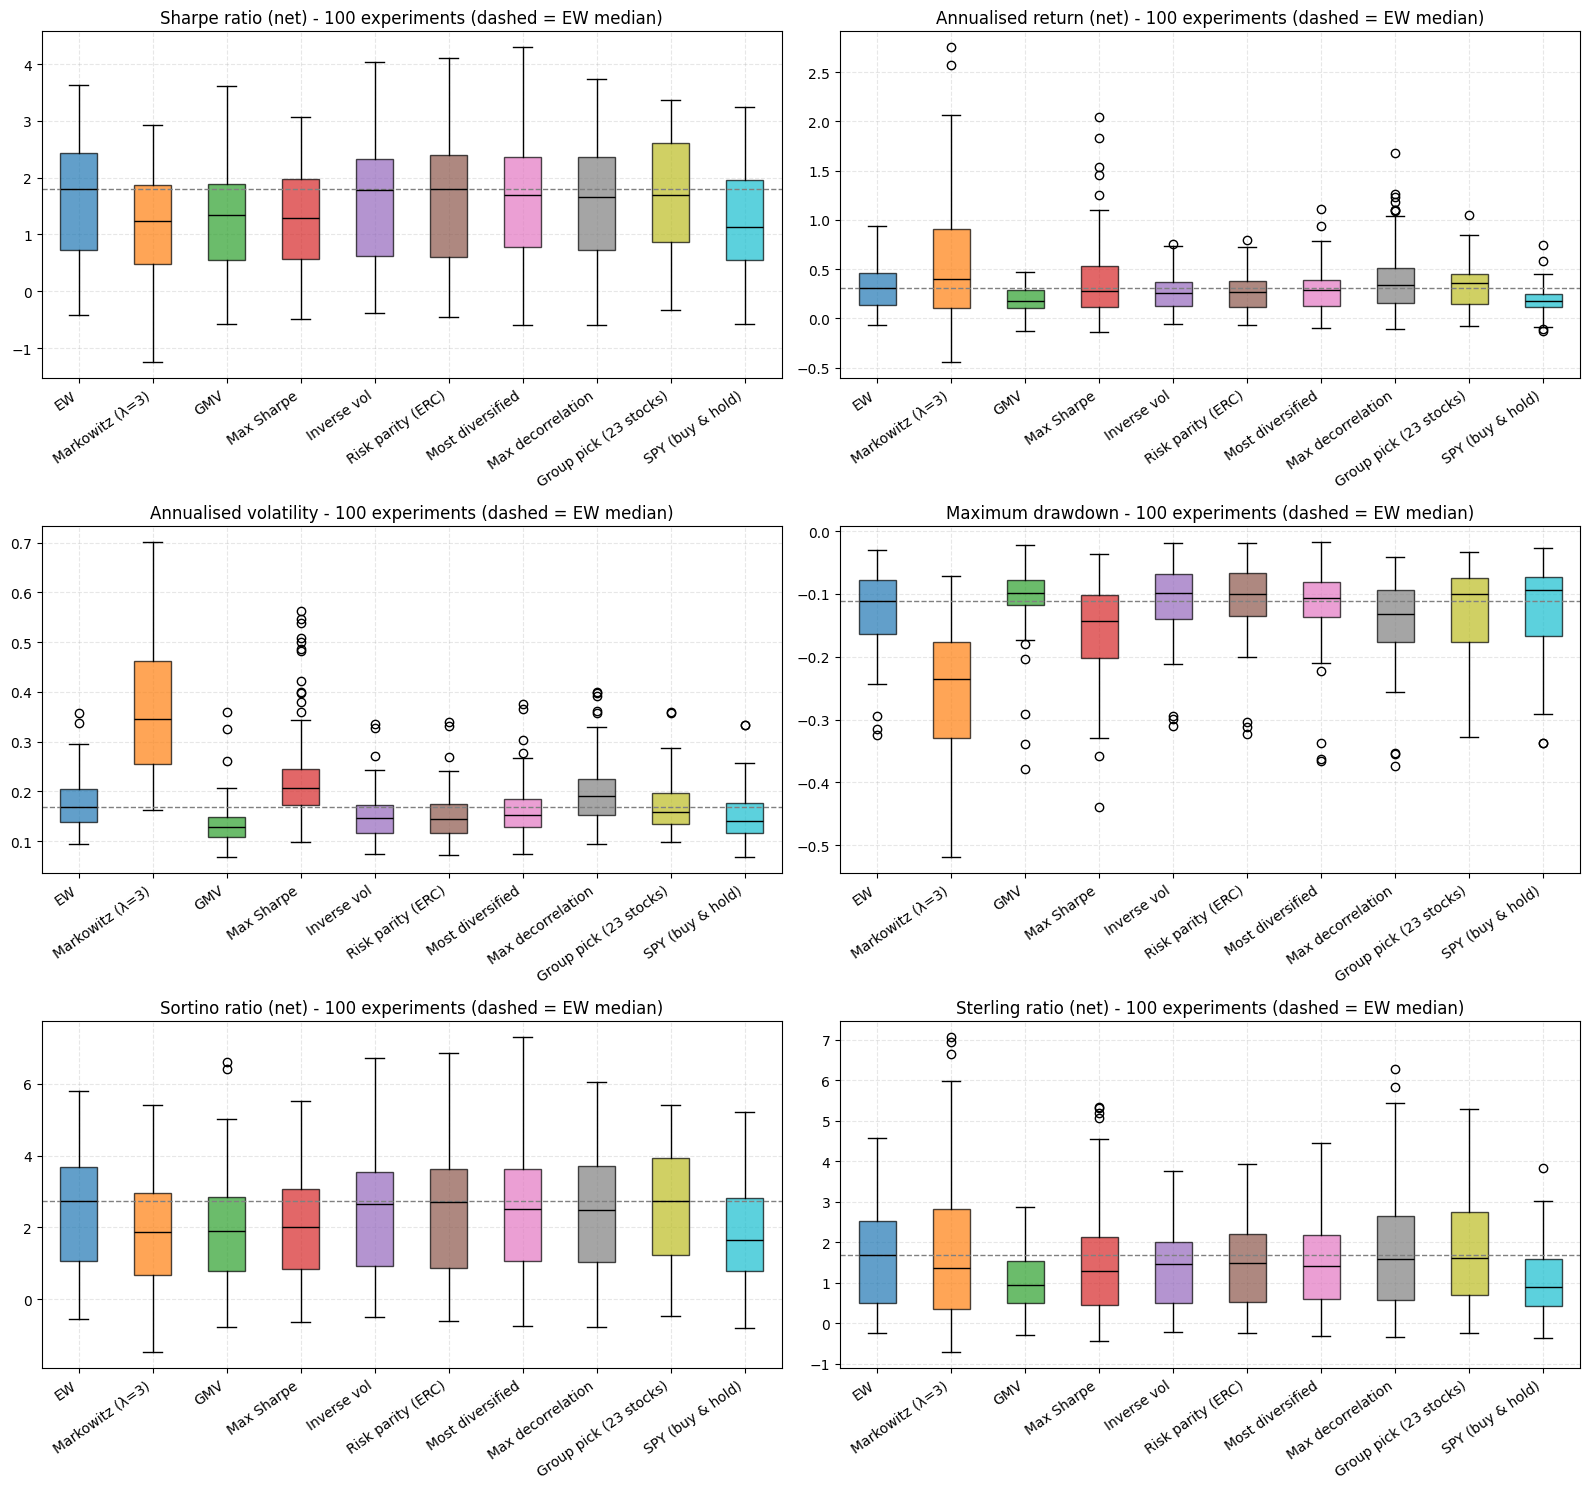

In [28]:
# Boxplots of the main metrics across the 100 experiments
plot_metrics = [('Sharpe', 'Sharpe ratio (net)'), ('Ann. return', 'Annualised return (net)'),
                ('Ann. volatility', 'Annualised volatility'), ('Max drawdown', 'Maximum drawdown'),
                ('Sortino', 'Sortino ratio (net)'), ('Sterling', 'Sterling ratio (net)')]

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
for ax, (metric, title) in zip(axes.flatten(), plot_metrics):
    data = [results.loc[results['Strategy'] == name, metric].values for name in order]
    box = ax.boxplot(data, patch_artist=True, showfliers=True, medianprops=dict(color='black'))
    for patch, name in zip(box['boxes'], order):
        patch.set_facecolor(colours[name])
        patch.set_alpha(0.7)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels(order, rotation=35, ha='right')
    ax.axhline(np.median(data[0]), color='grey', linestyle='--', linewidth=1)   # EW median
    ax.set_title(f'{title} - 100 experiments (dashed = EW median)')
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/04_boxplots_metrics.png', dpi=150)
plt.show()

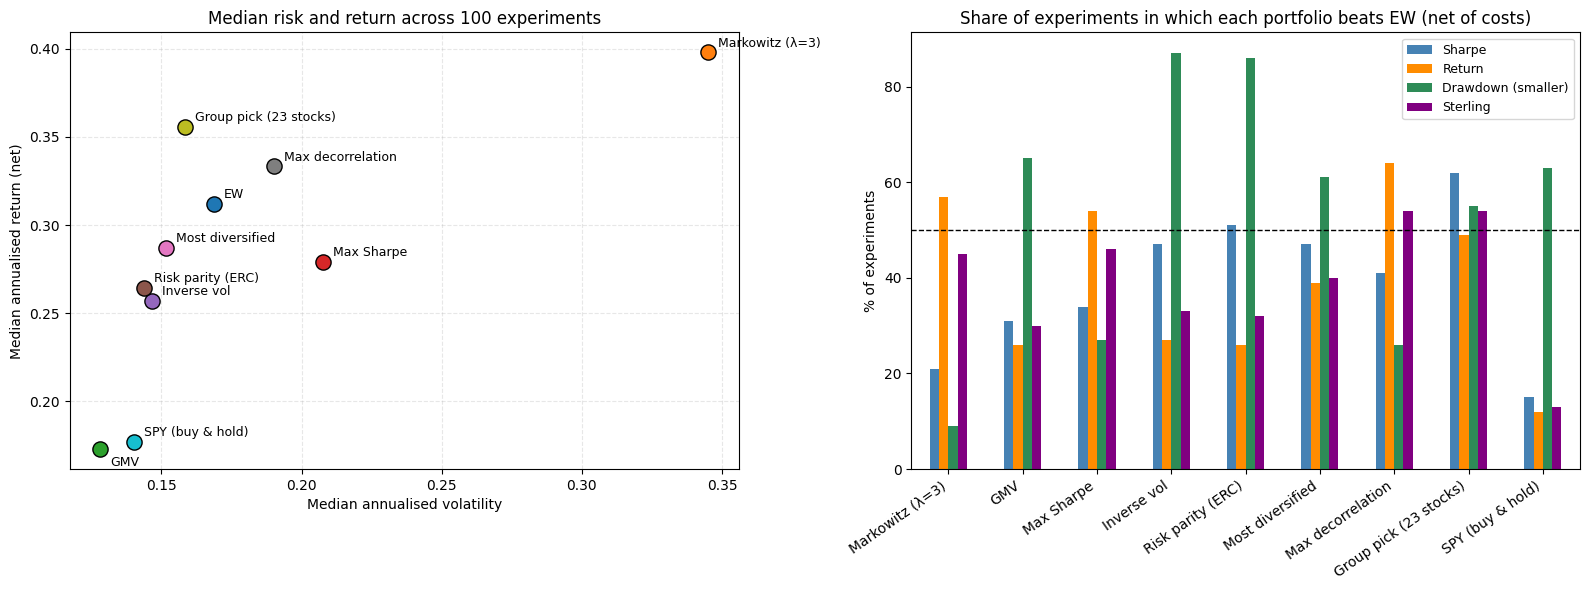

In [29]:
# Return vs risk (medians) and % of experiments that beat EW
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name in order:
    axes[0].scatter(medians.loc[name, 'Ann. volatility'], medians.loc[name, 'Ann. return'],
                    s=120, color=colours[name], edgecolor='black', zorder=3)
    # The label goes above and to the right of the point; GMV is very close to SPY, so its label goes below the point
    offset = (7, 4)
    if name == 'GMV':
        offset = (7, -12)
    axes[0].annotate(name, (medians.loc[name, 'Ann. volatility'], medians.loc[name, 'Ann. return']),
                     textcoords='offset points', xytext=offset, fontsize=9, zorder=4)
axes[0].set_xlabel('Median annualised volatility')
axes[0].set_ylabel('Median annualised return (net)')
axes[0].set_title('Median risk and return across 100 experiments')
axes[0].grid(True, linestyle='--', alpha=0.3)

# We give the columns short names first, so that each colour in the legend gets the right label
bars = beats_ew[['% beats EW: Sharpe', '% beats EW: Ann. return', '% beats EW: Max drawdown', '% beats EW: Sterling']].copy()
bars.columns = ['Sharpe', 'Return', 'Drawdown (smaller)', 'Sterling']
bars.plot(kind='bar', ax=axes[1], color=['steelblue', 'darkorange', 'seagreen', 'purple'])
axes[1].axhline(50, color='black', linestyle='--', linewidth=1)
axes[1].set_ylabel('% of experiments')
axes[1].set_title('Share of experiments in which each portfolio beats EW (net of costs)')
axes[1].set_xticklabels(beats_ew.index, rotation=35, ha='right')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('../figures/04_risk_return_and_beats_ew.png', dpi=150)
plt.show()

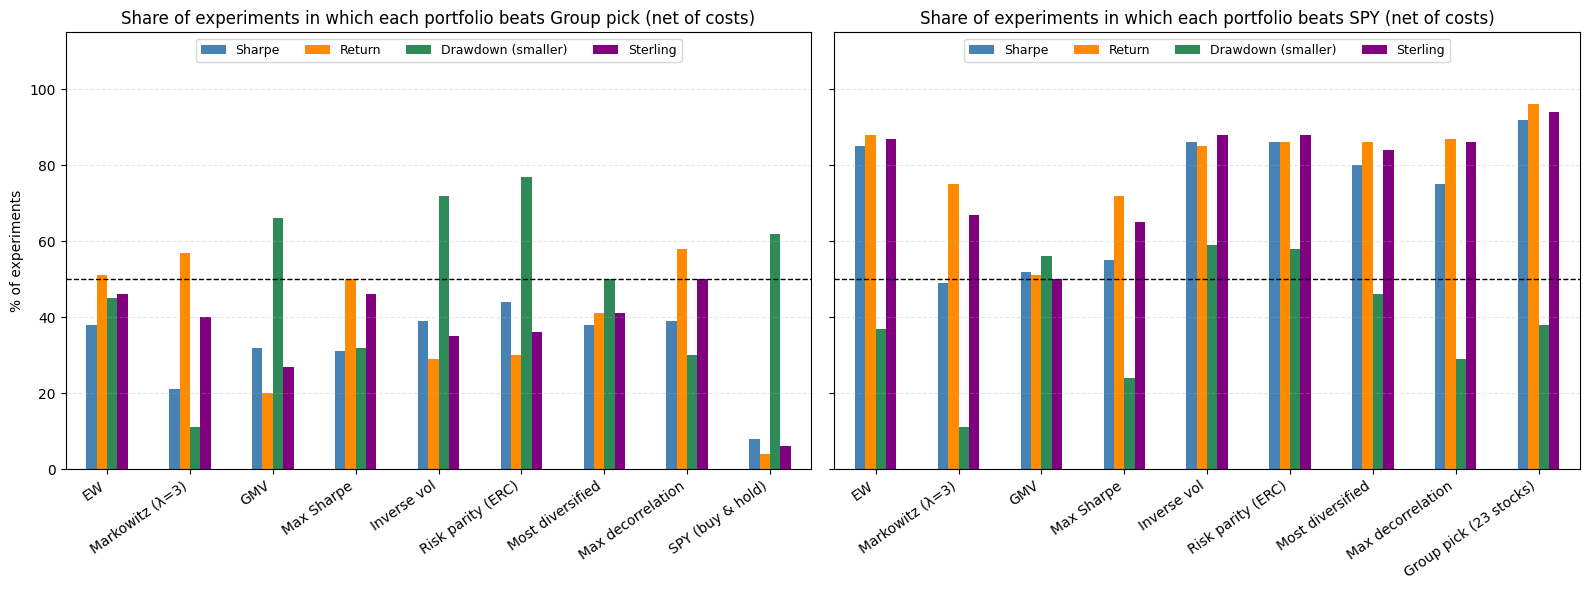

In [30]:
# The same bars, but with the Group pick and SPY as benchmarks
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, (table, label) in zip(axes, [(beats_group_pick, 'Group pick'), (beats_spy, 'SPY')]):
    bars = table[[f'% beats {label}: Sharpe', f'% beats {label}: Ann. return', f'% beats {label}: Max drawdown', f'% beats {label}: Sterling']].copy()
    bars.columns = ['Sharpe', 'Return', 'Drawdown (smaller)', 'Sterling']      # short names -> correct legend labels
    bars.plot(kind='bar', ax=ax, color=['steelblue', 'darkorange', 'seagreen', 'purple'])
    ax.axhline(50, color='black', linestyle='--', linewidth=1)
    ax.set_ylabel('% of experiments')
    ax.set_title(f'Share of experiments in which each portfolio beats {label} (net of costs)')
    ax.set_xticklabels(table.index, rotation=35, ha='right')
    ax.set_ylim(0, 115)                                         # room above the 100% bars for the legend
    ax.legend(fontsize=9, ncol=4, loc='upper center')           # one row at the top, so it does not cover any bar
    ax.grid(True, linestyle='--', alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('../figures/04_beats_group_pick_and_spy.png', dpi=150)
plt.show()

### 9.3 Turnover, costs and concentration

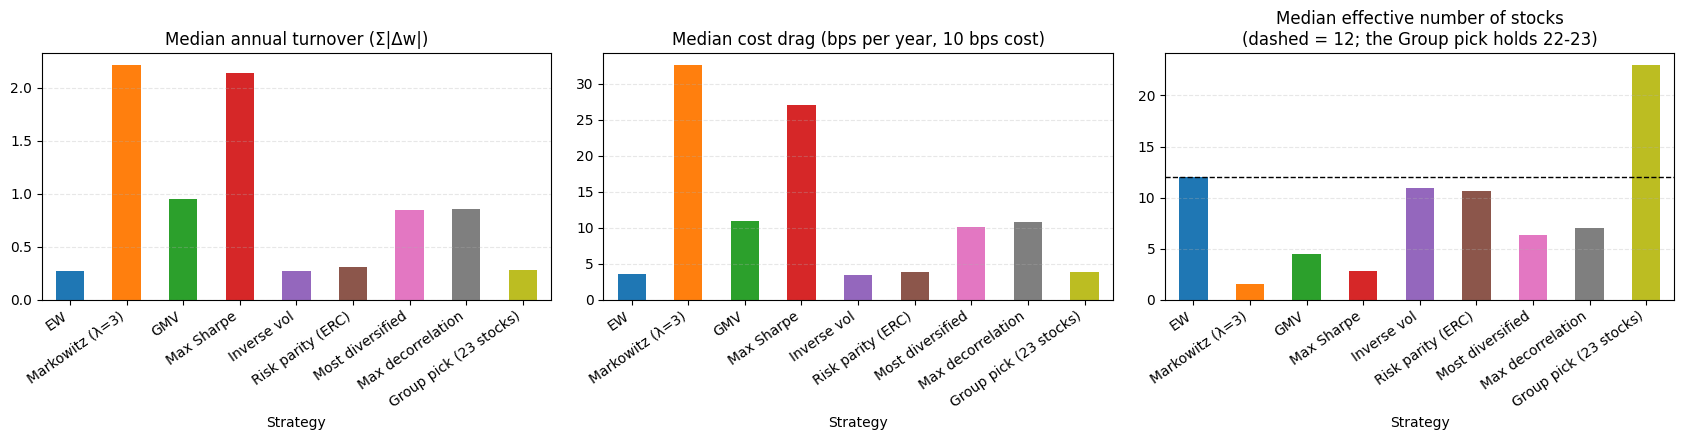

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
portfolios_no_spy = list(strategies.keys()) + [GROUP]       # the 8 strategies + the Group pick (SPY has no rebalancing)

medians.loc[portfolios_no_spy, 'Turnover (annual)'].plot(kind='bar', ax=axes[0], color=[colours[n] for n in portfolios_no_spy])
axes[0].set_title('Median annual turnover (Σ|Δw|)')

(10000 * medians.loc[portfolios_no_spy, 'Cost drag']).plot(kind='bar', ax=axes[1], color=[colours[n] for n in portfolios_no_spy])
axes[1].set_title('Median cost drag (bps per year, 10 bps cost)')

medians.loc[portfolios_no_spy, 'Effective N'].plot(kind='bar', ax=axes[2], color=[colours[n] for n in portfolios_no_spy])
axes[2].axhline(N_ASSETS, color='black', linestyle='--', linewidth=1)
axes[2].set_title(f'Median effective number of stocks\n(dashed = {N_ASSETS}; the Group pick holds 22-23)')

for ax in axes:
    ax.set_xticklabels(portfolios_no_spy, rotation=35, ha='right')
    ax.grid(True, linestyle='--', alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('../figures/04_turnover_costs_concentration.png', dpi=150)
plt.show()

### 9.4 Ranking of the portfolios in each experiment

In each experiment we rank the 10 portfolios (8 strategies, Group pick and SPY) by net Sharpe ratio (1 = best, 10 = last).
A low and stable average rank is a good sign.

In [32]:
sharpe_wide = results.pivot(index='Experiment', columns='Strategy', values='Sharpe')[order]
rankings = sharpe_wide.rank(axis=1, ascending=False)          # rank within each row (experiment)

rankings_table = pd.DataFrame({
    'Average rank': rankings.mean(),
    'Median rank': rankings.median(),
    '% ranked 1st': 100 * (rankings == 1).mean(),
    '% in top 3': 100 * (rankings <= 3).mean(),
    '% ranked last': 100 * (rankings == len(order)).mean(),
}).sort_values('Average rank')
display(rankings_table.round(1))

,Average rank,Median rank,% ranked 1st,% in top 3,% ranked last
Strategy,,,,,
Group pick (23 stocks),3.9,3.5,33.0,50.0,2.0
Risk parity (ERC),4.2,4.0,3.0,35.0,0.0
EW,4.5,4.5,6.0,39.0,1.0
Inverse vol,4.7,5.0,3.0,27.0,0.0
Most diversified,4.8,5.0,11.0,34.0,1.0
Max decorrelation,5.0,5.0,10.0,36.0,2.0
Max Sharpe,6.4,8.0,12.0,25.0,11.0
GMV,6.6,8.0,13.0,27.0,30.0
Markowitz (λ=3),7.4,9.0,8.0,20.0,30.0


### 9.5 Head-to-head comparison of all portfolios

Sections 9.2 and 9.4 compare each portfolio with **one** benchmark (EW, the Group pick or SPY) or rank them all at once. Here we compare
**every portfolio against every other one**. All 10 portfolios are evaluated on the **same 100 experiments** (the same out-of-sample years),
so for each pair of portfolios (A, B) we can count in how many experiments A was better than B:

$$W[A, B] = \% \text{ of the 100 experiments in which portfolio } A \text{ (row) is better than portfolio } B \text{ (column) in the same experiment}$$

- **Better** = higher Sharpe ratio (net), higher annualised return (net), smaller maximum drawdown (less negative), lower annualised volatility,
  higher Sterling ratio (net).
- $W[A, B] + W[B, A] = 100\%$ (ties are practically impossible). Above 50% → A beats B more often than not. The diagonal is left blank.
- The last matrix is the **median paired difference of the Sharpe ratio**: the median, over the 100 experiments, of
  (Sharpe of A − Sharpe of B) in the same experiment — *by how much* A usually beats (or loses to) B.
- **Reading example:** row `Group pick (23 stocks)`, column `EW` of the Sharpe matrix = % of the experiments in which the Group pick had a
  higher Sharpe ratio than EW.
- The last table summarises each row: the average % of head-to-head comparisons won against the other 9 portfolios.
- Charts: the six matrices in one figure (`04_pairwise_win_rates.png`) and, larger and easier to read in the report, the Sharpe matrix
  on its own (`04_pairwise_sharpe.png`).
- Reminder: the experiments overlap (section 5), so these percentages measure **consistency**, not statistical significance.

In [33]:
def pairwise_win_rates(table, metric, higher_is_better, names):
    # W[A, B] = % of experiments in which A (row) is better than B (column) in the SAME experiment
    wide = table.pivot(index='Experiment', columns='Strategy', values=metric)     # experiments x portfolios
    matrix = pd.DataFrame(np.nan, index=names, columns=names)
    for a in names:
        for b in names:
            if a == b:
                continue                                  # the diagonal stays empty (NaN)
            if higher_is_better:
                matrix.loc[a, b] = 100 * (wide[a] > wide[b]).mean()
            else:
                matrix.loc[a, b] = 100 * (wide[a] < wide[b]).mean()
    return matrix


def median_paired_difference(table, metric, names):
    # D[A, B] = median over the experiments of (metric of A - metric of B) in the SAME experiment
    wide = table.pivot(index='Experiment', columns='Strategy', values=metric)
    matrix = pd.DataFrame(np.nan, index=names, columns=names)
    for a in names:
        for b in names:
            if a != b:
                matrix.loc[a, b] = (wide[a] - wide[b]).median()
    return matrix


pairwise_sharpe = pairwise_win_rates(results, 'Sharpe', True, order)
pairwise_return = pairwise_win_rates(results, 'Ann. return', True, order)
pairwise_max_drawdown = pairwise_win_rates(results, 'Max drawdown', True, order)      # higher = less negative = smaller fall
pairwise_volatility = pairwise_win_rates(results, 'Ann. volatility', False, order)    # lower volatility is better
pairwise_sterling = pairwise_win_rates(results, 'Sterling', True, order)
pairwise_median_sharpe_diff = median_paired_difference(results, 'Sharpe', order)

print('% of experiments in which the ROW portfolio beats the COLUMN portfolio - Sharpe ratio (net)')
display(pairwise_sharpe.round(0))
print('Same, annualised return (net)')
display(pairwise_return.round(0))
print('Same, maximum drawdown (smaller is better)')
display(pairwise_max_drawdown.round(0))
print('Same, annualised volatility (lower is better)')
display(pairwise_volatility.round(0))
print('Same, Sterling ratio (net)')
display(pairwise_sterling.round(0))
print('Median paired difference of the Sharpe ratio (row minus column)')
display(pairwise_median_sharpe_diff.round(2))

# Summary of each row: average % of the head-to-head comparisons won against the other 9 portfolios
# (mean() ignores the empty diagonal)
pairwise_avg_win_rate = pd.DataFrame({
    'Avg % won: Sharpe': pairwise_sharpe.mean(axis=1),
    'Avg % won: Ann. return': pairwise_return.mean(axis=1),
    'Avg % won: Max drawdown': pairwise_max_drawdown.mean(axis=1),
    'Avg % won: Ann. volatility': pairwise_volatility.mean(axis=1),
    'Avg % won: Sterling': pairwise_sterling.mean(axis=1),
    'Rivals beaten in > 50% (Sharpe)': (pairwise_sharpe > 50).sum(axis=1),
}).sort_values('Avg % won: Sharpe', ascending=False)
print('Average % of head-to-head comparisons won (against the other 9 portfolios)')
display(pairwise_avg_win_rate.round(1))

% of experiments in which the ROW portfolio beats the COLUMN portfolio - Sharpe ratio (net)


,EW,Markowitz (λ=3),GMV,Max Sharpe,Inverse vol,Risk parity (ERC),Most diversified,Max decorrelation,Group pick (23 stocks),SPY (buy & hold)
EW,NaN,79.0,69.0,66.0,53.0,49.0,53.0,59.0,38.0,85.0
Markowitz (λ=3),21.0,NaN,45.0,37.0,21.0,21.0,25.0,25.0,21.0,49.0
GMV,31.0,55.0,NaN,48.0,29.0,28.0,31.0,34.0,32.0,52.0
Max Sharpe,34.0,63.0,52.0,NaN,34.0,30.0,33.0,32.0,31.0,55.0
Inverse vol,47.0,79.0,71.0,66.0,NaN,35.0,53.0,54.0,39.0,86.0
Risk parity (ERC),51.0,79.0,72.0,70.0,65.0,NaN,57.0,57.0,44.0,86.0
Most diversified,47.0,75.0,69.0,67.0,47.0,43.0,NaN,56.0,38.0,80.0
Max decorrelation,41.0,75.0,66.0,68.0,46.0,43.0,44.0,NaN,39.0,75.0
Group pick (23 stocks),62.0,79.0,68.0,69.0,61.0,56.0,62.0,61.0,NaN,92.0
SPY (buy & hold),15.0,51.0,48.0,45.0,14.0,14.0,20.0,25.0,8.0,NaN


Same, annualised return (net)


,EW,Markowitz (λ=3),GMV,Max Sharpe,Inverse vol,Risk parity (ERC),Most diversified,Max decorrelation,Group pick (23 stocks),SPY (buy & hold)
EW,NaN,43.0,74.0,46.0,73.0,74.0,61.0,36.0,51.0,88.0
Markowitz (λ=3),57.0,NaN,66.0,63.0,62.0,62.0,61.0,56.0,57.0,75.0
GMV,26.0,34.0,NaN,28.0,27.0,25.0,27.0,25.0,20.0,51.0
Max Sharpe,54.0,37.0,72.0,NaN,60.0,58.0,57.0,48.0,50.0,72.0
Inverse vol,27.0,38.0,73.0,40.0,NaN,39.0,38.0,29.0,29.0,85.0
Risk parity (ERC),26.0,38.0,75.0,42.0,61.0,NaN,36.0,31.0,30.0,86.0
Most diversified,39.0,39.0,73.0,43.0,62.0,64.0,NaN,31.0,41.0,86.0
Max decorrelation,64.0,44.0,75.0,52.0,71.0,69.0,69.0,NaN,58.0,87.0
Group pick (23 stocks),49.0,43.0,80.0,50.0,71.0,70.0,59.0,42.0,NaN,96.0
SPY (buy & hold),12.0,25.0,49.0,28.0,15.0,14.0,14.0,13.0,4.0,NaN


Same, maximum drawdown (smaller is better)


...

,EW,Markowitz (λ=3),GMV,Max Sharpe,Inverse vol,Risk parity (ERC),Most diversified,Max decorrelation,Group pick (23 stocks),SPY (buy & hold)
EW,NaN,55.0,70.0,54.0,67.0,68.0,60.0,46.0,46.0,87.0
Markowitz (λ=3),45.0,NaN,59.0,55.0,47.0,46.0,48.0,43.0,40.0,67.0
GMV,30.0,41.0,NaN,35.0,29.0,29.0,28.0,29.0,27.0,50.0
Max Sharpe,46.0,45.0,65.0,NaN,49.0,48.0,49.0,40.0,46.0,65.0
Inverse vol,33.0,53.0,71.0,51.0,NaN,37.0,45.0,40.0,35.0,88.0
Risk parity (ERC),32.0,54.0,71.0,52.0,63.0,NaN,49.0,42.0,36.0,88.0
Most diversified,40.0,52.0,72.0,51.0,55.0,51.0,NaN,42.0,41.0,84.0
Max decorrelation,54.0,57.0,71.0,60.0,60.0,58.0,58.0,NaN,50.0,86.0
Group pick (23 stocks),54.0,60.0,73.0,54.0,65.0,64.0,59.0,50.0,NaN,94.0
SPY (buy & hold),13.0,33.0,50.0,35.0,12.0,12.0,16.0,14.0,6.0,NaN


Median paired difference of the Sharpe ratio (row minus column)


,EW,Markowitz (λ=3),GMV,Max Sharpe,Inverse vol,Risk parity (ERC),Most diversified,Max decorrelation,Group pick (23 stocks),SPY (buy & hold)
EW,NaN,0.55,0.41,0.25,0.01,-0.01,0.05,0.06,-0.08,0.39
Markowitz (λ=3),-0.55,NaN,-0.09,-0.15,-0.47,-0.55,-0.48,-0.48,-0.60,-0.02
GMV,-0.41,0.09,NaN,-0.10,-0.31,-0.36,-0.42,-0.26,-0.50,0.07
Max Sharpe,-0.25,0.15,0.10,NaN,-0.28,-0.31,-0.27,-0.24,-0.36,0.13
Inverse vol,-0.01,0.47,0.31,0.28,NaN,-0.02,0.03,0.05,-0.13,0.38
Risk parity (ERC),0.01,0.55,0.36,0.31,0.02,NaN,0.03,0.08,-0.08,0.42
Most diversified,-0.05,0.48,0.42,0.27,-0.03,-0.03,NaN,0.02,-0.21,0.36
Max decorrelation,-0.06,0.48,0.26,0.24,-0.05,-0.08,-0.02,NaN,-0.18,0.33
Group pick (23 stocks),0.08,0.60,0.50,0.36,0.13,0.08,0.21,0.18,NaN,0.47
SPY (buy & hold),-0.39,0.02,-0.07,-0.13,-0.38,-0.42,-0.36,-0.33,-0.47,NaN


Average % of head-to-head comparisons won (against the other 9 portfolios)


,Avg % won: Sharpe,Avg % won: Ann. return,Avg % won: Max drawdown,Avg % won: Ann. volatility,Avg % won: Sterling,Rivals beaten in > 50% (Sharpe)
Group pick (23 stocks),67.8,62.2,50.6,41.7,63.7,9
Risk parity (ERC),64.6,47.2,73.0,73.8,54.1,8
EW,61.2,60.7,46.8,37.4,61.4,7
Inverse vol,58.9,44.2,70.9,70.1,50.3,6
Most diversified,58.0,53.1,56.8,59.9,54.2,5
Max decorrelation,55.2,65.4,32.6,27.1,61.6,4
Max Sharpe,40.4,56.4,31.2,21.1,50.3,3
GMV,37.8,29.2,69.3,96.1,33.1,2
Markowitz (λ=3),29.4,62.1,8.7,0.6,50.0,0
SPY (buy & hold),26.7,19.3,60.2,72.2,21.2,1


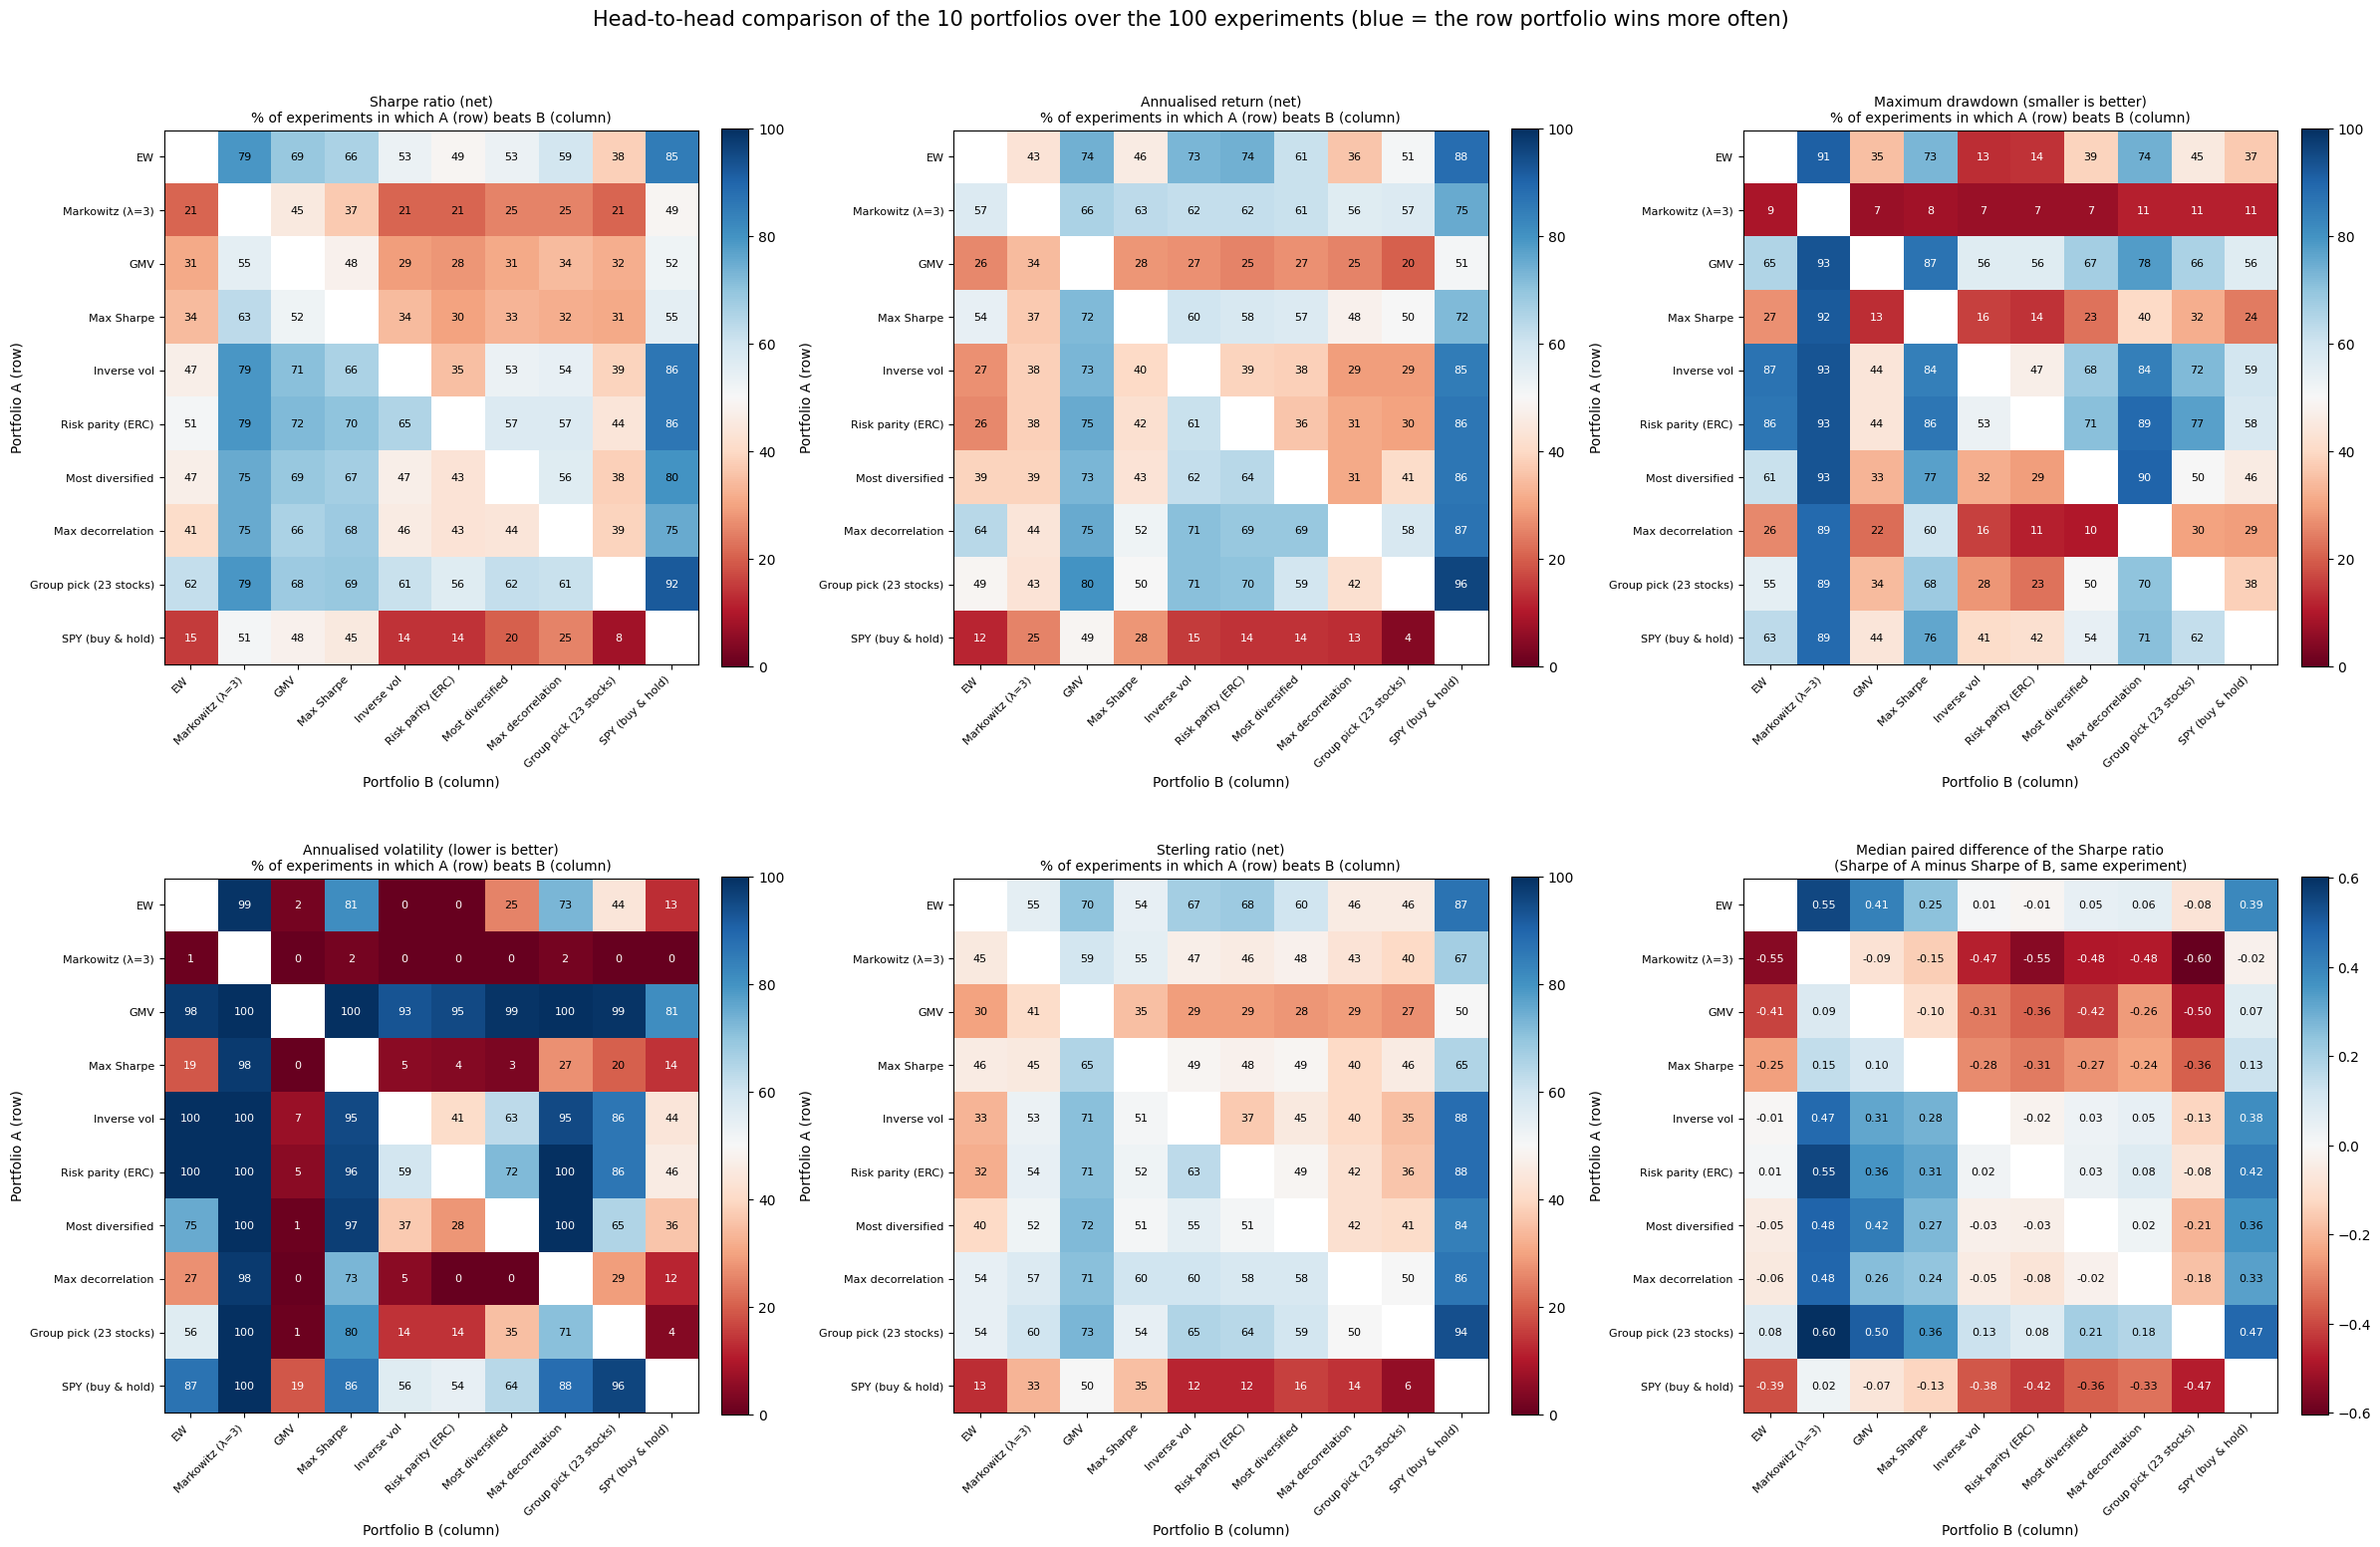

In [34]:
def plot_heatmap(ax, matrix, title, centre, limit, number_format):
    # Annotated heatmap: rows = portfolio A, columns = portfolio B; the empty diagonal (NaN) is left blank
    # Colours: blue = the row portfolio A wins (above 'centre'), red = it loses
    image = ax.imshow(matrix.values.astype(float), cmap='RdBu', vmin=centre - limit, vmax=centre + limit)
    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(matrix.columns, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(matrix.index, fontsize=8)
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            value = matrix.values[i, j]
            if not np.isnan(value):
                text_colour = 'white' if abs(value - centre) > 0.6 * limit else 'black'
                ax.text(j, i, format(value, number_format), ha='center', va='center', fontsize=8, color=text_colour)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Portfolio B (column)')
    ax.set_ylabel('Portfolio A (row)')
    return image


panels = [(pairwise_sharpe, 'Sharpe ratio (net)'),
          (pairwise_return, 'Annualised return (net)'),
          (pairwise_max_drawdown, 'Maximum drawdown (smaller is better)'),
          (pairwise_volatility, 'Annualised volatility (lower is better)'),
          (pairwise_sterling, 'Sterling ratio (net)')]

fig, axes = plt.subplots(2, 3, figsize=(24, 16))
for ax, (matrix, title) in zip(axes.flatten(), panels):
    image = plot_heatmap(ax, matrix, f'{title}\n% of experiments in which A (row) beats B (column)', centre=50, limit=50, number_format='.0f')
    plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

# Last panel: median paired difference of the Sharpe ratio (symmetric colour scale around 0)
limit = np.nanmax(np.abs(pairwise_median_sharpe_diff.values))
image = plot_heatmap(axes[1, 2], pairwise_median_sharpe_diff, 'Median paired difference of the Sharpe ratio\n(Sharpe of A minus Sharpe of B, same experiment)',
                     centre=0, limit=limit, number_format='.2f')
plt.colorbar(image, ax=axes[1, 2], fraction=0.046, pad=0.04)

fig.suptitle('Head-to-head comparison of the 10 portfolios over the 100 experiments (blue = the row portfolio wins more often)', fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('../figures/04_pairwise_win_rates.png', dpi=150)
plt.show()

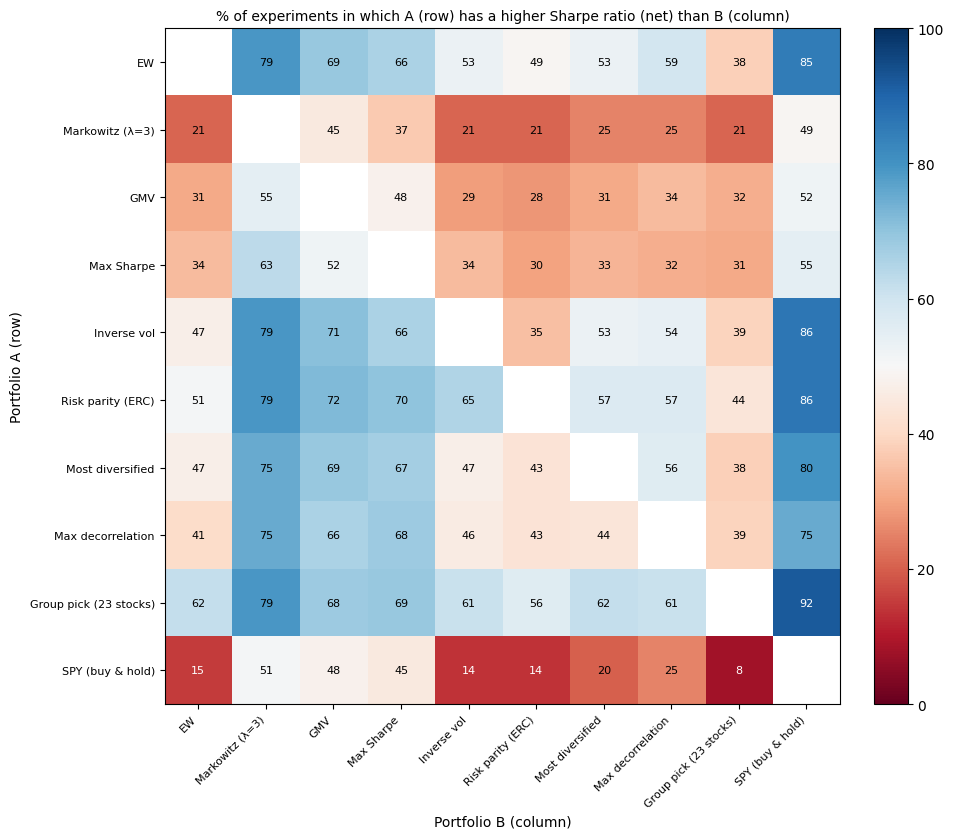

In [35]:
# The Sharpe-ratio panel on its own, larger, so that the numbers can be read in the report
fig, ax = plt.subplots(figsize=(10, 8.5))
image = plot_heatmap(ax, pairwise_sharpe, '% of experiments in which A (row) has a higher Sharpe ratio (net) than B (column)',
                     centre=50, limit=50, number_format='.0f')
plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig('../figures/04_pairwise_sharpe.png', dpi=150)
plt.show()

### 9.6 Example: evolution of wealth in one experiment

We choose the first experiment whose evaluation year includes the March 2020 *crash* (if there is one), to see the behaviour during a crisis.
The 8 strategies hold the 12 stocks drawn for this experiment; the Group pick holds all the eligible stocks of the same period.

Chosen experiment: 62
Stocks: ['AMZN', 'BRK-B', 'COST', 'JNJ', 'JPM', 'LLY', 'MSFT', 'NVDA', 'T', 'V', 'WELL', 'XOM']
Evaluation: 2019-11-11 to 2020-11-09
Stocks held by the Group pick: 23


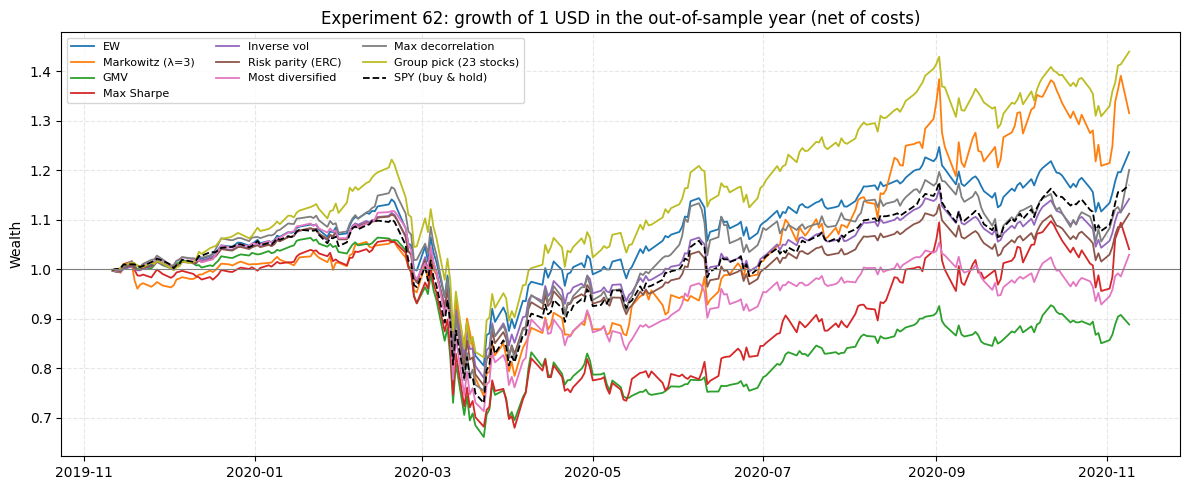

In [36]:
crisis_date = pd.Timestamp('2020-03-16')
candidates = [e for e in design.index
              if pd.Timestamp(design.loc[e, 'Evaluation start']) <= crisis_date <= pd.Timestamp(design.loc[e, 'Evaluation end'])]
example_exp = candidates[0] if len(candidates) > 0 else design.index[0]
print('Chosen experiment:', example_exp)
print('Stocks:', design.loc[example_exp, 'Assets'])
print('Evaluation:', design.loc[example_exp, 'Evaluation start'], 'to', design.loc[example_exp, 'Evaluation end'])
print('Stocks held by the Group pick:', len(design_all.loc[example_exp, 'Assets']))

plt.figure(figsize=(12, 5))
for name in list(strategies.keys()) + [GROUP]:
    sim = simulations[(example_exp, name)]
    r_net = sim['r_gross'] - COST * sim['turnover']
    plt.plot((1 + r_net).cumprod(), label=name, color=colours[name], linewidth=1.3)

example_dates = simulations[(example_exp, 'EW')]['r_gross'].index
plt.plot((1 + returns.loc[example_dates, 'SPY']).cumprod(), label='SPY (buy & hold)', color='black', linestyle='--', linewidth=1.3)
plt.axhline(1, color='grey', linewidth=0.8)
plt.title(f'Experiment {example_exp}: growth of 1 USD in the out-of-sample year (net of costs)')
plt.ylabel('Wealth')
plt.legend(fontsize=8, ncol=3)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/04_wealth_example.png', dpi=150)
plt.show()

## 10. Robustness

### 10.1 Higher transaction costs (0, 10, 25 and 50 bps)

There is no need to simulate again: we just recompute the net returns with a different cost (for the 8 strategies and the Group pick).

Median Sharpe ratio (net) for each cost level


,0 bps,10 bps,25 bps,50 bps
EW,1.808,1.806,1.804,1.801
Markowitz (λ=3),1.241,1.232,1.219,1.196
GMV,1.349,1.338,1.321,1.294
Max Sharpe,1.305,1.288,1.262,1.250
Inverse vol,1.779,1.777,1.774,1.770
Risk parity (ERC),1.803,1.801,1.797,1.791
Most diversified,1.707,1.701,1.691,1.675
Max decorrelation,1.664,1.658,1.649,1.634
Group pick (23 stocks),1.705,1.704,1.701,1.697
SPY (buy & hold),1.128,1.128,1.128,1.128


Position in the ranking (by median Sharpe ratio)


,0 bps,10 bps,25 bps,50 bps
EW,1,1,1,1
Markowitz (λ=3),9,9,9,9
GMV,7,7,7,7
Max Sharpe,8,8,8,8
Inverse vol,3,3,3,3
Risk parity (ERC),2,2,2,2
Most diversified,4,5,5,5
Max decorrelation,6,6,6,6
Group pick (23 stocks),5,4,4,4
SPY (buy & hold),10,10,10,10


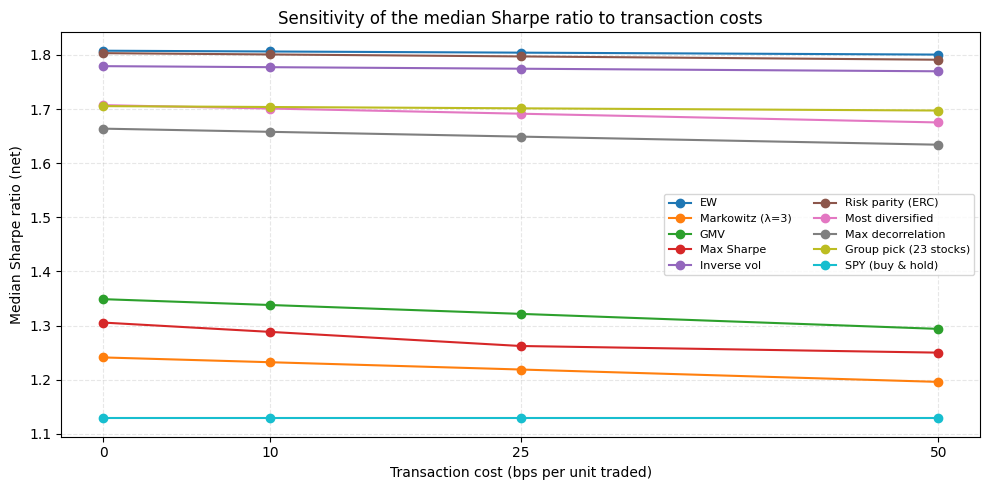

In [37]:
cost_levels = [0.0, 0.0010, 0.0025, 0.0050]

sharpe_by_cost = pd.DataFrame(index=order)
ranking_by_cost = pd.DataFrame(index=order)
for cost in cost_levels:
    table_c = metrics_table(simulations, cost)
    label = f'{cost * 10000:.0f} bps'
    sharpe_by_cost[label] = table_c.groupby('Strategy')['Sharpe'].median()
    ranking_by_cost[label] = sharpe_by_cost[label].rank(ascending=False)

print('Median Sharpe ratio (net) for each cost level')
display(sharpe_by_cost.round(3))
print('Position in the ranking (by median Sharpe ratio)')
display(ranking_by_cost.astype(int))

plt.figure(figsize=(10, 5))
for name in order:
    plt.plot(cost_levels, sharpe_by_cost.loc[name], marker='o', color=colours[name], label=name)
plt.xticks(cost_levels, [f'{c * 10000:.0f}' for c in cost_levels])
plt.xlabel('Transaction cost (bps per unit traded)')
plt.ylabel('Median Sharpe ratio (net)')
plt.title('Sensitivity of the median Sharpe ratio to transaction costs')
plt.legend(fontsize=8, ncol=2)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/04_cost_sensitivity.png', dpi=150)
plt.show()

### 10.2 Quarterly rebalancing (convention suggested in the brief)

Same experiments, same strategies (and the Group pick, again on all the eligible stocks), but rebalancing every 63 days.

In [38]:
simulations_quarterly = run_backtest(strategies, interval=63, run_name='Quarterly')
# The Group pick, also rebalanced every quarter (all the eligible stocks of the same periods)
simulations_quarterly.update(run_backtest({GROUP: weights_equal_weight}, interval=63, design_table=design_all, run_name='Quarterly'))
results_quarterly = metrics_table(simulations_quarterly, COST)
show_failures('Quarterly')

rebalance_comparison = pd.DataFrame({
    'Sharpe (semi-annual)': results.groupby('Strategy')['Sharpe'].median(),
    'Sharpe (quarterly)': results_quarterly.groupby('Strategy')['Sharpe'].median(),
    'Return (semi-annual)': results.groupby('Strategy')['Ann. return'].median(),
    'Return (quarterly)': results_quarterly.groupby('Strategy')['Ann. return'].median(),
    'Turnover (semi-annual)': results.groupby('Strategy')['Turnover (annual)'].median(),
    'Turnover (quarterly)': results_quarterly.groupby('Strategy')['Turnover (annual)'].median(),
}).loc[order]
rebalance_comparison['% beats EW Sharpe (quarterly)'] = beats_benchmark(results_quarterly, 'EW')['% beats EW: Sharpe']
display(rebalance_comparison.round(3))

Optimisations that failed (Quarterly): 0


,Sharpe (semi-annual),Sharpe (quarterly),Return (semi-annual),Return (quarterly),Turnover (semi-annual),Turnover (quarterly),% beats EW Sharpe (quarterly)
Strategy,,,,,,,
EW,1.806,1.723,0.312,0.319,0.274,0.380,NaN
Markowitz (λ=3),1.232,1.180,0.398,0.358,2.215,2.933,17.0
GMV,1.338,1.401,0.173,0.169,0.945,1.215,29.0
Max Sharpe,1.288,1.359,0.279,0.285,2.135,3.079,34.0
Inverse vol,1.777,1.730,0.257,0.258,0.273,0.384,42.0
Risk parity (ERC),1.801,1.825,0.265,0.260,0.306,0.418,48.0
Most diversified,1.701,1.775,0.287,0.280,0.842,1.111,47.0
Max decorrelation,1.658,1.692,0.333,0.344,0.857,1.134,43.0
Group pick (23 stocks),1.704,1.752,0.356,0.349,0.280,0.378,62.0


### 10.3 Markowitz risk aversion (λ = 1, 3, 5)

In [39]:
lambda_strategies = {
    'Markowitz (λ=1)': lambda sample, rf: weights_markowitz(sample, rf, aversion=1),
    'Markowitz (λ=5)': lambda sample, rf: weights_markowitz(sample, rf, aversion=5),
}
lambda_simulations = run_backtest(lambda_strategies, run_name='Markowitz lambda 1 and 5')
show_failures('Markowitz lambda 1 and 5')

# We add them to the simulations already done (λ=3, GMV and Max Sharpe) to compare
simulations_to_compare = {}
for (e, name), sim in simulations.items():
    if name in ['Markowitz (λ=3)', 'GMV', 'Max Sharpe', 'EW']:
        simulations_to_compare[(e, name)] = sim
simulations_to_compare.update(lambda_simulations)

lambda_table = metrics_table(simulations_to_compare, COST)
lambda_table = lambda_table[lambda_table['Strategy'] != 'SPY (buy & hold)']
lambda_order = ['EW', 'GMV', 'Markowitz (λ=5)', 'Markowitz (λ=3)', 'Markowitz (λ=1)', 'Max Sharpe']
lambda_sensitivity = lambda_table.groupby('Strategy')[['Ann. return', 'Ann. volatility', 'Sharpe', 'Max drawdown',
                                                       'Turnover (annual)', 'Effective N']].median().loc[lambda_order]
display(lambda_sensitivity.round(3))

Optimisations that failed (Markowitz lambda 1 and 5): 0


,Ann. return,Ann. volatility,Sharpe,Max drawdown,Turnover (annual),Effective N
Strategy,,,,,,
EW,0.312,0.169,1.806,-0.111,0.274,12.000
GMV,0.173,0.128,1.338,-0.098,0.945,4.435
Markowitz (λ=5),0.345,0.298,1.312,-0.209,2.369,1.985
Markowitz (λ=3),0.398,0.345,1.232,-0.235,2.215,1.501
Markowitz (λ=1),0.426,0.405,1.114,-0.272,2.000,1.000
Max Sharpe,0.279,0.208,1.288,-0.144,2.135,2.769


### 10.4 Do the results depend on the period?

(a) Sharpe ratio difference relative to EW in each experiment, over time (start date of the evaluation), for the 7 optimised strategies
and the Group pick.
(b) Medians by sub-period and by market regime (evaluation year with SPY going up or down).

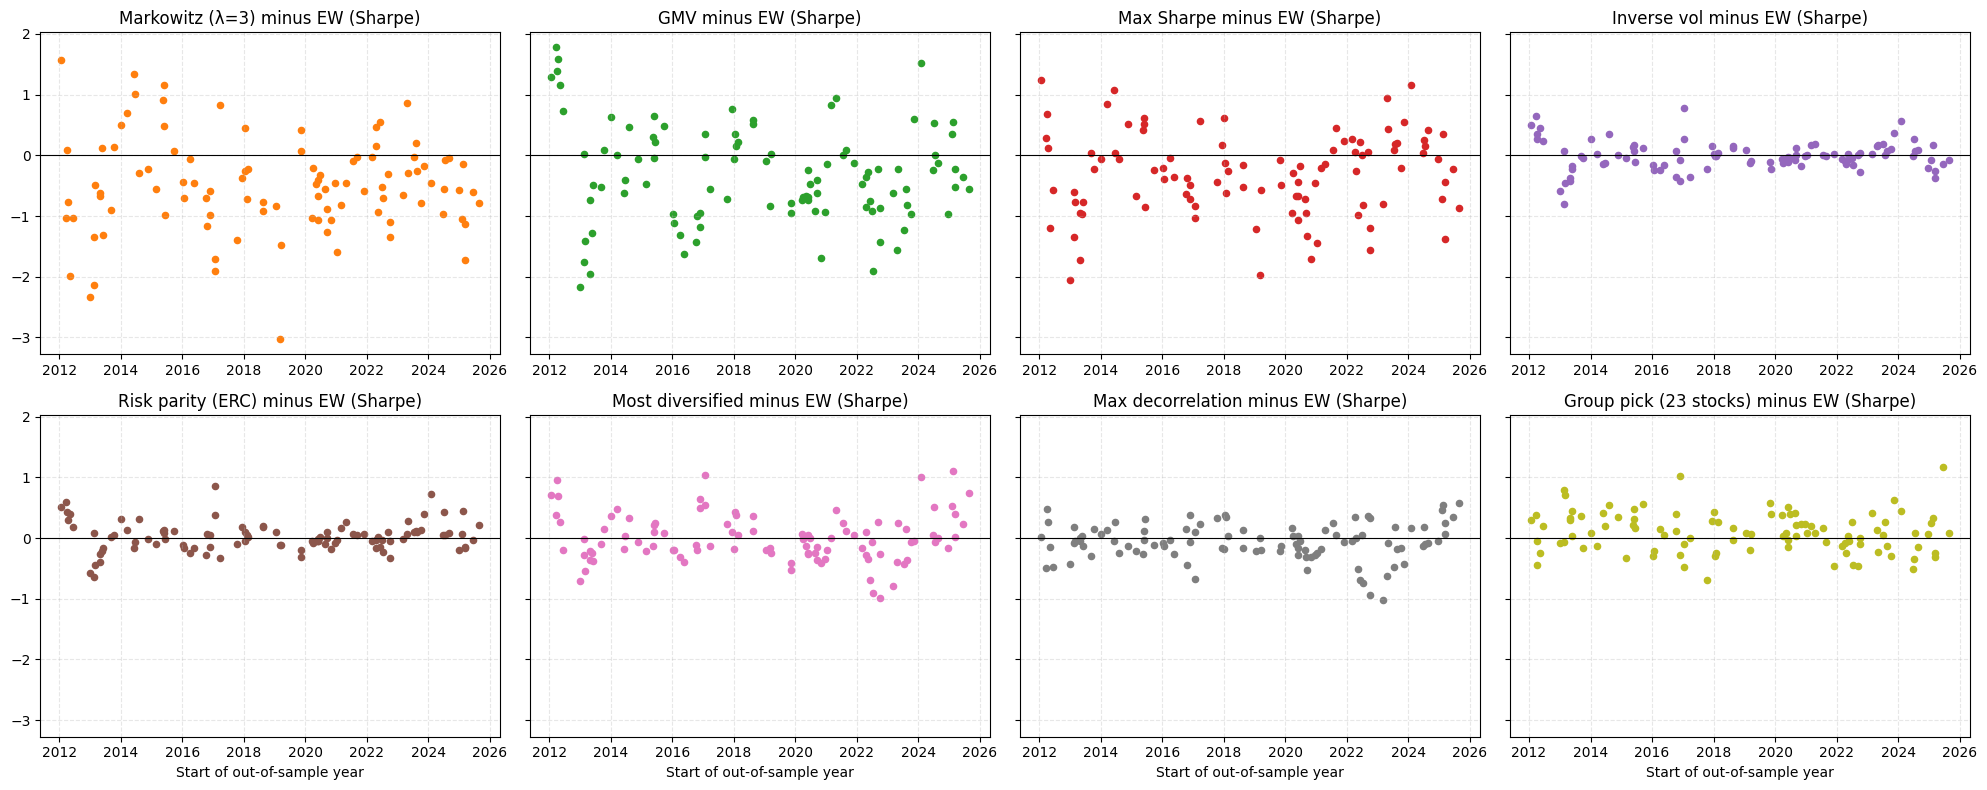

In [40]:
diff_vs_ew = sharpe_wide.sub(sharpe_wide['EW'], axis=0)        # portfolio Sharpe - EW Sharpe
start_dates = pd.to_datetime(design['Evaluation start'])

plot_strategies = ['Markowitz (λ=3)', 'GMV', 'Max Sharpe', 'Inverse vol', 'Risk parity (ERC)', 'Most diversified', 'Max decorrelation', GROUP]
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharey=True)
for ax, name in zip(axes.flatten(), plot_strategies):
    ax.scatter(start_dates, diff_vs_ew[name], color=colours[name], s=20)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f'{name} minus EW (Sharpe)')
    ax.grid(True, linestyle='--', alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel('Start of out-of-sample year')
plt.tight_layout()
plt.savefig('../figures/04_sharpe_diff_vs_ew_over_time.png', dpi=150)
plt.show()

In [41]:
def sub_period(date):
    # Groups the start of the evaluation year into 3 sub-periods
    if date.year < 2017:
        return '2012-2016'
    elif date.year < 2021:
        return '2017-2020'
    else:
        return '2021-2026'


# Market regime: did SPY go up or down in the evaluation year?
spy_return = results[results['Strategy'] == 'SPY (buy & hold)'].set_index('Experiment')['Ann. return']
regime = pd.Series(np.where(spy_return > 0, 'SPY up', 'SPY down'), index=spy_return.index)
period = start_dates.apply(sub_period)

results['Sub-period'] = results['Experiment'].map(period)
results['Market regime'] = results['Experiment'].map(regime)

print('Number of experiments per sub-period:', period.value_counts().sort_index().to_dict())
print('Number of experiments per regime:', regime.value_counts().to_dict())

sharpe_period = pd.pivot_table(results, index='Strategy', columns='Sub-period', values='Sharpe', aggfunc='median').loc[order]
sharpe_regime = pd.pivot_table(results, index='Strategy', columns='Market regime', values='Sharpe', aggfunc='median').loc[order]
return_regime = pd.pivot_table(results, index='Strategy', columns='Market regime', values='Ann. return', aggfunc='median').loc[order]

print('\nMedian Sharpe ratio by sub-period')
display(sharpe_period.round(3))
print('Median Sharpe ratio by market regime')
display(sharpe_regime.round(3))
print('Median return by market regime')
display(return_regime.round(3))

Number of experiments per sub-period: {'2012-2016': 36, '2017-2020': 28, '2021-2026': 36}
Number of experiments per regime: {'SPY up': 88, 'SPY down': 12}

Median Sharpe ratio by sub-period


Sub-period,2012-2016,2017-2020,2021-2026
Strategy,,,
EW,1.834,1.981,1.586
Markowitz (λ=3),1.523,1.356,0.853
GMV,1.407,1.127,1.457
Max Sharpe,1.388,1.228,1.318
Inverse vol,1.826,1.877,1.535
Risk parity (ERC),1.863,1.916,1.717
Most diversified,1.892,1.732,1.606
Max decorrelation,1.772,1.829,1.465
Group pick (23 stocks),1.963,2.253,1.615


Median Sharpe ratio by market regime


Market regime,SPY down,SPY up
Strategy,,
EW,0.170,1.943
Markowitz (λ=3),-0.127,1.376
GMV,-0.027,1.638
Max Sharpe,0.180,1.455
Inverse vol,0.143,1.877
Risk parity (ERC),0.141,1.932
Most diversified,0.094,1.892
Max decorrelation,0.132,1.829
Group pick (23 stocks),0.064,1.966


Median return by market regime


Market regime,SPY down,SPY up
Strategy,,
EW,0.037,0.345
Markowitz (λ=3),-0.048,0.499
GMV,0.002,0.208
Max Sharpe,0.045,0.318
Inverse vol,0.038,0.278
Risk parity (ERC),0.038,0.282
Most diversified,0.029,0.293
Max decorrelation,0.030,0.352
Group pick (23 stocks),0.021,0.383


### 10.5 Do the results depend on the stocks drawn?

Average weight given to each stock by each strategy (average across rebalancings, **only in the experiments in which the stock was drawn**).
It shows where the money goes and whether the strategies depend on a few stocks.

The **Group pick is excluded** from this heatmap: its weights are trivially 1/23 ≈ 4.35% (1/22 before TSLA) in every stock, and its stocks are
those of `design_all` (all the eligible stocks), not the 12 drawn stocks of `design` used here.

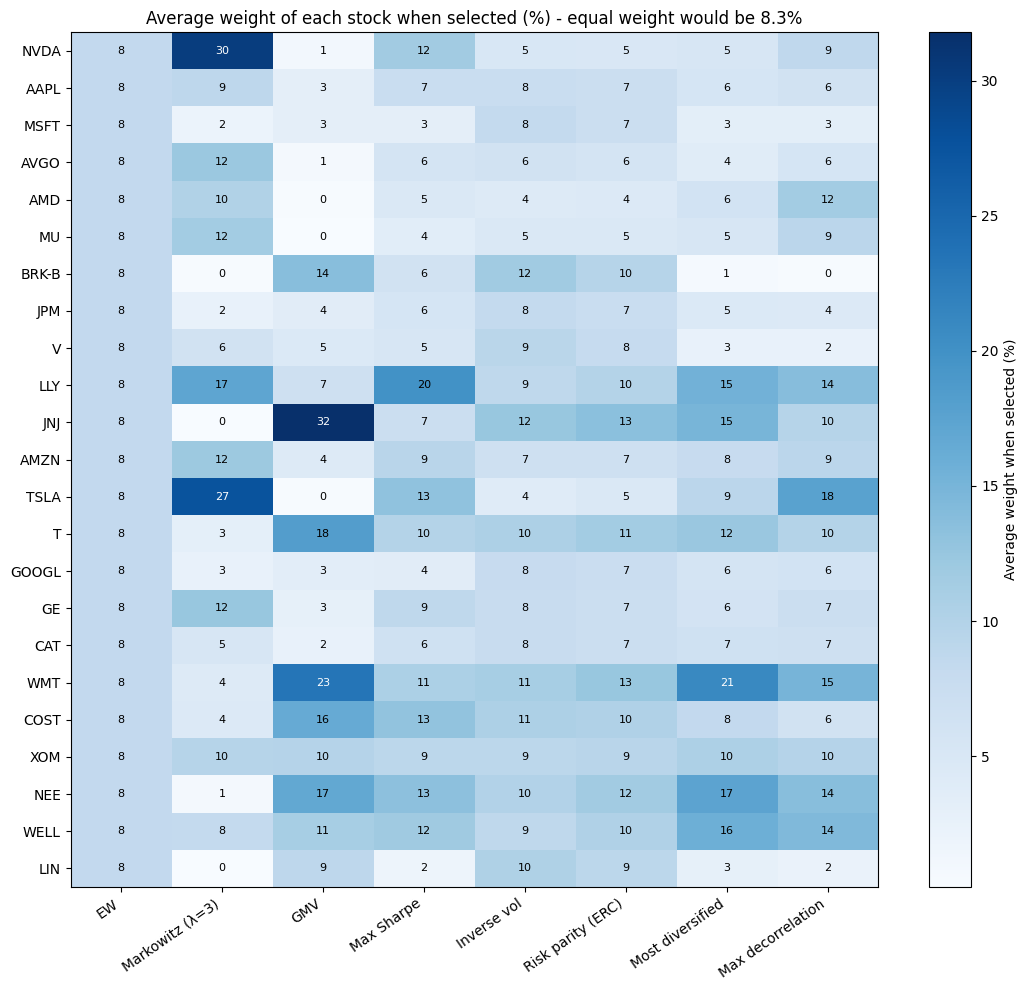

In [42]:
weight_sum = pd.DataFrame(0.0, index=stocks, columns=list(strategies.keys()))
weight_count = pd.DataFrame(0, index=stocks, columns=list(strategies.keys()))

for (e, name), sim in simulations.items():
    if name == GROUP:
        continue                                # excluded: equal weights in all the eligible stocks (see the text above)
    assets_e = design.loc[e, 'Assets']
    for w in sim['weights']:                    # one weight vector per rebalancing
        for stock, weight in zip(assets_e, w):
            weight_sum.loc[stock, name] += weight
            weight_count.loc[stock, name] += 1

avg_weight = weight_sum / weight_count

fig, ax = plt.subplots(figsize=(11, 10))
image = ax.imshow(avg_weight.values * 100, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(avg_weight.columns)))
ax.set_xticklabels(avg_weight.columns, rotation=35, ha='right')
ax.set_yticks(range(len(stocks)))
ax.set_yticklabels(stocks)
for i in range(len(stocks)):
    for j in range(len(avg_weight.columns)):
        value = avg_weight.values[i, j] * 100
        ax.text(j, i, f'{value:.0f}', ha='center', va='center', fontsize=8, color='white' if value > 20 else 'black')
plt.colorbar(image, label='Average weight when selected (%)')
ax.set_title('Average weight of each stock when selected (%) - equal weight would be 8.3%')
plt.tight_layout()
plt.savefig('../figures/04_avg_weight_by_stock.png', dpi=150)
plt.show()

### 10.6 Same periods, different stocks

To see whether the conclusions depend on the stocks drawn, we repeat the backtest with the **same 100 periods** but:
- (a) a **new draw of 12 stocks** (a different seed). As there are only 23 stocks, the two draws have on average about half of their stocks in common;
- (b) **all the eligible stocks** (22 or 23), i.e. without drawing stocks (the table `design_all` built in section 5).

If the ranking of the strategies changes a lot between the three versions, the conclusions depend on the subset of stocks.

**The Group pick** does not depend on the draw of 12 stocks (it always holds all the eligible stocks of the same periods), so in the three
versions we reuse its simulations from section 8: its numbers are the same in every column, only its position relative to the other
portfolios changes. In version (b), strategy a) **EW is exactly the Group pick** (equal weights in all the eligible stocks): the code checks that
their numbers are identical, and in that column the two share the same rank (shown as x.5). There, the Group pick's
"% beats EW" is 0%, because a portfolio never beats an identical copy of itself (it is a tie in every experiment, not a loss).

In [43]:
# (a) Same periods, DIFFERENT 12 stocks (a different seed, used only to draw the stocks)
np.random.seed(SEED + 1)
rows = []
for e in design.index:
    start = design.loc[e, 'start_index']
    block = returns[stocks].iloc[start:start + DATASET_DAYS]
    eligible = [stock for stock in stocks if block[stock].notna().all()]
    chosen = sorted(str(a) for a in np.random.choice(eligible, size=N_ASSETS, replace=False))
    rows.append({'Experiment': e, 'start_index': start, 'Assets': chosen})
design_new_draw = pd.DataFrame(rows).set_index('Experiment')

in_common = [len(set(a) & set(b)) for a, b in zip(design['Assets'], design_new_draw['Assets'])]
print('Average number of stocks in common with the main draw:', round(np.mean(in_common), 1), 'out of', N_ASSETS)

# (b) Same periods, ALL the eligible stocks: we reuse the table 'design_all' built in section 5

simulations_new_draw = run_backtest(strategies, design_table=design_new_draw, run_name='New draw of 12 stocks')
# The Group pick does not depend on the draw of 12 stocks: we reuse its simulations from section 8 (same periods)
for e in design.index:
    simulations_new_draw[(e, GROUP)] = simulations[(e, GROUP)]
results_new_draw = metrics_table(simulations_new_draw, COST, design_table=design_new_draw)
show_failures('New draw of 12 stocks')

simulations_all = run_backtest(strategies, design_table=design_all, run_name='All eligible stocks')
for e in design.index:
    simulations_all[(e, GROUP)] = simulations[(e, GROUP)]
results_all = metrics_table(simulations_all, COST, design_table=design_all)
show_failures('All eligible stocks')

# Check: with all the eligible stocks, EW IS the Group pick -> their numbers must be identical
check_columns = ['Ann. return', 'Ann. volatility', 'Sharpe', 'Sortino', 'Max drawdown', 'Calmar', 'Sterling',
                 'Turnover (annual)', 'Effective N', 'Max weight', 'Diversification ratio (ex-ante)']
ew_all = results_all[results_all['Strategy'] == 'EW'].set_index('Experiment')[check_columns]
group_all = results_all[results_all['Strategy'] == GROUP].set_index('Experiment')[check_columns]
largest_difference = (ew_all - group_all).abs().max().max()
print(f"\nLargest difference between EW and the Group pick in the 'All eligible stocks' run: {largest_difference}")
print('EW and the Group pick are identical in that run?', largest_difference == 0)

Average number of stocks in common with the main draw: 6.0 out of 12


Optimisations that failed (New draw of 12 stocks): 0


Optimisations that failed (All eligible stocks): 0

Largest difference between EW and the Group pick in the 'All eligible stocks' run: 0.0
EW and the Group pick are identical in that run? True


In [44]:
def short_summary(table):
    # Median Sharpe ratio, position in the ranking, median return and % of experiments that beat EW
    median_sharpe = table.groupby('Strategy')['Sharpe'].median()
    return pd.DataFrame({
        'Median Sharpe': median_sharpe,
        'Rank': median_sharpe.rank(ascending=False),
        'Median return': table.groupby('Strategy')['Ann. return'].median(),
        '% beats EW (Sharpe)': beats_benchmark(table, 'EW')['% beats EW: Sharpe'],
    })


subset_comparison = pd.concat({
    '12 stocks (main)': short_summary(results),
    '12 stocks (new draw)': short_summary(results_new_draw),
    'All eligible stocks': short_summary(results_all),
}, axis=1).loc[order]
display(subset_comparison.round(3))

# Agreement: in each experiment, does the strategy beat (or not) EW in BOTH samples of 12 stocks?
sharpe_main = results.pivot(index='Experiment', columns='Strategy', values='Sharpe')
sharpe_new_draw = results_new_draw.pivot(index='Experiment', columns='Strategy', values='Sharpe')
beats_main = sharpe_main.gt(sharpe_main['EW'], axis=0)
beats_new_draw = sharpe_new_draw.gt(sharpe_new_draw['EW'], axis=0)
agreement = 100 * (beats_main == beats_new_draw).mean()
print('% of experiments with the same conclusion "beats / does not beat EW" in the two samples of stocks:')
agreement_order = [name for name in order if name not in ['EW', 'SPY (buy & hold)']]     # same order as the other tables
display(agreement.loc[agreement_order].round(0).to_frame('Agreement (%)'))

12 stocks (main)                                         12 stocks (new draw)                                         All eligible stocks                                        
                          Median Sharpe  Rank Median return % beats EW (Sharpe)        Median Sharpe  Rank Median return % beats EW (Sharpe)       Median Sharpe  Rank Median return % beats EW (Sharpe)
EW                                1.806   1.0         0.312                 NaN                1.640   4.0         0.303                 NaN               1.704   3.5         0.356                 NaN
Markowitz (λ=3)                   1.232   9.0         0.398                21.0                1.019  10.0         0.298                21.0               1.237   9.0         0.483                21.0
GMV                               1.338   7.0         0.173                31.0                1.232   8.0         0.174                34.0               1.461   7.0         0.189                36.0
Max Sharpe                        1.288   8.0         0.279                34.0                1.253   7.0         0.271                39.0               1.383   8.0         0.293                39.0
Inverse vol                       1.777   3.0         0.257                47.0                1.577   6.0         0.260                47.0               1.656   5.0         0.279                40.0
Risk parity (ERC)                 1.801   2.0         0.265                51.0                1.594   5.0         0.264                49.0               1.752   2.0         0.291                54.0
Most diversified                  1.701   5.0         0.287                47.0                1.660   3.0         0.263                50.0               1.845   1.0         0.275                52.0
Max decorrelation                 1.658   6.0         0.333                41.0                1.667   2.0         0.307                43.0               1.601   6.0         0.321                42.0
Group pick (23 stocks)            1.704   4.0         0.356                62.0                1.704   1.0         0.356                68.0               1.704   3.5         0.356                 0.0
SPY (buy & hold)                  1.128  10.0         0.177                15.0                1.128   9.0         0.177                19.0               1.128  10.0         0.177                 8.0

% of experiments with the same conclusion "beats / does not beat EW" in the two samples of stocks:


,Agreement (%)
Strategy,
Markowitz (λ=3),78.0
GMV,73.0
Max Sharpe,77.0
Inverse vol,68.0
Risk parity (ERC),74.0
Most diversified,61.0
Max decorrelation,56.0
Group pick (23 stocks),58.0


## 11. The guideline strategies applied to the group's 23-stock universe

Question: **on our own 23 stocks, would an optimiser have beaten our equal-weight pick?**

In the main backtest the 8 strategies work with 12 random stocks, while the Group pick holds all 23, so part of the difference between them
comes from the universe. Here we put them on the **same universe**: we reuse the *'All eligible stocks'* run of section 10.6
(the same 100 periods, all the eligible stocks — 23, or 22 before TSLA — semi-annual rebalancing, 10 bps, the same evaluation year).
In that run strategy a) EW **is** the Group pick (identical numbers, checked in section 10.6), so it appears only once, as
`Group pick (23 stocks)`; the other rows are the 7 optimised strategies and SPY.

In [45]:
# In this run EW = Group pick, so we keep that portfolio only once (with the name of the Group pick)
universe23_results = results_all[results_all['Strategy'] != 'EW']
universe23_order = [GROUP] + [name for name in strategies.keys() if name != 'EW'] + ['SPY (buy & hold)']

# (a) Median metrics (net of 10 bps)
universe23_medians = universe23_results.groupby('Strategy')[summary_columns].median().loc[universe23_order]
print('Median metrics on the 23-stock universe (100 experiments, net of 10 bps)')
display(universe23_medians.round(3))

# (b) % of experiments in which each portfolio beats the Group pick in the same experiment
universe23_beats_group_pick = beats_benchmark(universe23_results, GROUP, label='Group pick', names=universe23_order)
# ... and by how much: median over the experiments of (Sharpe of the portfolio - Sharpe of the Group pick)
universe23_sharpe_diff = median_paired_difference(universe23_results, 'Sharpe', universe23_order)
universe23_beats_group_pick['Median Sharpe difference vs Group pick'] = universe23_sharpe_diff[GROUP]
print('% of experiments in which each portfolio beats the Group pick (same 23 stocks)')
table_to_show = universe23_beats_group_pick.round(0)
# the median Sharpe differences are small (e.g. +0.02): we show them with 2 decimals
table_to_show['Median Sharpe difference vs Group pick'] = universe23_beats_group_pick['Median Sharpe difference vs Group pick'].round(2)
display(table_to_show)

# (c) Head-to-head on the Sharpe ratio (same function as in section 9.5)
universe23_pairwise_sharpe = pairwise_win_rates(universe23_results, 'Sharpe', True, universe23_order)
print('% of experiments in which the ROW portfolio beats the COLUMN portfolio - Sharpe ratio (net), 23-stock universe')
display(universe23_pairwise_sharpe.round(0))

Median metrics on the 23-stock universe (100 experiments, net of 10 bps)


,Ann. return,Ann. volatility,Sharpe,Sortino,Max drawdown,Calmar,Sterling,Ann. return (gross),Sharpe (gross),Cost drag,Turnover (annual),Effective N,Max weight,Diversification ratio (ex-ante)
Strategy,,,,,,,,,,,,,,
Group pick (23 stocks),0.356,0.158,1.704,2.737,-0.101,2.983,1.600,0.356,1.705,0.000,0.280,23.000,0.043,1.702
Markowitz (λ=3),0.483,0.394,1.237,1.876,-0.266,2.092,1.537,0.487,1.243,0.003,2.283,1.732,0.725,1.182
GMV,0.189,0.120,1.461,2.064,-0.093,2.134,0.958,0.191,1.470,0.001,1.202,5.365,0.286,1.638
Max Sharpe,0.293,0.200,1.383,2.061,-0.134,2.600,1.351,0.296,1.395,0.003,2.321,3.721,0.423,1.546
Inverse vol,0.279,0.141,1.656,2.571,-0.086,3.019,1.406,0.279,1.658,0.000,0.284,20.733,0.072,1.690
Risk parity (ERC),0.291,0.140,1.752,2.652,-0.086,3.146,1.454,0.292,1.755,0.000,0.334,19.934,0.084,1.766
Most diversified,0.275,0.141,1.845,2.862,-0.101,2.972,1.513,0.277,1.856,0.001,1.163,8.614,0.203,1.977
Max decorrelation,0.321,0.179,1.601,2.408,-0.118,2.797,1.494,0.322,1.608,0.002,1.170,9.727,0.165,1.843
SPY (buy & hold),0.177,0.140,1.128,1.658,-0.094,2.003,0.894,0.177,1.128,0.000,0.000,NaN,NaN,NaN


% of experiments in which each portfolio beats the Group pick (same 23 stocks)


,% beats Group pick: Sharpe,% beats Group pick: Ann. return,% beats Group pick: Max drawdown,% beats Group pick: Ann. volatility,% beats Group pick: Sterling,Median Sharpe difference vs Group pick
Markowitz (λ=3),21.0,63.0,8.0,0.0,51.0,-0.49
GMV,36.0,20.0,68.0,100.0,25.0,-0.27
Max Sharpe,39.0,60.0,30.0,23.0,54.0,-0.22
Inverse vol,40.0,16.0,91.0,100.0,29.0,-0.03
Risk parity (ERC),54.0,23.0,93.0,100.0,35.0,0.01
Most diversified,52.0,40.0,63.0,73.0,43.0,0.02
Max decorrelation,42.0,63.0,29.0,33.0,63.0,-0.07
SPY (buy & hold),8.0,4.0,62.0,96.0,6.0,-0.47


% of experiments in which the ROW portfolio beats the COLUMN portfolio - Sharpe ratio (net), 23-stock universe


,Group pick (23 stocks),Markowitz (λ=3),GMV,Max Sharpe,Inverse vol,Risk parity (ERC),Most diversified,Max decorrelation,SPY (buy & hold)
Group pick (23 stocks),NaN,79.0,64.0,61.0,60.0,46.0,48.0,58.0,92.0
Markowitz (λ=3),21.0,NaN,46.0,22.0,21.0,22.0,25.0,31.0,52.0
GMV,36.0,54.0,NaN,42.0,33.0,29.0,22.0,33.0,53.0
Max Sharpe,39.0,78.0,58.0,NaN,38.0,37.0,36.0,37.0,70.0
Inverse vol,40.0,79.0,67.0,62.0,NaN,23.0,41.0,53.0,99.0
Risk parity (ERC),54.0,78.0,71.0,63.0,77.0,NaN,42.0,61.0,100.0
Most diversified,52.0,75.0,78.0,64.0,59.0,58.0,NaN,64.0,93.0
Max decorrelation,42.0,69.0,67.0,63.0,47.0,39.0,36.0,NaN,89.0
SPY (buy & hold),8.0,48.0,47.0,30.0,1.0,0.0,7.0,11.0,NaN


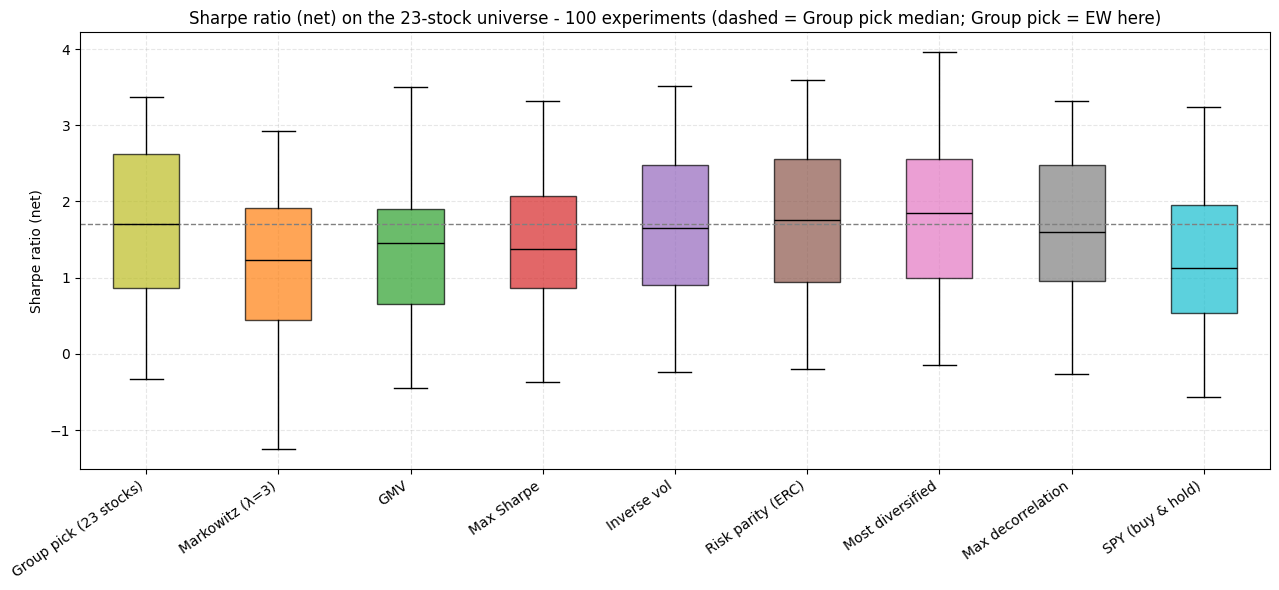

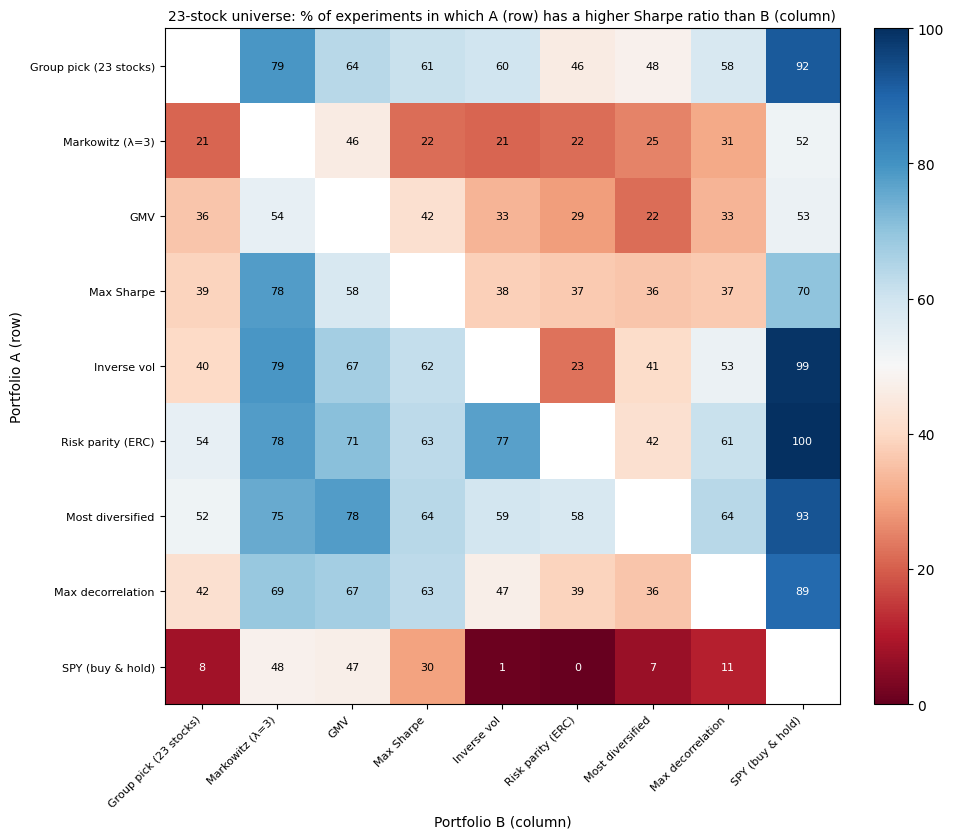

In [46]:
# Boxplot of the Sharpe ratio on the 23-stock universe
fig, ax = plt.subplots(figsize=(13, 6))
data = [universe23_results.loc[universe23_results['Strategy'] == name, 'Sharpe'].values for name in universe23_order]
box = ax.boxplot(data, patch_artist=True, showfliers=True, medianprops=dict(color='black'))
for patch, name in zip(box['boxes'], universe23_order):
    patch.set_facecolor(colours[name])
    patch.set_alpha(0.7)
ax.set_xticks(range(1, len(universe23_order) + 1))
ax.set_xticklabels(universe23_order, rotation=35, ha='right')
ax.axhline(np.median(data[0]), color='grey', linestyle='--', linewidth=1)      # median of the Group pick
ax.set_ylabel('Sharpe ratio (net)')
ax.set_title('Sharpe ratio (net) on the 23-stock universe - 100 experiments (dashed = Group pick median; Group pick = EW here)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/04_universe23_boxplot_sharpe.png', dpi=150)
plt.show()

# Heatmap of the head-to-head Sharpe win rates
fig, ax = plt.subplots(figsize=(10, 8.5))
image = plot_heatmap(ax, universe23_pairwise_sharpe,
                     '23-stock universe: % of experiments in which A (row) has a higher Sharpe ratio than B (column)',
                     centre=50, limit=50, number_format='.0f')
plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig('../figures/04_universe23_pairwise_sharpe.png', dpi=150)
plt.show()

## 12. The Group pick over the full sample (2010-2026)

> **Warning — look-ahead and survivorship bias.** The 23 stocks were chosen **in 2026**, by **today's** market capitalisation: they are the
> companies that survived and became the largest of their sectors (NVDA, AVGO, LLY, …). Nobody could have picked exactly these 23 stocks in
> January 2010. This full-sample history is therefore **heavily affected by look-ahead and survivorship bias** and it is **NOT evidence that the
> pick would have beaten the market in real time**. It is shown only as a description of what the pick did. The fair tests are the
> **out-of-sample experiments** (sections 9–11), where the Group pick competes with strategies built from the same stocks; even there, its
> advantage over SPY keeps part of this selection bias (section 14).

How the Group pick is simulated here (the same rules as in the backtest, but on the whole period instead of 1-year evaluation windows):

- all the trading days from the start of the data (first return on 2010-01-05) to **2026-09-18**;
- **equal weights among the stocks that have a price on the rebalancing date** (the close at which we trade): 22 stocks at the start,
  **TSLA joins at the first semi-annual rebalancing after its listing** (29 June 2010);
- **semi-annual rebalancing** every 126 trading days (the first one is the initial purchase), weights **drift** in between,
  **10 bps** on the traded value (the initial purchase is also charged);
- comparison with **SPY** (investable, total return because the adjusted price includes dividends) and **^GSPC** (the S&P 500 price index:
  not investable and without dividends, so it understates the return of the market by about 1.5–2% per year).

Metrics: CAGR, annualised volatility, Sharpe (with the DGS3 rate of each day), Sortino, maximum drawdown, Calmar (CAGR / |MDD|) and Sterling.
With 16+ years of data, Sterling uses its original definition: CAGR / (|average of the calendar-year maximum drawdowns| + 10%)
(17 calendar years, 2010–2026; 2026 is year to date, until 18 September).

In [47]:
FULL_SAMPLE_END = pd.Timestamp('2026-09-18')

full_returns = returns.loc[:FULL_SAMPLE_END, stocks]
full_dates = full_returns.index
R_full = full_returns.fillna(0).values      # TSLA before its listing: return 0, but its weight is also 0, so nothing changes

# Alignment check: the return of day t goes from the close of prices.index[t] to the close of prices.index[t + 1]
# -> prices.iloc[t] is the close of the day BEFORE full_dates[t], i.e. the close at which we trade
assert prices.index[1] == full_dates[0]

full_rebalance_days = list(range(0, len(full_dates), REBALANCE_INTERVAL))      # every 126 days, starting on the 1st day

weights = np.zeros(len(stocks))              # we start in cash
gross_returns = []
daily_turnover = []
rebalance_log = []
for t in range(len(full_dates)):
    turnover = 0.0
    if t in full_rebalance_days:
        # 1) the stocks that can be bought: those with a price at the close at which we trade
        has_price = prices[stocks].iloc[t].notna().values
        target = has_price / has_price.sum()                    # 1/N among the stocks with a price
        # 2) traded value and new weights
        turnover = np.sum(np.abs(target - weights))
        weights = target
        rebalance_log.append({'Rebalance (first day with new weights)': full_dates[t].date(),
                              'N stocks': int(has_price.sum()), 'Turnover': turnover})
    # 3) portfolio return on day t and drift of the weights
    r_portfolio = np.sum(weights * R_full[t])
    weights = weights * (1 + R_full[t]) / (1 + r_portfolio)
    gross_returns.append(r_portfolio)
    daily_turnover.append(turnover)

group_full_gross = pd.Series(gross_returns, index=full_dates)
group_full_turnover = pd.Series(daily_turnover, index=full_dates)
group_full_net = group_full_gross - COST * group_full_turnover

rebalance_log = pd.DataFrame(rebalance_log)
print('Period:', full_dates[0].date(), 'to', full_dates[-1].date(), '|', len(full_dates), 'trading days |', len(rebalance_log), 'rebalancings')
print('First rebalancings:')
display(rebalance_log.head(3).round(4))
print(f"Average turnover per rebalancing (excluding the initial purchase): {rebalance_log['Turnover'].iloc[1:].mean():.3f}")

Period: 2010-01-05 to 2026-09-18 | 4202 trading days | 34 rebalancings
First rebalancings:


,Rebalance (first day with new weights),N stocks,Turnover
0,2010-01-05,22,1.0000
1,2010-07-07,23,0.1750
2,2011-01-04,23,0.1252


Average turnover per rebalancing (excluding the initial purchase): 0.144


In [48]:
# The three series compared: Group pick (net of costs), SPY (total return) and ^GSPC (price index, no dividends)
full_series = pd.DataFrame({
    GROUP: group_full_net,
    'SPY (total return)': returns.loc[full_dates, 'SPY'],
    '^GSPC (price index)': returns.loc[full_dates, '^GSPC'],
})
rf_full = rf_daily.loc[full_dates]
years = sorted(set(full_dates.year))

rows = []
for name in full_series.columns:
    r = full_series[name]
    m = compute_metrics(r, rf_full)
    # Sterling (original definition): CAGR / (|average of the calendar-year maximum drawdowns| + 10%)
    # (17 calendar years; the last one, 2026, is year to date)
    yearly_mdd = []
    for year in years:
        in_year = full_dates.year == year
        yearly_mdd.append(compute_metrics(r[in_year], rf_full[in_year])['Max drawdown'])
    avg_yearly_mdd = np.mean(yearly_mdd)
    rows.append({
        'Portfolio': name,
        'CAGR': m['Ann. return'],
        'Ann. volatility': m['Ann. volatility'],
        'Sharpe': m['Sharpe'],
        'Sortino': m['Sortino'],
        'Max drawdown': m['Max drawdown'],
        'Calmar': m['Calmar'],
        'Avg. calendar-year max drawdown': avg_yearly_mdd,
        'Sterling': m['Ann. return'] / (abs(avg_yearly_mdd) + 0.10),
        'Final value of 1 USD': (1 + r).prod(),
    })
fullsample_metrics = pd.DataFrame(rows).set_index('Portfolio')
print('Full sample', full_dates[0].date(), 'to', full_dates[-1].date(), '(Group pick net of 10 bps; strongly biased by hindsight, see the warning)')
display(fullsample_metrics.round(3))

# Calendar-year returns (2026 = year to date, until 18 September)
rows = []
for year in years:
    in_year = full_dates.year == year
    row = {'Year': f'{year} (YTD)' if year == FULL_SAMPLE_END.year else str(year)}
    for name in full_series.columns:
        row[name] = (1 + full_series.loc[in_year, name]).prod() - 1
    row['Group pick minus SPY'] = row[GROUP] - row['SPY (total return)']
    rows.append(row)
calendar_year_returns = pd.DataFrame(rows).set_index('Year')
display(calendar_year_returns.round(3))
print('Calendar years in which the Group pick beat SPY:', int((calendar_year_returns['Group pick minus SPY'] > 0).sum()),
      'out of', len(calendar_year_returns))

Full sample 2010-01-05 to 2026-09-18 (Group pick net of 10 bps; strongly biased by hindsight, see the warning)


,CAGR,Ann. volatility,Sharpe,Sortino,Max drawdown,Calmar,Avg. calendar-year max drawdown,Sterling,Final value of 1 USD
Portfolio,,,,,,,,,
Group pick (23 stocks),0.258,0.184,1.241,1.778,-0.322,0.801,-0.128,1.131,46.023
SPY (total return),0.141,0.171,0.751,1.055,-0.337,0.418,-0.128,0.620,9.028
^GSPC (price index),0.121,0.172,0.645,0.904,-0.339,0.358,-0.131,0.526,6.752


,Group pick (23 stocks),SPY (total return),^GSPC (price index),Group pick minus SPY
Year,,,,
2010,0.125,0.131,0.110,-0.006
2011,0.064,0.019,-0.000,0.045
2012,0.146,0.160,0.134,-0.014
2013,0.511,0.323,0.296,0.188
2014,0.192,0.135,0.114,0.057
2015,0.105,0.012,-0.007,0.093
2016,0.330,0.120,0.095,0.210
2017,0.305,0.217,0.194,0.088
2018,0.025,-0.046,-0.062,0.071


Calendar years in which the Group pick beat SPY: 15 out of 17


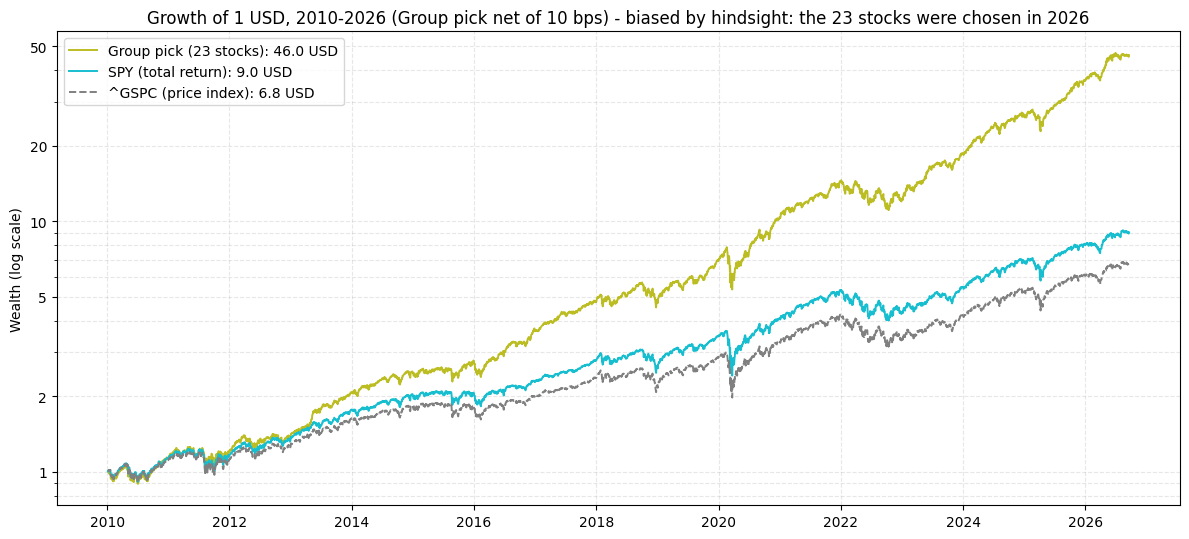

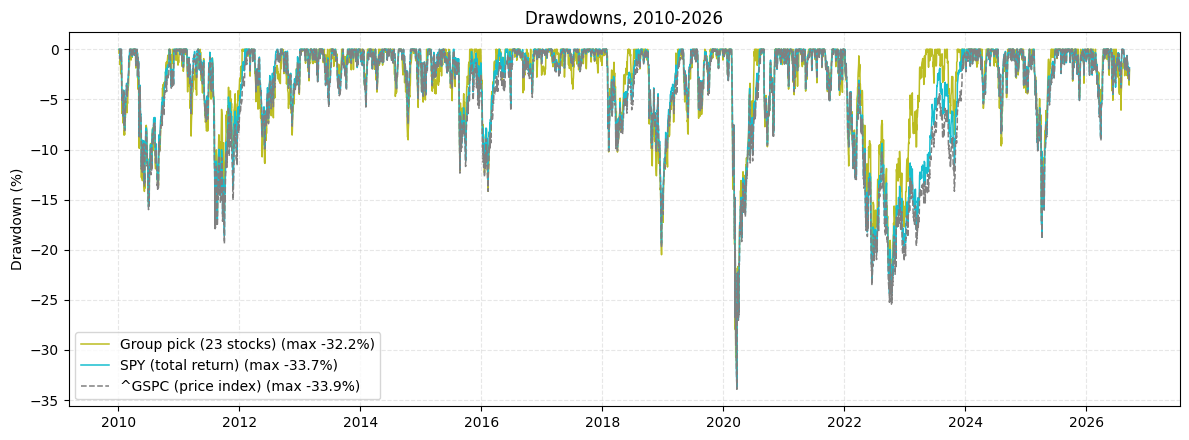

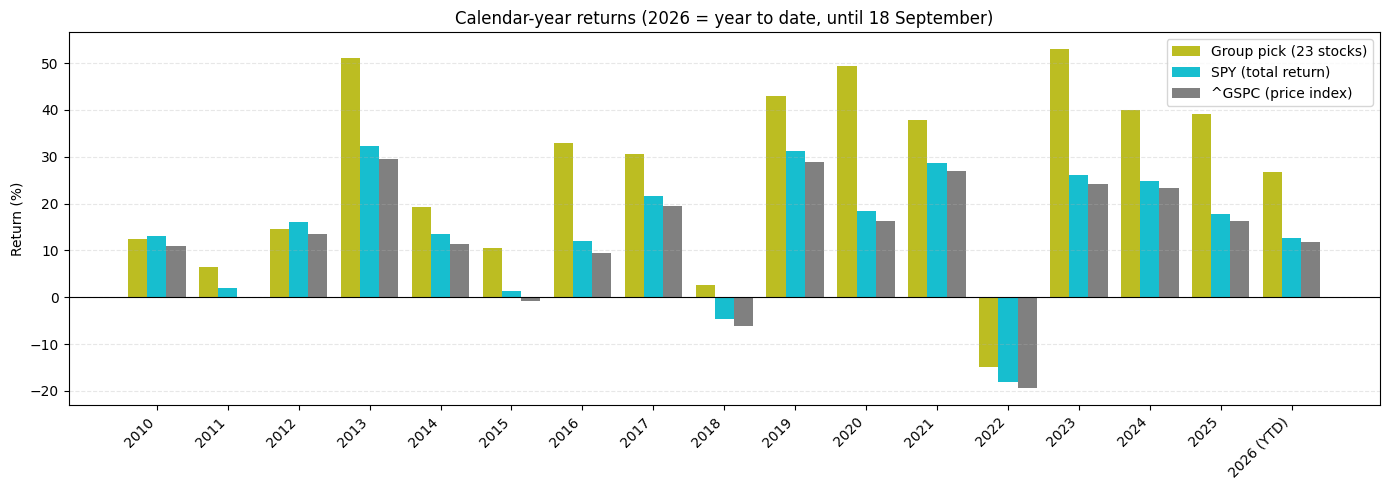

In [49]:
# Colour and line style of each series (the same in the three charts)
line_colour = {GROUP: colours[GROUP], 'SPY (total return)': colours['SPY (buy & hold)'], '^GSPC (price index)': 'grey'}
line_style = {GROUP: '-', 'SPY (total return)': '-', '^GSPC (price index)': '--'}

# Chart 1: growth of 1 USD (log scale: the same vertical distance = the same % change)
fig, ax = plt.subplots(figsize=(12, 5.5))
for name in full_series.columns:
    ax.plot((1 + full_series[name]).cumprod(), label=f'{name}: {fullsample_metrics.loc[name, "Final value of 1 USD"]:.1f} USD',
            linewidth=1.4, color=line_colour[name], linestyle=line_style[name])
ax.set_yscale('log')
ax.set_yticks([1, 2, 5, 10, 20, 50])                              # plain numbers instead of 10^0, 10^1
ax.set_yticklabels(['1', '2', '5', '10', '20', '50'])
ax.set_ylabel('Wealth (log scale)')
ax.set_title('Growth of 1 USD, 2010-2026 (Group pick net of 10 bps) - biased by hindsight: the 23 stocks were chosen in 2026')
ax.legend()
ax.grid(True, which='both', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/04_fullsample_wealth.png', dpi=150)
plt.show()

# Chart 2: drawdowns (fall from the previous peak; the initial value 1 counts as a peak)
fig, ax = plt.subplots(figsize=(12, 4.5))
for name in full_series.columns:
    wealth = (1 + full_series[name]).cumprod()
    drawdown = wealth / np.maximum(wealth.cummax(), 1.0) - 1
    ax.plot(100 * drawdown, label=f'{name} (max {fullsample_metrics.loc[name, "Max drawdown"]:.1%})', linewidth=1.1,
            color=line_colour[name], linestyle=line_style[name])
ax.set_ylabel('Drawdown (%)')
ax.set_title('Drawdowns, 2010-2026')
ax.legend(loc='lower left')
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/04_fullsample_drawdowns.png', dpi=150)
plt.show()

# Chart 3: calendar-year returns
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(calendar_year_returns))
for k, name in enumerate(full_series.columns):
    ax.bar(x + (k - 1) * 0.27, 100 * calendar_year_returns[name], width=0.27, label=name, color=line_colour[name])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(calendar_year_returns.index, rotation=45, ha='right')
ax.set_ylabel('Return (%)')
ax.set_title('Calendar-year returns (2026 = year to date, until 18 September)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('../figures/04_calendar_year_returns.png', dpi=150)
plt.show()

## 13. Saving the results (CSV + Excel)

- `04_experiment_design.csv` — periods and stocks of each experiment (makes it possible to reproduce and reuse them in the individual project);
- `04_metrics_by_experiment.csv` — all the metrics, by experiment and portfolio (the 8 strategies, the Group pick and SPY);
- `04_optimisation_failures.csv` — every optimisation that failed twice (with `ftol` 1e-10 and then 1e-8); on those rebalancings we used equal weights; it may be empty;
- `04_strategies_backtest.xlsx` — all the summary tables, one per sheet (**use this file to copy tables into the report**), including the
  tables of the Group pick and of the head-to-head comparison (`beats_group_pick`, `beats_spy`, `pairwise_*`, `universe23_*`,
  `fullsample_metrics`, `calendar_year_returns`); each table is also saved as `04_<name>.csv`.

In [50]:
# Note (Windows): close the .xlsx/.csv files in Excel before running this cell,
# otherwise Excel locks them and you get a "PermissionError".

design_csv = design.copy()
design_csv['Assets'] = [', '.join(asset_list) for asset_list in design_csv['Assets']]
results.to_csv('../results/04_metrics_by_experiment.csv', index=False, encoding='utf-8-sig')

# Failure log: the failures without a 'Run' came from the illustration in section 4
for failure in failure_log:
    if 'Run' not in failure:
        failure['Run'] = 'Illustration (section 4)'
failures_table = pd.DataFrame(failure_log, columns=['Run', 'Experiment', 'Rebalance date', 'Strategy', 'Message'])
print('Total number of optimisations that failed (all runs):', len(failures_table))

tables = {
    'universe_summary': universe_summary,
    'weights_illustration': illustration_weights,
    'illustration_characteristics': characteristics,
    'iv_vs_erc': rc_table,
    'median_metrics': medians,
    'dispersion': dispersion,
    'beats_ew': beats_ew,
    'beats_group_pick': beats_group_pick,
    'beats_spy': beats_spy,
    'rankings': rankings_table,
    'pairwise_sharpe': pairwise_sharpe,
    'pairwise_return': pairwise_return,
    'pairwise_max_drawdown': pairwise_max_drawdown,
    'pairwise_volatility': pairwise_volatility,
    'pairwise_sterling': pairwise_sterling,
    'pairwise_median_sharpe_diff': pairwise_median_sharpe_diff,
    'pairwise_avg_win_rate': pairwise_avg_win_rate,
    'sharpe_by_cost': sharpe_by_cost,
    'ranking_by_cost': ranking_by_cost,
    'rebalance_semiann_vs_quarterly': rebalance_comparison,
    'lambda_sensitivity': lambda_sensitivity,
    'sharpe_by_subperiod': sharpe_period,
    'sharpe_by_regime': sharpe_regime,
    'return_by_regime': return_regime,
    'avg_weight_by_stock': avg_weight,
    'subset_comparison': subset_comparison,
    'universe23_median_metrics': universe23_medians,
    'universe23_beats_group_pick': universe23_beats_group_pick,
    'universe23_pairwise_sharpe': universe23_pairwise_sharpe,
    'fullsample_metrics': fullsample_metrics,
    'calendar_year_returns': calendar_year_returns,
    'experiment_design': design_csv,
    'optimisation_failures': failures_table,
}

# Excel sheet names must have at most 31 characters and be unique
sheet_names = [name[:31] for name in tables.keys()]
assert len(sheet_names) == len(set(sheet_names)), 'Two sheet names are the same after cutting them to 31 characters'

with pd.ExcelWriter('../results/04_strategies_backtest.xlsx') as excel:
    for name, table in tables.items():
        table.to_excel(excel, sheet_name=name[:31])          # Excel accepts at most 31 characters in a sheet name
        table.to_csv(f'../results/04_{name}.csv', encoding='utf-8-sig')   # 'utf-8-sig' -> Excel displays λ and σ correctly

print('Results saved in ../results/')

Total number of optimisations that failed (all runs): 0


Results saved in ../results/


## 14. Limitations (for the robustness section of the report)

- **Survivorship and selection bias:** the 23 stocks were chosen based on their **current** market capitalisation (September 2026).
  They are companies that survived and grew (NVDA, AVGO, LLY, …), which **inflates the absolute returns of every strategy**
  (EW included) compared with what an investor would have obtained in real time. The comparisons **between** strategies are less affected,
  but strategies that concentrate on past winners (Max Sharpe, Markowitz) may benefit from this bias.
- **Selection bias of the Group pick:** the Group pick **is** this selection — it holds all the 23 winners chosen with hindsight in 2026.
  Its results against **SPY** (which held the whole index as it was at each date, including the companies that later shrank or left it) are
  therefore flattered, and its full-sample history (section 12) is not evidence that the pick would have beaten the market in real time.
  Its comparison with the 8 strategies is fairer, because they draw their stocks from the same 23, but the Group pick holds more stocks
  (23 vs 12), so part of the difference comes from the size of the universe — section 11 removes it by giving the strategies the same 23 stocks.
- **Overlapping experiments:** the 100 experiments share evaluation years → they are not independent; we look at medians,
  dispersion and consistency and not at significance tests.
- **Estimation:** 1-year historical means are very noisy (estimation error) — this mainly affects Markowitz and Max Sharpe.
- **Simplified costs:** fixed proportional cost, with no market impact and no taxes; SPY also has a management fee (~0.09%/year) that is already included in its price.
- **Risk-free rate:** the 3-year Treasury carries some interest-rate risk; a 3-month T-bill would be the "purer" alternative.
- **Universe:** only large-cap US stocks — the results may not apply to other asset classes.

## 15. Automatic summary of the results

This cell writes the main conclusions **with the numbers from this run** (so that the text of the report matches the tables).

In [51]:
portfolios_no_spy = list(strategies.keys()) + [GROUP]
med = medians.loc[portfolios_no_spy]          # medians from section 9.1: the 8 strategies and the Group pick

best_sharpe = med['Sharpe'].idxmax()
highest_return = med['Ann. return'].idxmax()
lowest_vol = med['Ann. volatility'].idxmin()
smallest_drawdown = med['Max drawdown'].idxmax()   # the drawdown is negative: the "largest" is the least bad
highest_turnover = med['Turnover (annual)'].idxmax()
most_concentrated = med['Effective N'].idxmin()

print('MAIN RESULTS (medians of the 100 experiments, net of 10 bps; the 8 strategies and the Group pick)')
print(f"- Highest Sharpe: {best_sharpe} ({med.loc[best_sharpe, 'Sharpe']:.2f}) | EW: {med.loc['EW', 'Sharpe']:.2f} | SPY: {medians.loc['SPY (buy & hold)', 'Sharpe']:.2f}")
print(f"- Highest return: {highest_return} ({med.loc[highest_return, 'Ann. return']:.1%}) | EW: {med.loc['EW', 'Ann. return']:.1%}")
print(f"- Lowest volatility: {lowest_vol} ({med.loc[lowest_vol, 'Ann. volatility']:.1%}) | EW: {med.loc['EW', 'Ann. volatility']:.1%}")
print(f"- Smallest maximum drawdown: {smallest_drawdown} ({med.loc[smallest_drawdown, 'Max drawdown']:.1%}) | EW: {med.loc['EW', 'Max drawdown']:.1%}")
print(f"- Highest turnover: {highest_turnover} ({med.loc[highest_turnover, 'Turnover (annual)']:.2f} per year) | EW: {med.loc['EW', 'Turnover (annual)']:.2f}")
print(f"- Most concentrated: {most_concentrated} (effective N = {med.loc[most_concentrated, 'Effective N']:.1f} out of {N_ASSETS})")

print('\n% OF EXPERIMENTS IN WHICH EACH PORTFOLIO BEATS EW (Sharpe | return | drawdown | volatility)')
for name in beats_ew.index:
    print(f"- {name:24s}: {beats_ew.loc[name, '% beats EW: Sharpe']:4.0f}% | {beats_ew.loc[name, '% beats EW: Ann. return']:4.0f}% | "
          f"{beats_ew.loc[name, '% beats EW: Max drawdown']:4.0f}% | {beats_ew.loc[name, '% beats EW: Ann. volatility']:4.0f}%")

print('\nGROUP PICK (23 stocks, equal weights)')
g = medians.loc[GROUP]
print(f"- Median Sharpe {g['Sharpe']:.2f} | return {g['Ann. return']:.1%} | volatility {g['Ann. volatility']:.1%} | "
      f"max drawdown {g['Max drawdown']:.1%} | turnover {g['Turnover (annual)']:.2f} per year")
group_position = list(rankings_table.index).index(GROUP) + 1
print(f"- Average rank by Sharpe: {rankings_table.loc[GROUP, 'Average rank']:.1f} (1 = best, {len(order)} = last) -> "
      f"position {group_position} of {len(order)} by average rank")
print(f"- Beats EW in {beats_ew.loc[GROUP, '% beats EW: Sharpe']:.0f}% of the experiments (Sharpe) | "
      f"{beats_ew.loc[GROUP, '% beats EW: Ann. return']:.0f}% (return) | {beats_ew.loc[GROUP, '% beats EW: Max drawdown']:.0f}% (drawdown) | "
      f"{beats_ew.loc[GROUP, '% beats EW: Ann. volatility']:.0f}% (volatility)")
print(f"- Beats SPY in {beats_spy.loc[GROUP, '% beats SPY: Sharpe']:.0f}% of the experiments (Sharpe) | "
      f"{beats_spy.loc[GROUP, '% beats SPY: Ann. return']:.0f}% (return) | {beats_spy.loc[GROUP, '% beats SPY: Max drawdown']:.0f}% (drawdown) | "
      f"{beats_spy.loc[GROUP, '% beats SPY: Ann. volatility']:.0f}% (volatility)")

print('\nHEAD-TO-HEAD (section 9.5, Sharpe ratio)')
best_head_to_head = pairwise_avg_win_rate['Avg % won: Sharpe'].idxmax()
line = f"- Highest average % of head-to-heads won: {best_head_to_head} ({pairwise_avg_win_rate.loc[best_head_to_head, 'Avg % won: Sharpe']:.0f}%)"
if best_head_to_head != GROUP:          # show the Group pick separately only when it is not already the best
    line = line + f" | Group pick: {pairwise_avg_win_rate.loc[GROUP, 'Avg % won: Sharpe']:.0f}%"
if best_head_to_head != 'EW':
    line = line + f" | EW: {pairwise_avg_win_rate.loc['EW', 'Avg % won: Sharpe']:.0f}%"
print(line)
print(f"- The Group pick beats {int(pairwise_avg_win_rate.loc[GROUP, 'Rivals beaten in > 50% (Sharpe)'])} of the other {len(order) - 1} "
      f"portfolios in more than 50% of the experiments")
for name in portfolios_no_spy:
    if name != GROUP:
        print(f"  - Group pick vs {name:20s}: wins {pairwise_sharpe.loc[GROUP, name]:3.0f}% | median Sharpe difference {pairwise_median_sharpe_diff.loc[GROUP, name]:+.2f}")

print('\nTHE 23-STOCK UNIVERSE (section 11: the strategies with the same 23 stocks as the Group pick)')
u23 = universe23_medians.drop(index='SPY (buy & hold)')
best23 = u23['Sharpe'].idxmax()
print(f"- Best portfolio by median Sharpe: {best23} ({u23.loc[best23, 'Sharpe']:.2f}) | Group pick (= EW on 23 stocks): {u23.loc[GROUP, 'Sharpe']:.2f}")
print(f"- Strategies that beat the Group pick in more than 50% of the experiments (Sharpe): "
      f"{universe23_beats_group_pick.index[universe23_beats_group_pick['% beats Group pick: Sharpe'] > 50].tolist()}")

print('\nFULL SAMPLE 2010-2026 (section 12; biased by hindsight)')
print(f"- CAGR: Group pick {fullsample_metrics.loc[GROUP, 'CAGR']:.1%} vs SPY {fullsample_metrics.loc['SPY (total return)', 'CAGR']:.1%} "
      f"vs ^GSPC {fullsample_metrics.loc['^GSPC (price index)', 'CAGR']:.1%} | Sharpe {fullsample_metrics.loc[GROUP, 'Sharpe']:.2f} vs "
      f"{fullsample_metrics.loc['SPY (total return)', 'Sharpe']:.2f} | max drawdown {fullsample_metrics.loc[GROUP, 'Max drawdown']:.1%} vs "
      f"{fullsample_metrics.loc['SPY (total return)', 'Max drawdown']:.1%}")

print('\nROBUSTNESS')
changed = ranking_by_cost[ranking_by_cost.nunique(axis=1) > 1].index.tolist()
print(f'- Portfolios that change position in the ranking between 0 and 50 bps: {len(changed)} out of {len(ranking_by_cost)} {changed}')
print(f"- Best portfolio (median Sharpe) with quarterly rebalancing: {rebalance_comparison['Sharpe (quarterly)'].idxmax()}")
for version in ['12 stocks (main)', '12 stocks (new draw)', 'All eligible stocks']:
    print(f"- Best portfolio with '{version}': {subset_comparison[(version, 'Median Sharpe')].idxmax()}")
print(f'- Optimisations that failed (all runs): {len(failures_table)}')
print(f'- Optimisations that needed a second attempt (ftol = 1e-8): {len(retry_log)} '
      f'(of which failed again and used equal weights: {len(failures_table)})')

MAIN RESULTS (medians of the 100 experiments, net of 10 bps; the 8 strategies and the Group pick)
- Highest Sharpe: EW (1.81) | EW: 1.81 | SPY: 1.13
- Highest return: Markowitz (λ=3) (39.8%) | EW: 31.2%
- Lowest volatility: GMV (12.8%) | EW: 16.9%
- Smallest maximum drawdown: Inverse vol (-9.8%) | EW: -11.1%
- Highest turnover: Markowitz (λ=3) (2.21 per year) | EW: 0.27
- Most concentrated: Markowitz (λ=3) (effective N = 1.5 out of 12)

% OF EXPERIMENTS IN WHICH EACH PORTFOLIO BEATS EW (Sharpe | return | drawdown | volatility)
- Markowitz (λ=3)         :   21% |   57% |    9% |    1%
- GMV                     :   31% |   26% |   65% |   98%
- Max Sharpe              :   34% |   54% |   27% |   19%
- Inverse vol             :   47% |   27% |   87% |  100%
- Risk parity (ERC)       :   51% |   26% |   86% |  100%
- Most diversified        :   47% |   39% |   61% |   75%
- Max decorrelation       :   41% |   64% |   26% |   27%
- Group pick (23 stocks)  :   62% |   49% |   55% |   56%
- S

## 16. Conclusions and recommendation (guide for the report)

> The numbers below come from this run (real FRED DGS3 series, extracted 8 October 2026); the exact values are in the automatic summary
> (section 15) and in the tables above ("≈" = rounded). Ten portfolios are compared: the 8 strategies of the brief, the **Group pick**
> (the group's 23 stocks in equal weights) and **SPY**.

**1. Among the 8 strategies of the brief, equally weighted is very hard to beat.** No optimised strategy beats EW on Sharpe ratio consistently:
the best ones (ERC, inverse vol, most diversified) beat it in only ≈ 47–51% of the experiments; ERC (≈ 1.80) and inverse vol (≈ 1.78) have a
median Sharpe ratio practically equal to that of EW (≈ 1.81), and most diversified is ≈ 0.1 below (≈ 1.70).
With a new draw of stocks, or with all the stocks (section 10.6), the order among these strategies changes → **the differences between them are not robust**.

**2. On a risk-adjusted basis (Sharpe ratio), the Group pick (our 23 stocks, equal weights) is the most consistent portfolio of the backtest.**
It differs from EW only in the universe (all 23 stocks instead of 12 random ones), and:
- it has the **best average rank** by Sharpe ratio (≈ 3.9 out of 10; 1st in 33% of the experiments, in the top 3 in 50%) and wins the
  **most head-to-head comparisons on the Sharpe ratio**: it beats **each** of the other 9 portfolios in more than half of the experiments — from
  ≈ 56% against ERC (a narrow margin: median Sharpe difference ≈ +0.08) and ≈ 62% against EW to ≈ 79% against Markowitz and ≈ 92% against SPY.
  On the other metrics it does not dominate: on return it beats 5 of the 9 in more than half of the experiments, on volatility and on drawdown only 4;
- its median return is ≈ 36% (only Markowitz has more, ≈ 40%), with a median volatility of ≈ 16% (EW ≈ 17%) and the same low turnover as EW
  (≈ 0.3 per year, a cost of ≈ 4 bps per year). The column medians exaggerate the gap with EW: in the same experiment the Group pick earns
  more than EW in only 49% of the cases (median paired return difference ≈ −0.5 percentage points; the mean returns are practically equal,
  ≈ 32% for both);
- **but its median Sharpe ratio (≈ 1.70) is not the highest** (EW ≈ 1.81, ERC ≈ 1.80). The median of each column and the comparison inside
  each experiment answer different questions: in the same experiment the Group pick beats EW in 62% of the cases, but the median Sharpe
  difference is only ≈ +0.08. Its edge is **consistency** (the highest 25th percentile of the Sharpe ratio, ≈ 0.86 against ≈ 0.72 for EW),
  not a large advantage;
- its edge over EW comes from **diversification** (23 stocks instead of 12), not from better stocks: EW's 12 stocks are drawn at random from
  the same 23, so on average both hold the same winners. What the Group pick gains is a lower volatility (lower than EW in 56% of the experiments)
  and a steadier Sharpe ratio. The **selection bias** (the 23 stocks are today's largest companies) inflates EW and the Group pick alike, and
  matters mainly when they are compared with SPY (points 11 and 12, section 14).

**3. Head-to-head comparison of all portfolios (section 9.5).** By Sharpe ratio there is a clear top group — Group pick (≈ 68% of the
head-to-head comparisons won), ERC (≈ 65%), EW (≈ 61%), inverse vol (≈ 59%), most diversified (≈ 58%) and max decorrelation (≈ 55%) — and a bottom
group — Max Sharpe (≈ 40%), GMV (≈ 38%), Markowitz (≈ 29%) and SPY (≈ 27%). On risk the order changes: GMV has lower volatility in
≈ 81–100% of its comparisons, and ERC and inverse vol have lower volatility and smaller drawdowns than EW and the Group pick in ≈ 72–100% of the
experiments. No portfolio wins on every metric → the choice depends on the investor's objective.

**4. Low-risk family (GMV, inverse vol, risk parity).** They reduce volatility relative to EW in ≈ 98–100% of the experiments
and the maximum drawdown in ≈ 65–87%, but they earn less (return above EW in only ≈ 26–27% of the experiments).
Inverse vol and ERC do this with turnover similar to that of EW (≈ 0.3 per year) and well-diversified portfolios (effective N ≈ 11 out of 12).
GMV is more concentrated (effective N ≈ 4) and has the lowest median return.

**5. Strategies that use expected returns (Markowitz λ = 3 and Max Sharpe).** Very concentrated portfolios
(Markowitz: effective N ≈ 1.5 and average maximum weight ≈ 77%), turnover ≈ 8 times that of EW, more volatility and larger drawdowns.
Markowitz has the highest median return, but also the largest dispersion (standard deviation of the annual return ≈ 0.68 against ≈ 0.22 for EW)
and it only has a smaller drawdown than EW in ≈ 9% of the experiments. This is the effect of **estimation error**: 1-year means
point to the stocks that rose the most, which do not always keep rising. A higher λ (5) reduces risk, but does not solve the concentration.

**6. Most diversified and Max decorrelation** sit halfway: more return than the low-risk family,
but turnover ≈ 3 times that of EW and moderate concentration (effective N ≈ 6–7).

**7. On our own 23 stocks, would an optimiser have beaten our equal-weight pick? Not clearly (section 11).** With the same 23 stocks,
most diversified (median Sharpe ≈ 1.85) and ERC (≈ 1.75) have a higher median Sharpe ratio than the Group pick (≈ 1.70), but they beat it in only
≈ 52% and ≈ 54% of the experiments (the median paired Sharpe difference is only ≈ +0.02 and ≈ +0.01) — close to a coin toss. They do it with **less risk**
(ERC: lower volatility in 100% and a smaller drawdown in ≈ 93% of the experiments) and **less return** (ERC earns more than the Group pick in only
≈ 23% of them). Markowitz, Max Sharpe and Max decorrelation earn more than the Group pick in ≈ 60–63% of the experiments, but have a lower Sharpe
ratio in ≈ 58–79% of them. → The optimisers can **reduce the risk** of our pick, but they do not add risk-adjusted return in a robust way.

**8. Transaction costs.** With 10 bps the annual cost is small for all of them (median ≈ 0.3% per year for Markowitz, the most expensive strategy;
≈ 1% in the worst experiment; ≈ 4 bps for EW, ERC and the Group pick) and the ranking by Sharpe ratio **practically does not change** between
0 and 50 bps: only portfolios with an almost identical median Sharpe ratio swap places — in this run, most diversified and the Group pick
(≈ 1.707 against ≈ 1.705 at 0 bps). In this universe of very liquid stocks, what separates the strategies is estimation error, not costs.

**9. Quarterly rebalancing** increases turnover by ≈ 30–45% without consistently improving performance (some medians go up, others down) →
**semi-annual** rebalancing is enough. With quarterly rebalancing the Group pick still beats EW in ≈ 62% of the experiments.

**10. Dependence on the period.** In the years in which SPY fell (12 experiments), EW and the low-risk strategies hardly lost anything
(median return ≈ 0% to +4%; the Group pick ≈ +2%), whereas Markowitz was the only strategy with a negative median return (≈ −5%, close to the ≈ −5% of SPY).
Markowitz also gets much worse in the 2021–2026 sub-period. The Group pick has the highest median Sharpe ratio in 2012–2016 (≈ 1.96) and 2017–2020
(≈ 2.25), but not in 2021–2026 (≈ 1.62, below ERC's ≈ 1.72), and in the years in which SPY fell its median Sharpe ratio (≈ 0.06) is below that of EW,
inverse vol and ERC (≈ 0.14–0.17) → it is **less defensive** than the low-risk strategies. The results vary a lot between experiments — that is why
we look at medians and percentages and not at a single experiment.

**11. SPY.** SPY has the lowest median Sharpe ratio (≈ 1.13) and one of the lowest returns (only GMV earns less), but it has the **smallest median drawdown
of all** (≈ −9%) and a low volatility (≈ 14%; only GMV has less). Every portfolio built from the 23 stocks earns more than SPY in most experiments
(from ≈ 51% for GMV to ≈ 96% for the Group pick). This mainly reflects the **selection bias** of the universe (the 23 stocks are the largest **today**)
and not a real advantage of the strategies over the market.

**12. The Group pick over the full sample 2010–2026 (section 12)** turned 1 USD into ≈ 46 USD (CAGR ≈ 26% against ≈ 14% for SPY and ≈ 12% for ^GSPC),
with a similar maximum drawdown (≈ −32% against ≈ −34%), and beat SPY in 15 of the 17 calendar years. **This is not evidence that the pick would have
beaten the market in real time**: the 23 stocks were chosen in 2026, with hindsight (look-ahead and survivorship bias). It only describes what the pick
did; the fair evidence is the out-of-sample experiments above.

### Suggested recommendation (for the group to decide)

- **Target investor:** a long-term investor with an allocation to US equities who wants to **reduce volatility and drawdowns**
  with low costs and low complexity (for example, a pension fund or a prudent private investor).
- **Recommendation:** **risk parity (ERC)** — or inverse vol, which is even simpler. They have a Sharpe ratio similar to EW,
  lower volatility in practically every experiment, smaller drawdowns in the large majority of them, low turnover and stable weights.
  The cost is a lower return than EW (≈ 5 percentage points per year at the median: ≈ 26% against ≈ 31%). Against the Group pick,
  ERC has lower volatility in ≈ 86% and a smaller drawdown in ≈ 77% of the experiments, but a lower return in ≈ 70% of them.
- For those who want **more return** and accept the volatility of equities, **equal weights** are the simplest and most robust choice
  (nothing to estimate). On our 23 stocks this is the **Group pick**: a return similar to EW on 12 random stocks (higher in 49% of the experiments),
  with lower volatility in 56% and a higher Sharpe ratio in 62% of them, the best average rank and the most head-to-head wins on the Sharpe ratio,
  turnover ≈ 0.3 per year, and no optimiser beats it robustly on the same stocks (section 11). When presenting it,
  we must say clearly that its advantage over SPY is inflated by the way the 23 stocks were chosen (section 14).
  Markowitz and Max decorrelation have a higher median return than EW (≈ 40% and ≈ 33% against ≈ 31%), but with more volatility, more dispersion
  across experiments and results that depend on the stocks drawn (section 10.6).
- **We do not recommend** unconstrained Markowitz or Max Sharpe: extreme concentration, a lot of turnover and unstable results.
- **When to reconsider:** (i) if the correlations between stocks change a lot (ERC depends on the covariance matrix);
  (ii) in markets that are very concentrated in a few winning stocks, where EW and ERC hold little weight in those stocks;
  (iii) if the costs or the universe are very different (e.g. illiquid stocks); (iv) if weight limits
  or a *shrinkage* covariance are added (extensions A and B of the brief), which may make Markowitz and Max Sharpe more stable;
  (v) for the Group pick, if the stocks are chosen with the information available at the start of each period (e.g. the largest stock of each
  sector at that date) — this removes the selection bias and is the real test of a "pick the leaders" rule.